<a href="https://colab.research.google.com/github/chime08/Biointerphase-1D-forecasting-harmful-algal-bloom-risk/blob/main/Copy_of_the_actual_final_%26_update_copy_of_Biointerphase_D_Datasets_(10).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# SETUP: Data folder and dataset list
import os
import shutil
import urllib.parse
import urllib.request
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

DATA_DIR = "/content/drive/MyDrive/BiointerphaseD /"    # outputs are saved under this folder too
REPO_DATA_URL = ("https://github.com/Break-Through-Tech/"
                 "Biointerphase-1D-forecasting-harmful-algal-bloom-risk/raw/main/data/")

DATASETS = {
    'habsos':         'habsos_cellcounts.csv',
    'cyanotoxins':    'florida_cyanotoxins_2015-01-01_to_2026-06-17.csv',
    'bradenton_temp': 'bradentonFL_tempData.csv',
    'sarasota_wind':  'Sarasota_Wind&Temp.csv',
    'mote_temp':      'MoteMarine_BottomTemp.csv',
    'nutrients':      'NutrientsFL_2006_2025.csv',
    # Chlorophyll files in priority order: (1) the overview's product, NOAA multi-sensor DINEOF
    # gap-filled 2 km, 2020-2026; (2) the older download, 2010 to 2022-05, used only for dates
    # the first file doesn't cover
    'chlorophyll':    ['ChlorophyllaConcentrationSarasota.csv',
                       'ChlorophyllaConcentrationSarasota_Dataset2.csv'],
}

def is_real_file(path):
    return os.path.exists(path) and os.path.getsize(path) > 10_000

def ensure_file(name):
    path = os.path.join(DATA_DIR, name)
    if is_real_file(path):
        return path
    print(f"  downloading {name} from the repo (one time, may take a few minutes) ...")
    with urllib.request.urlopen(REPO_DATA_URL + urllib.parse.quote(name)) as r, open(path + '.part', 'wb') as f:
        shutil.copyfileobj(r, f, length=1 << 20)
    os.replace(path + '.part', path)
    return path

print("=== Dataset check ===")
for key, names in DATASETS.items():
    for name in ([names] if isinstance(names, str) else names):
        try:
            p = ensure_file(name)
            print(f"✓ {key:15s} {name} ({os.path.getsize(p) / 1e6:,.0f} MB)")
        except Exception as e:
            print(f"✗ {key:15s} {name}: not available ({e})")

os.chdir(DATA_DIR)


Mounted at /content/drive
=== Dataset check ===
✓ habsos          habsos_cellcounts.csv (33 MB)
✓ cyanotoxins     florida_cyanotoxins_2015-01-01_to_2026-06-17.csv (73 MB)
✓ bradenton_temp  bradentonFL_tempData.csv (0 MB)
✓ sarasota_wind   Sarasota_Wind&Temp.csv (4 MB)
✓ mote_temp       MoteMarine_BottomTemp.csv (2 MB)
✓ nutrients       NutrientsFL_2006_2025.csv (74 MB)
✓ chlorophyll     ChlorophyllaConcentrationSarasota.csv (233 MB)
✓ chlorophyll     ChlorophyllaConcentrationSarasota_Dataset2.csv (319 MB)


In [ ]:
# TASK 1: Quick check that the raw files load
import pandas as pd

folder = DATA_DIR

temp        = pd.read_csv(folder + "bradentonFL_tempData.csv")
cyanotoxins = pd.read_csv(folder + "florida_cyanotoxins_2015-01-01_to_2026-06-17.csv")
habsos      = pd.read_csv(folder + "habsos_cellcounts.csv")
bottom_temp = pd.read_csv(folder + "MoteMarine_BottomTemp.csv")
nutrients   = pd.read_csv(folder + "NutrientsFL_2006_2025.csv")
wind_temp   = pd.read_csv(folder + "Sarasota_Wind&Temp.csv")

/tmp/ipykernel_1745/1601553985.py:7: DtypeWarning: Columns (48) have mixed types. Specify dtype option on import or set low_memory=False.
  cyanotoxins = pd.read_csv(folder + "florida_cyanotoxins_2015-01-01_to_2026-06-17.csv")
/tmp/ipykernel_1745/1601553985.py:8: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  habsos      = pd.read_csv(folder + "habsos_cellcounts.csv")
/tmp/ipykernel_1745/1601553985.py:11: DtypeWarning: Columns (1,2,4,6,8,10,12,14) have mixed types. Specify dtype option on import or set low_memory=False.
  wind_temp   = pd.read_csv(folder + "Sarasota_Wind&Temp.csv")


In [ ]:
# TASK 1: Set the working folder
import os
os.chdir(DATA_DIR)   # DATA_DIR is defined in SETUP

In [ ]:
# TASK 2: Inventory every dataset (row counts and date ranges)

import os
import pandas as pd

csv_files = [
    "habsos_cellcounts.csv",
    "florida_cyanotoxins_2015-01-01_to_2026-06-17.csv",
    "bradentonFL_tempData.csv",
    "Sarasota_Wind&Temp.csv",
    "MoteMarine_BottomTemp.csv",
    "NutrientsFL_2006_2025.csv",
    "ChlorophyllaConcentrationSarasota.csv",            # overview product, 2020-2026
    "ChlorophyllaConcentrationSarasota_Dataset2.csv",   # older download, 2010 to 2022-05
]

for file in csv_files:
    if os.path.exists(file):

        skip = [1] if file == "MoteMarine_BottomTemp.csv" or file.startswith("ChlorophyllaConcentration") else None
        df = pd.read_csv(file, skiprows=skip, low_memory=False)

        print(f"--- {file} ---")
        print("Row count:", len(df))

        # Find the date column (names differ across datasets)
        date_col = next((col for col in ['time', 'sample_date', 'date', 'DATE', 'SampleDate'] if col in df.columns), None)

        if date_col:
            print(f"Date range ({date_col}):", df[date_col].min(), "to", df[date_col].max())
        else:
            print("Date column name:", [c for c in df.columns if 'date' in c.lower() or 'time' in c.lower()])

        print()

--- habsos_cellcounts.csv ---
Row count: 219152
Date column name: ['SAMPLE_DATE']

--- florida_cyanotoxins_2015-01-01_to_2026-06-17.csv ---
Row count: 98884
Date column name: ['Activity_StartDate', 'Activity_StartTime', 'Activity_StartTimeZone', 'LabInfo_AnalysisStartDate', 'LabInfo_AnalysisStartTime', 'LabInfo_AnalysisStartTimeZone', 'LastChangeDate']

--- bradentonFL_tempData.csv ---
Row count: 4018
Date column name: []

--- Sarasota_Wind&Temp.csv ---
Row count: 41286
Date range (time): 2022-07-11T21:53:00Z to UTC

--- MoteMarine_BottomTemp.csv ---
Row count: 31729
Date range (time): 2020-08-13T15:00:00Z to 2025-03-26T15:00:00Z

--- NutrientsFL_2006_2025.csv ---
Row count: 514087
Date column name: ['Activity_Start_Date', 'Activity_Start_Time']

--- ChlorophyllaConcentrationSarasota.csv ---
Row count: 4202008
Date range (time): 2020-06-15T12:00:00Z to 2026-09-05T12:00:00Z

--- ChlorophyllaConcentrationSarasota_Dataset2.csv ---
Row count: 7010094
Date range (time): 2010-01-01T12:00:00Z

In [ ]:
# TASK 2: Preview each dataset's columns to plan standardization

import os
import pandas as pd

files = {
    "habsos": "habsos_cellcounts.csv",
    "cyanotoxins": "florida_cyanotoxins_2015-01-01_to_2026-06-17.csv",
    "bradenton_temp": "bradentonFL_tempData.csv",
    "sarasota_wind": "Sarasota_Wind&Temp.csv",
    "mote_temp": "MoteMarine_BottomTemp.csv",
    "nutrients": "NutrientsFL_2006_2025.csv",
    "chlorophyll": "ChlorophyllaConcentrationSarasota.csv",
    "chlorophyll_older": "ChlorophyllaConcentrationSarasota_Dataset2.csv",
}

for name, path in files.items():
    if os.path.exists(path):
        # ERDDAP files (Mote, chlorophyll) have a units row under the header
        skip = [1] if name in ["mote_temp", "chlorophyll", "chlorophyll_older"] else None
        df = pd.read_csv(path, nrows=2, skiprows=skip, low_memory=False)

        print(f"=== {name} ({path}) ===")
        print("All Columns:", list(df.columns))
        print()

=== habsos (habsos_cellcounts.csv) ===
All Columns: ['OBJECTID', 'DESCRIPTION', 'LATITUDE', 'LONGITUDE', 'STATE_ID', 'SAMPLE_DATE', 'SAMPLE_DEPTH', 'GENUS', 'SPECIES', 'CATEGORY', 'CELLCOUNT', 'CELLCOUNT_UNIT', 'CELLCOUNT_QA', 'SALINITY', 'SALINITY_UNIT', 'SALINITY_QA', 'WATER_TEMP', 'WATER_TEMP_UNIT', 'WATER_TEMP_QA', 'WIND_DIR', 'WIND_DIR_UNIT', 'WIND_DIR_QA', 'WIND_SPEED', 'WIND_SPEED_UNIT', 'WIND_SPEED_QA', 'QA_COMMENT']

=== cyanotoxins (florida_cyanotoxins_2015-01-01_to_2026-06-17.csv) ===
All Columns: ['Org_Identifier', 'Org_FormalName', 'Project_Identifier', 'Location_Identifier', 'Location_Name', 'Location_Type', 'Location_State', 'Location_HUCEightDigitCode', 'Location_HUCTwelveDigitCode', 'Location_TribalLand', 'Location_Latitude', 'Location_Longitude', 'Activity_ActivityIdentifier', 'Activity_TypeCode', 'Activity_Media', 'Activity_MediaSubdivision', 'ActivityBiological_AssemblageSa', 'Activity_StartDate', 'Activity_StartTime', 'Activity_StartTimeZone', 'Activity_DepthHeight

In [ ]:
# TASK 3: Standardize date, coordinate, and station ID columns across all sources

import os
import pandas as pd

os.chdir(DATA_DIR)

standardized_dfs = {}

# --- 3a. HABSOS ---
if os.path.exists("habsos_cellcounts.csv"):
    df = pd.read_csv("habsos_cellcounts.csv", low_memory=False)
    df['datetime_utc'] = pd.to_datetime(df['SAMPLE_DATE'], errors='coerce', utc=True)
    df['date'] = df['datetime_utc'].dt.date
    df = df.rename(columns={'LATITUDE': 'latitude', 'LONGITUDE': 'longitude', 'OBJECTID': 'station_id'})
    standardized_dfs['habsos'] = df

# --- 3b. Cyanotoxins ---
if os.path.exists("florida_cyanotoxins_2015-01-01_to_2026-06-17.csv"):
    df = pd.read_csv("florida_cyanotoxins_2015-01-01_to_2026-06-17.csv", low_memory=False)
    # Activity_StartDate is in epoch milliseconds (read as nanoseconds, it shows up as 1970-01-01)
    raw = df['Activity_StartDate']
    as_num = pd.to_numeric(raw, errors='coerce')
    df['datetime_utc'] = pd.to_datetime(as_num, unit='ms', errors='coerce', utc=True)
    text_rows = as_num.isna() & raw.notna()          # rows stored as date text instead
    df.loc[text_rows, 'datetime_utc'] = pd.to_datetime(raw[text_rows], errors='coerce', utc=True)
    df['date'] = df['datetime_utc'].dt.date
    print("Cyanotoxin date range:", df['datetime_utc'].min(), "to", df['datetime_utc'].max())
    df = df.rename(columns={'Location_Latitude': 'latitude', 'Location_Longitude': 'longitude',
                            'Location_Identifier': 'station_id'})
    standardized_dfs['cyanotoxins'] = df

# --- 3c. Bradenton temperature and precipitation ---
if os.path.exists("bradentonFL_tempData.csv"):
    df = pd.read_csv("bradentonFL_tempData.csv")
    df.columns = df.columns.str.strip()
    df['date'] = pd.to_datetime(df[['YEAR', 'MONTH', 'DAY']].rename(columns={'YEAR':'year', 'MONTH':'month', 'DAY':'day'}), errors='coerce').dt.date
    df['station_id'] = df['COOPID'].astype(str)
    standardized_dfs['bradenton_temp'] = df

# --- 3d. Sarasota wind and weather ---
if os.path.exists("Sarasota_Wind&Temp.csv"):
    df = pd.read_csv("Sarasota_Wind&Temp.csv", skiprows=[1], low_memory=False)
    df['datetime_utc'] = pd.to_datetime(df['time'], errors='coerce', utc=True)
    df['date'] = df['datetime_utc'].dt.date
    df['station_id'] = 'KSRQ'
    standardized_dfs['sarasota_wind'] = df

# --- 3e. Mote Marine bottom temperature ---
if os.path.exists("MoteMarine_BottomTemp.csv"):
    df = pd.read_csv("MoteMarine_BottomTemp.csv", skiprows=[1], low_memory=False)
    df['datetime_utc'] = pd.to_datetime(df['time'], errors='coerce', utc=True)
    df['date'] = df['datetime_utc'].dt.date
    df['latitude'] = pd.to_numeric(df['latitude'], errors='coerce')
    df['longitude'] = pd.to_numeric(df['longitude'], errors='coerce')
    df['station_id'] = 'MOTE_BOTTOM'
    standardized_dfs['mote_temp'] = df

# --- 3f. Nutrients ---
if os.path.exists("NutrientsFL_2006_2025.csv"):
    df = pd.read_csv("NutrientsFL_2006_2025.csv", low_memory=False)
    df['datetime_utc'] = pd.to_datetime(df['Activity_Start_Date'], errors='coerce', utc=True)
    df['date'] = df['datetime_utc'].dt.date
    df = df.rename(columns={'Actual_StationID': 'station_id'})
    standardized_dfs['nutrients'] = df

# --- 3g. Chlorophyll ---
# Load every available chlorophyll file, tagged with its priority. TASK 7 compares the files
# where they overlap and keeps one file per date.
def load_chlorophyll(path, priority):
    df = pd.read_csv(path, skiprows=[1], low_memory=False)           # ERDDAP files have a units row
    time_col = next(c for c in ['time', 'time_utc', 'date'] if c in df.columns)
    df['datetime_utc'] = pd.to_datetime(df[time_col], errors='coerce', utc=True)
    df['date'] = df['datetime_utc'].dt.date
    df['latitude'] = pd.to_numeric(df.get('latitude', df.get('lat')), errors='coerce')
    df['longitude'] = pd.to_numeric(df.get('longitude', df.get('lon')), errors='coerce')
    value_col = next(c for c in df.columns if any(k in c.lower() for k in ['chlor', 'chl'])
                     and not any(k in c.lower() for k in ['qc', 'flag', 'error', 'std']))
    df['chlor_a'] = pd.to_numeric(df[value_col], errors='coerce')     # same column name for every file
    df['source_file'] = os.path.basename(path)
    df['source_priority'] = priority
    df['station_id'] = 'CHLOROPHYLL_SARASOTA'
    print(f"Chlorophyll: {path} | value column '{value_col}' | {len(df):,} rows | "
          f"{df['datetime_utc'].min()} to {df['datetime_utc'].max()}")
    return df[['datetime_utc', 'date', 'latitude', 'longitude', 'chlor_a',
               'source_file', 'source_priority', 'station_id']]

chl_frames = [load_chlorophyll(name, k) for k, name in enumerate(DATASETS['chlorophyll'])
              if is_real_file(name)]
if chl_frames:
    standardized_dfs['chlorophyll'] = pd.concat(chl_frames, ignore_index=True)
    del chl_frames

# --- 3h. Check the standardized fields ---
for name, df in standardized_dfs.items():
    print(f"=== {name} ===")
    cols = [c for c in ['date', 'datetime_utc', 'latitude', 'longitude', 'station_id'] if c in df.columns]
    print("Standardized fields:", cols)
    print(df[cols].dropna(subset=['date']).head(2))
    print()

# Make sure no dataset was skipped
expected = ['habsos', 'cyanotoxins', 'bradenton_temp', 'sarasota_wind', 'mote_temp', 'nutrients', 'chlorophyll']
missing = [k for k in expected if k not in standardized_dfs]
print("Missing datasets:", missing if missing else "none, all 7 loaded!")

Cyanotoxin date range: 2015-06-01 03:40:00+00:00 to 2025-01-02 03:53:20+00:00
Chlorophyll: ChlorophyllaConcentrationSarasota.csv | value column 'chlor_a' | 4,202,008 rows | 2020-06-15 12:00:00+00:00 to 2026-09-05 12:00:00+00:00
Chlorophyll: ChlorophyllaConcentrationSarasota_Dataset2.csv | value column 'chlor_a' | 7,010,094 rows | 2010-01-01 12:00:00+00:00 to 2022-05-31 12:00:00+00:00
=== habsos ===
Standardized fields: ['date', 'datetime_utc', 'latitude', 'longitude', 'station_id']
         date              datetime_utc  latitude  longitude  station_id
0  1953-08-19 1953-08-19 00:00:00+00:00  26.93450   -82.3535           1
1  1953-08-26 1953-08-26 00:00:00+00:00  26.13163   -81.8063           2

=== cyanotoxins ===
Standardized fields: ['date', 'datetime_utc', 'latitude', 'longitude', 'station_id']
         date              datetime_utc   latitude  longitude  \
0  2015-06-01 2015-06-01 03:40:00+00:00  27.887829 -82.557660   
1  2015-06-02 2015-06-02 04:40:00+00:00  27.906991 -82.480

In [ ]:
# TASK 3: List the standardized datasets
print(standardized_dfs.keys())

dict_keys(['habsos', 'cyanotoxins', 'bradenton_temp', 'sarasota_wind', 'mote_temp', 'nutrients', 'chlorophyll'])


In [ ]:
# TASK 4: Label HABSOS samples as no_bloom / at_risk / bloom
# Thresholds in cells/L: < 1,000 no_bloom; 1,000-10,000 at_risk; > 10,000 bloom.
# Rows without a cell count are dropped rather than labeled no_bloom.
import numpy as np

def categorize_habsos(count):
    if count < 1000:
        return 'no_bloom'
    elif count <= 10000:
        return 'at_risk'
    else:
        return 'bloom'

df_habsos = standardized_dfs['habsos']
df_habsos['CELLCOUNT'] = pd.to_numeric(df_habsos['CELLCOUNT'], errors='coerce')
n_missing = int(df_habsos['CELLCOUNT'].isna().sum())
df_habsos = df_habsos.dropna(subset=['CELLCOUNT']).copy()
df_habsos['bloom_label'] = df_habsos['CELLCOUNT'].apply(categorize_habsos)
standardized_dfs['habsos'] = df_habsos      # later cells read from here
print(f"HABSOS: dropped {n_missing:,} rows with no cell count; {len(df_habsos):,} rows labeled")


HABSOS: dropped 0 rows with no cell count; 219,152 rows labeled


In [ ]:
# TASK 4: Check the HABSOS class balance

print("=== HABSOS Bloom Class Balance ===")
print(df_habsos['bloom_label'].value_counts(dropna=False))
print("\nPercentages:")
print(df_habsos['bloom_label'].value_counts(normalize=True) * 100)

=== HABSOS Bloom Class Balance ===
bloom_label
no_bloom    179375
bloom        26666
at_risk      13111
Name: count, dtype: int64

Percentages:
bloom_label
no_bloom    81.849584
bloom       12.167810
at_risk      5.982606
Name: proportion, dtype: float64


In [ ]:
# TASK 4: Label cyanotoxin samples by concentration (not used in the model)
def categorize_cyanotoxins(value):
    if pd.isna(value):
        return np.nan                      # missing measurement = unknown, not no_bloom
    if value < 1.0:
        return 'no_bloom'
    elif 1.0 <= value <= 8.0:
        return 'at_risk'
    else:
        return 'bloom'

df_cyanotoxins = standardized_dfs['cyanotoxins']

df_cyanotoxins['Reslt_Measre'] = pd.to_numeric(df_cyanotoxins['Reslt_Measre'], errors='coerce')

df_cyanotoxins['bloom_label'] = df_cyanotoxins['Reslt_Measre'].apply(categorize_cyanotoxins)

print("=== Cyanotoxins Bloom Class Balance ===")
print(df_cyanotoxins['bloom_label'].value_counts(dropna=False))
print("\nPercentages:")
print(df_cyanotoxins['bloom_label'].value_counts(normalize=True) * 100)

=== Cyanotoxins Bloom Class Balance ===
bloom_label
no_bloom    96797
at_risk      1619
bloom         337
NaN           131
Name: count, dtype: int64

Percentages:
bloom_label
no_bloom    98.019301
at_risk      1.639444
bloom        0.341255
Name: proportion, dtype: float64


In [ ]:
# TASK 5: Handle missing values and outliers (nutrients, chlorophyll, temperature)
# Only real measurement columns are changed. Values are never filled across unrelated rows
# (different stations, analytes, or pixels); only short gaps inside one time series are filled.
import pandas as pd
import numpy as np

# --- 5a. Nutrients (long format: one row per station x date x analyte) ---
if 'nutrients' in standardized_dfs:
    df_nut = standardized_dfs['nutrients']
    analyte_col = next((c for c in df_nut.columns
                        if any(k in c.lower() for k in ['analyte', 'characteristic', 'parameter'])), None)
    value_col = next((c for c in df_nut.columns if 'result_value' in c.lower().replace(' ', '_')), None)
    if value_col is None:   # else: the mostly numeric 'result' column
        result_cols = [c for c in df_nut.columns if 'result' in c.lower()]
        value_col = max(result_cols, key=lambda c: pd.to_numeric(df_nut[c], errors='coerce').notna().mean())
    print(f"Nutrients: analyte column = {analyte_col}, value column = {value_col}")

    v = pd.to_numeric(df_nut[value_col], errors='coerce')
    v = v.where(v >= 0)                                    # negative concentrations are impossible
    n_capped = 0
    if analyte_col:                                        # cap extremes per analyte (each has its own scale)
        cap = v.groupby(df_nut[analyte_col]).transform(lambda s: s.quantile(0.995))
        n_capped = int((v > cap).sum())
        v = v.clip(upper=cap)
    df_nut[value_col] = v
    print(f"  missing left as NaN: {v.isna().sum():,} | extreme values capped: {n_capped:,}")

# --- 5b. Chlorophyll (missing pixels are cloud or land, so they stay missing) ---
if 'chlorophyll' in standardized_dfs:
    df_chloro = standardized_dfs['chlorophyll']
    chl_value_cols = [c for c in df_chloro.columns if 'chlor' in c.lower() and 'qc' not in c.lower()]
    for col in chl_value_cols:
        df_chloro[col] = pd.to_numeric(df_chloro[col], errors='coerce')
        df_chloro[col] = df_chloro[col].where(df_chloro[col] > 0)   # chl-a must be positive
        # high values are kept: spikes are often real blooms
    print(f"Chlorophyll: cleaned {chl_value_cols}, missing pixels left as NaN")

# --- 5c. Temperature (Bradenton, Sarasota, Mote) ---
TEMP_MIN, TEMP_MAX = -10, 45      # °C; Florida freezes happen, so 0 °C would delete real data
for key in ['bradenton_temp', 'sarasota_wind', 'mote_temp']:
    if key not in standardized_dfs:
        continue
    df_t = standardized_dfs[key]
    if key == 'bradenton_temp':
        temp_cols = [c for c in ['MAX TEMP', 'MIN TEMP', 'MEAN TEMP'] if c in df_t.columns]
    else:
        temp_cols = [c for c in df_t.columns if 'temperature' in c.lower() and 'qc' not in c.lower()]

    for col in temp_cols:
        df_t[col] = pd.to_numeric(df_t[col], errors='coerce')
        df_t.loc[df_t[col] <= -99, col] = np.nan           # missing-value codes like -999

    # Bradenton is recorded in °F: convert before applying °C bounds
    if key == 'bradenton_temp' and temp_cols and df_t[temp_cols[0]].median() > 45:
        df_t[temp_cols] = (df_t[temp_cols] - 32) * 5 / 9
        print("bradenton_temp: converted °F -> °C")

    time_order = (df_t['datetime_utc'] if 'datetime_utc' in df_t.columns
                  else pd.to_datetime(df_t['date'])).sort_values().index
    for col in temp_cols:
        df_t[col] = df_t[col].where(df_t[col].between(TEMP_MIN, TEMP_MAX))
        # Fill only short sensor gaps (<= 3 readings) in time order; longer gaps stay NaN
        df_t.loc[time_order, col] = df_t.loc[time_order, col].interpolate(limit=3, limit_area='inside').values

    print(f"Temperature '{key}': cleaned {temp_cols}")

Nutrients: analyte column = Characteristic, value column = Result_Value
  missing left as NaN: 0 | extreme values capped: 2,534
Chlorophyll: cleaned ['chlor_a'], missing pixels left as NaN
bradenton_temp: converted °F -> °C
Temperature 'bradenton_temp': cleaned ['MAX TEMP', 'MIN TEMP', 'MEAN TEMP']
Temperature 'sarasota_wind': cleaned ['dew_point_temperature', 'air_temperature']
Temperature 'mote_temp': cleaned ['sea_water_temperature']


### Task #5 Documentation: Handling Missing Values & Outliers

- **Nutrients (Sarasota):**
  - **Missing Values:** Left as NaN. Values are never filled across different stations or analytes. (In the modeling table, each analyte's daily mean is carried forward for up to 30 days.)
  - **Outliers:** Negative concentrations were set to missing, and extreme values were capped at the 99.5th percentile *within each analyte*, since each analyte has its own scale.

- **Chlorophyll:**
  - **Missing Values:** Missing pixels (cloud or land) stay missing.
  - **Outliers:** High values were kept, because chlorophyll spikes are often real blooms. Non-positive values were dropped.

- **Temperature (Bradenton, Sarasota, Mote):**
  - **Missing Values:** Sentinel codes (≤ −99) were set to missing. Only short gaps (≤ 3 readings) were linearly interpolated in time order; longer gaps stay NaN.
  - **Outliers:** Bradenton was converted from °F to °C first, then values outside −10 °C to 45 °C were removed (Florida freezes do occur, so 0 °C would delete real data).


In [ ]:
# TASK 6: Merge weather and water temperature into one daily table
# Sources: Bradenton temperature/precipitation, Sarasota wind/weather, Mote bottom temperature.

import os
import pandas as pd
import numpy as np

os.makedirs("data/processed", exist_ok=True)

# --- 6a. Bradenton (NOAA COOP, daily) ---
# Reloaded from the raw file to handle COOP codes ('M' missing, 'T' trace precipitation) and °F
df_brad = pd.read_csv("bradentonFL_tempData.csv", low_memory=False)
df_brad.columns = df_brad.columns.str.strip()
df_brad['date'] = pd.to_datetime(
    df_brad[['YEAR', 'MONTH', 'DAY']].rename(columns={'YEAR': 'year', 'MONTH': 'month', 'DAY': 'day'}),
    errors='coerce')

brad_temp_cols = [c for c in ['MAX TEMP', 'MIN TEMP', 'MEAN TEMP'] if c in df_brad.columns]
for col in brad_temp_cols:
    df_brad[col] = pd.to_numeric(df_brad[col], errors='coerce')
    df_brad.loc[df_brad[col] <= -99, col] = np.nan          # sentinel missing codes

if 'PRECIPITATION' in df_brad.columns:
    df_brad['PRECIPITATION'] = (df_brad['PRECIPITATION'].astype(str).str.strip()
                                .replace({'T': '0', 'M': np.nan}))   # trace -> 0
    df_brad['PRECIPITATION'] = pd.to_numeric(df_brad['PRECIPITATION'], errors='coerce')
    df_brad.loc[df_brad['PRECIPITATION'] < 0, 'PRECIPITATION'] = np.nan

# Unit check: a median Florida air temp > 45 means the file is in °F
if brad_temp_cols and df_brad[brad_temp_cols[0]].median() > 45:
    print("Bradenton temps detected in °F -> converting to °C")
    for col in brad_temp_cols:
        df_brad[col] = (df_brad[col] - 32) * 5 / 9

brad_value_cols = brad_temp_cols + [c for c in ['PRECIPITATION'] if c in df_brad.columns]
brad_daily = df_brad.dropna(subset=['date']).groupby('date')[brad_value_cols].mean()
brad_daily.columns = ['brad_' + c.lower().replace(' ', '_') for c in brad_daily.columns]


# Helper: collapse a sub-daily dataset to one row per date
def daily_numeric(df, prefix, extra_max=()):
    df = df.copy()
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df = df.dropna(subset=['date'])
    skip = {'date', 'datetime_utc', 'time', 'latitude', 'longitude', 'lat', 'lon',
            'station_id', 'station', 'z', 'depth'}
    val_cols = [c for c in df.columns if c.lower() not in skip and 'qc' not in c.lower()]
    for c in val_cols:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    val_cols = [c for c in val_cols if df[c].notna().any()]

    daily = df.groupby('date')[val_cols].mean().add_prefix(prefix + '_')
    for c in val_cols:                                       # daily max for selected vars
        if any(k in c.lower() for k in extra_max):
            daily[f"{prefix}_{c}_max"] = df.groupby('date')[c].max()
    daily.columns = [c.lower().replace(' ', '_') for c in daily.columns]
    return daily


# --- 6b. Sarasota wind/weather (sub-daily) ---
# Wind direction can't be averaged directly (359° and 1° would average to 180°), so convert
# speed and direction to u/v components before taking daily means
df_sar = standardized_dfs['sarasota_wind'].copy()
spd_col = next((c for c in df_sar.columns if 'wind_speed' in c.lower() and 'qc' not in c.lower()), None)
dir_cols = [c for c in df_sar.columns if 'direction' in c.lower()]
dir_col = next((c for c in dir_cols if 'qc' not in c.lower()), None)

if spd_col and dir_col:
    spd = pd.to_numeric(df_sar[spd_col], errors='coerce')
    ang = np.deg2rad(pd.to_numeric(df_sar[dir_col], errors='coerce'))
    df_sar['wind_u'] = -spd * np.sin(ang)    # "from" convention -> components point where wind blows TO
    df_sar['wind_v'] = -spd * np.cos(ang)
df_sar = df_sar.drop(columns=dir_cols)

sar_daily = daily_numeric(df_sar, 'sar', extra_max=('wind_speed', 'gust'))

# --- 6c. Mote Marine bottom water temp (sub-daily) ---
mote_daily = daily_numeric(standardized_dfs['mote_temp'], 'mote', extra_max=('temperature',))

# --- 6d. Merge on a continuous daily calendar ---
df_weather = pd.concat([brad_daily, sar_daily, mote_daily], axis=1).sort_index()
df_weather = df_weather.asfreq('D')          # missing days become explicit NaN rows
df_weather.index.name = 'date'

# Fill only short internal gaps (<= 2 days); longer gaps stay NaN
value_cols = df_weather.columns.tolist()
df_weather[value_cols] = df_weather[value_cols].interpolate(method='linear', limit=2, limit_area='inside')

# --- 6e. Coverage flags and sanity checks ---
df_weather['has_brad'] = df_weather[brad_daily.columns].notna().any(axis=1)
df_weather['has_sar'] = df_weather[sar_daily.columns].notna().any(axis=1)
df_weather['has_mote'] = df_weather[mote_daily.columns].notna().any(axis=1)

print("=== Source coverage ===")
for flag in ['has_brad', 'has_sar', 'has_mote']:
    d = df_weather.index[df_weather[flag]]
    print(f"{flag:9s}: {d.min().date()} to {d.max().date()}  ({len(d):,} days)")

overlap = df_weather[df_weather[['has_brad', 'has_sar', 'has_mote']].all(axis=1)]
if len(overlap):
    print(f"\nAll-3 overlap window: {overlap.index.min().date()} to {overlap.index.max().date()} ({len(overlap):,} days)")

# Value ranges and mostly empty columns
print("\n=== Value ranges ===")
print(df_weather[value_cols].describe().T[['count', 'min', 'mean', 'max']].round(2))

mostly_empty = [c for c in value_cols if df_weather[c].isna().mean() > 0.9]
if mostly_empty:
    print("\n⚠️ Columns >90% empty (check upstream cleaning):", mostly_empty)

# Station locations (confirm they sit inside the study area)
print("\n=== Station locations ===")
for key in ['sarasota_wind', 'mote_temp']:
    d = standardized_dfs[key]
    if {'latitude', 'longitude'}.issubset(d.columns):
        print(f"{key}: lat {pd.to_numeric(d['latitude'], errors='coerce').median():.4f}, "
              f"lon {pd.to_numeric(d['longitude'], errors='coerce').median():.4f}")

df_weather.to_csv("data/processed/weather_watertemp_daily.csv")
print(f"\nSaved merged table: {df_weather.shape}")

Bradenton temps detected in °F -> converting to °C
=== Source coverage ===
has_brad : 2015-01-01 to 2025-12-31  (4,017 days)
has_sar  : 2022-07-11 to 2026-06-18  (1,439 days)
has_mote : 2020-08-13 to 2025-03-26  (1,326 days)

All-3 overlap window: 2022-07-11 to 2025-03-26 (629 days)

=== Value ranges ===
                                     count      min      mean       max
brad_max_temp                       4017.0     7.22     29.14     38.33
brad_min_temp                       4017.0    -1.67     19.12     28.33
brad_mean_temp                      3287.0     4.17     24.12     32.78
brad_precipitation                  4017.0     0.00      0.15     11.65
sar_air_pressure_at_mean_sea_level  1431.0  1000.17   1016.77   1028.92
sar_dew_point_temperature           1439.0    -3.56     18.24     26.12
sar_air_temperature                 1439.0     5.08     23.59     31.94
sar_visibility_in_air               1439.0  4540.65  15773.08  54162.75
sar_wind_speed_of_gust              1281.0    

In [ ]:
# TASK 7: Subset the chlorophyll-a satellite data to the study area and align it to sampling dates
# Also builds the study-area daily chlorophyll summary used as model features.

import pandas as pd
import numpy as np
from scipy.spatial import cKDTree

# Study-area bounding box: Sarasota Bay and the nearshore Gulf, about Anna Maria Island to Venice
STUDY_BBOX = {'lat_min': 26.90, 'lat_max': 27.60, 'lon_min': -82.90, 'lon_max': -82.30}

def in_bbox(df, bbox=STUDY_BBOX):
    return (df['latitude'].between(bbox['lat_min'], bbox['lat_max']) &
            df['longitude'].between(bbox['lon_min'], bbox['lon_max']))

# --- 7a. Load and subset to the study area ---
df_chl = standardized_dfs['chlorophyll'].copy()
df_chl['date'] = pd.to_datetime(df_chl['date'], errors='coerce').astype('datetime64[ns]')
df_chl['latitude'] = pd.to_numeric(df_chl['latitude'], errors='coerce')
df_chl['longitude'] = pd.to_numeric(df_chl['longitude'], errors='coerce')

if df_chl['longitude'].max() > 180:                       # some NOAA grids use 0–360
    df_chl['longitude'] = ((df_chl['longitude'] + 180) % 360) - 180

chl_col = 'chlor_a'                                       # set in TASK 3 for every file
df_chl[chl_col] = pd.to_numeric(df_chl[chl_col], errors='coerce')

n_before = len(df_chl)
df_chl = df_chl[in_bbox(df_chl) & (df_chl[chl_col] > 0)].dropna(subset=['date', chl_col])

# --- 7b. Combine the chlorophyll files ---
# Where the files overlap, compare their daily geometric means, rescale the lower-priority file to
# the primary product's level, then keep only the highest-priority file on each date.
CHL_CALIBRATE_SECONDARY = True
print("=== Chlorophyll sources (study area) ===")
for pr, s in df_chl.groupby('source_priority'):
    print(f"  [{pr}] {s['source_file'].iat[0]}: {s['date'].min().date()} to {s['date'].max().date()} "
          f"({s['date'].nunique():,} days, {s[['latitude', 'longitude']].drop_duplicates().shape[0]} grid cells)")
log_gm = np.log10(df_chl[chl_col]).groupby([df_chl['date'], df_chl['source_priority']]).mean().unstack()
primary = log_gm.columns.min()
for pr in [p for p in log_gm.columns if p != primary]:
    both = log_gm[[primary, pr]].dropna()
    if len(both) < 30:
        print(f"  overlap of [{primary}] and [{pr}]: {len(both)} days, too few to compare; no rescaling")
        continue
    rho = both.corr(method='spearman').iloc[0, 1]
    offset = (both[primary] - both[pr]).median()                       # log10 ratio
    print(f"  overlap of [{primary}] and [{pr}]: {len(both)} days | Spearman r = {rho:.2f} | "
          f"median ratio = {10 ** offset:.2f}x")
    if CHL_CALIBRATE_SECONDARY:
        df_chl.loc[df_chl['source_priority'] == pr, chl_col] *= 10 ** offset
        print(f"  rescaled [{pr}] by {10 ** offset:.2f}x to match the primary product")
df_chl = df_chl[df_chl['source_priority'] ==
                df_chl.groupby('date')['source_priority'].transform('min')]

print("=== Chlorophyll spatial subset ===")
print(f"Pixels kept: {len(df_chl):,} / {n_before:,}")
print(f"Date range: {df_chl['date'].min().date()} to {df_chl['date'].max().date()}")
print(f"Unique grid cells: {df_chl[['latitude', 'longitude']].drop_duplicates().shape[0]}")

# --- 7c. Detect the product cadence (daily, 8-day, or monthly) ---
chl_dates = pd.Series(np.sort(df_chl['date'].unique())).astype('datetime64[ns]')
cadence_days = chl_dates.diff().dt.days.median()
tol = pd.Timedelta(days=max(1, int(np.ceil(cadence_days / 2))))   # match to the composite a sample falls in
print(f"Median spacing between images: {cadence_days} days -> match tolerance ±{tol.days} days")

# --- 7d. Study-area daily summary (chl-a is log-normal, so the geometric mean is the main statistic) ---
chl_daily = df_chl.groupby('date')[chl_col].agg(
    chl_mean='mean', chl_median='median', chl_max='max', chl_pixels='count')
chl_daily['chl_geomean'] = 10 ** np.log10(df_chl[chl_col]).groupby(df_chl['date']).mean()

# --- 7e. Chlorophyll anomaly ---
# Blooms show up as chlorophyll that is unusually high for the time of year. The anomaly is
# log10(daily geomean) minus that calendar month's average, which is less sensitive to the switch
# between satellite products. Monthly averages use only pre-test dates, to avoid leakage.
CHL_CLIM_END = pd.Timestamp('2021-02-05')     # must equal TEST_START (checked in MODEL 2)
log_gm = np.log10(chl_daily['chl_geomean'])
pre_test = log_gm[log_gm.index < CHL_CLIM_END]
monthly_clim = pre_test.groupby(pre_test.index.month).mean()
chl_daily['chl_anom'] = log_gm - monthly_clim.reindex(log_gm.index.month).values
print(f"Chlorophyll anomaly: monthly climatology from {pre_test.index.min().date()} to "
      f"{pre_test.index.max().date()} ({pre_test.size:,} days)")
print("  anomaly mean by period (should be near 0 before the test period):")
print(chl_daily['chl_anom'].groupby(chl_daily.index < CHL_CLIM_END)
      .agg(['mean', 'std', 'count']).rename(index={True: 'pre-test', False: 'test period'}).round(3).to_string())

# --- 7f. Table of sampling events from the other datasets ---
frames = []
for name in ['habsos', 'nutrients', 'cyanotoxins']:
    if name not in standardized_dfs:
        continue
    d = standardized_dfs[name].reindex(columns=['date', 'latitude', 'longitude', 'station_id']).copy()
    d['dataset'] = name
    d['date'] = pd.to_datetime(d['date'], errors='coerce').astype('datetime64[ns]')
    d['latitude'] = pd.to_numeric(d['latitude'], errors='coerce')
    d['longitude'] = pd.to_numeric(d['longitude'], errors='coerce')
    no_xy = d[['latitude', 'longitude']].isna().any(axis=1)
    # Keep samples inside the box; nutrients without coordinates are kept (Sarasota-only dataset)
    d = d[in_bbox(d) | (no_xy & (name == 'nutrients'))].dropna(subset=['date'])
    frames.append(d.drop_duplicates())

samples = pd.concat(frames, ignore_index=True).sort_values('date')

# --- 7g. Match each sample to the nearest chlorophyll image in time ---
samples = pd.merge_asof(samples, chl_dates.to_frame('chl_date'),
                        left_on='date', right_on='chl_date',
                        direction='nearest', tolerance=tol)
samples = samples.merge(chl_daily, left_on='chl_date', right_index=True, how='left')

# --- 7h. Match each sample to the nearest pixel (up to ~5 km) ---
MAX_DIST_DEG = 0.05
coslat = np.cos(np.deg2rad(27.3))           # scale longitude so distances are roughly isotropic
pix_by_date = dict(tuple(df_chl.groupby('date')))

samples['chl_pixel'] = np.nan
samples['chl_pixel_dist_km'] = np.nan
has_xy = samples[['latitude', 'longitude']].notna().all(axis=1) & samples['chl_date'].notna()

for chl_date, grp in samples[has_xy].groupby('chl_date'):
    pix = pix_by_date[chl_date]
    tree = cKDTree(np.c_[pix['latitude'], pix['longitude'] * coslat])
    dist, idx = tree.query(np.c_[grp['latitude'], grp['longitude'] * coslat])
    ok = dist <= MAX_DIST_DEG
    samples.loc[grp.index[ok], 'chl_pixel'] = pix[chl_col].values[idx[ok]]
    samples.loc[grp.index[ok], 'chl_pixel_dist_km'] = dist[ok] * 111.0

print("\n=== Match rates by dataset ===")
print(samples.groupby('dataset').agg(
    n_events=('date', 'size'),
    temporal_match_pct=('chl_date', lambda s: round(s.notna().mean() * 100, 1)),
    pixel_match_pct=('chl_pixel', lambda s: round(s.notna().mean() * 100, 1))))

chl_daily.to_csv("data/processed/chlorophyll_studyarea_daily.csv")
samples.to_csv("data/processed/sampling_events_chl_matched.csv", index=False)
print("\nSaved chlorophyll daily summary + matched sampling events.")

=== Chlorophyll sources (study area) ===
  [0] ChlorophyllaConcentrationSarasota.csv: 2020-06-16 to 2026-09-05 (1,582 days, 225 grid cells)
  [1] ChlorophyllaConcentrationSarasota_Dataset2.csv: 2010-01-02 to 2022-05-31 (2,315 days, 153 grid cells)
  overlap of [0] and [1]: 293 days | Spearman r = 0.69 | median ratio = 1.28x
  rescaled [1] by 1.28x to match the primary product
=== Chlorophyll spatial subset ===
Pixels kept: 349,257 / 11,212,102
Date range: 2010-01-02 to 2026-09-05
Unique grid cells: 378
Median spacing between images: 1.0 days -> match tolerance ±1 days
Chlorophyll anomaly: monthly climatology from 2010-01-02 to 2021-02-04 (2,148 days)
  anomaly mean by period (should be near 0 before the test period):
              mean    std  count
test period  0.125  0.250   1456
pre-test    -0.000  0.244   2148

=== Match rates by dataset ===
             n_events  temporal_match_pct  pixel_match_pct
dataset                                                   
cyanotoxins        88   

=== Study-area HABSOS daily class balance ===
bloom_level
no_bloom    4753
bloom       1973
at_risk      922
Name: count, dtype: int64

Nutrient analytes used: ['nut_nitrogen', 'nut_nitrogen_kjeldahl', 'nut_nitrogen_nitrite_no2_nitrate_no3_as_n', 'nut_nitrogen_ammonia_as_n', 'nut_phosphorus_as_p', 'nut_phosphorus_phosphate_po4_as_p']

EDA master table: (3451, 28), 2010-01-04 to 2026-05-07

=== Summary statistics ===
                                            count        mean          std  \
brad_mean_temp                             1669.0      24.051        5.176   
brad_precipitation                         2171.0       0.146        0.477   
sar_wind_speed_of_gust                      501.0      10.284        1.617   
sar_wind_speed                              565.0       3.673        1.245   
sar_wind_u                                  501.0      -0.743        6.280   
sar_wind_v                                  501.0       0.078        6.563   
mote_sea_water_temperature        

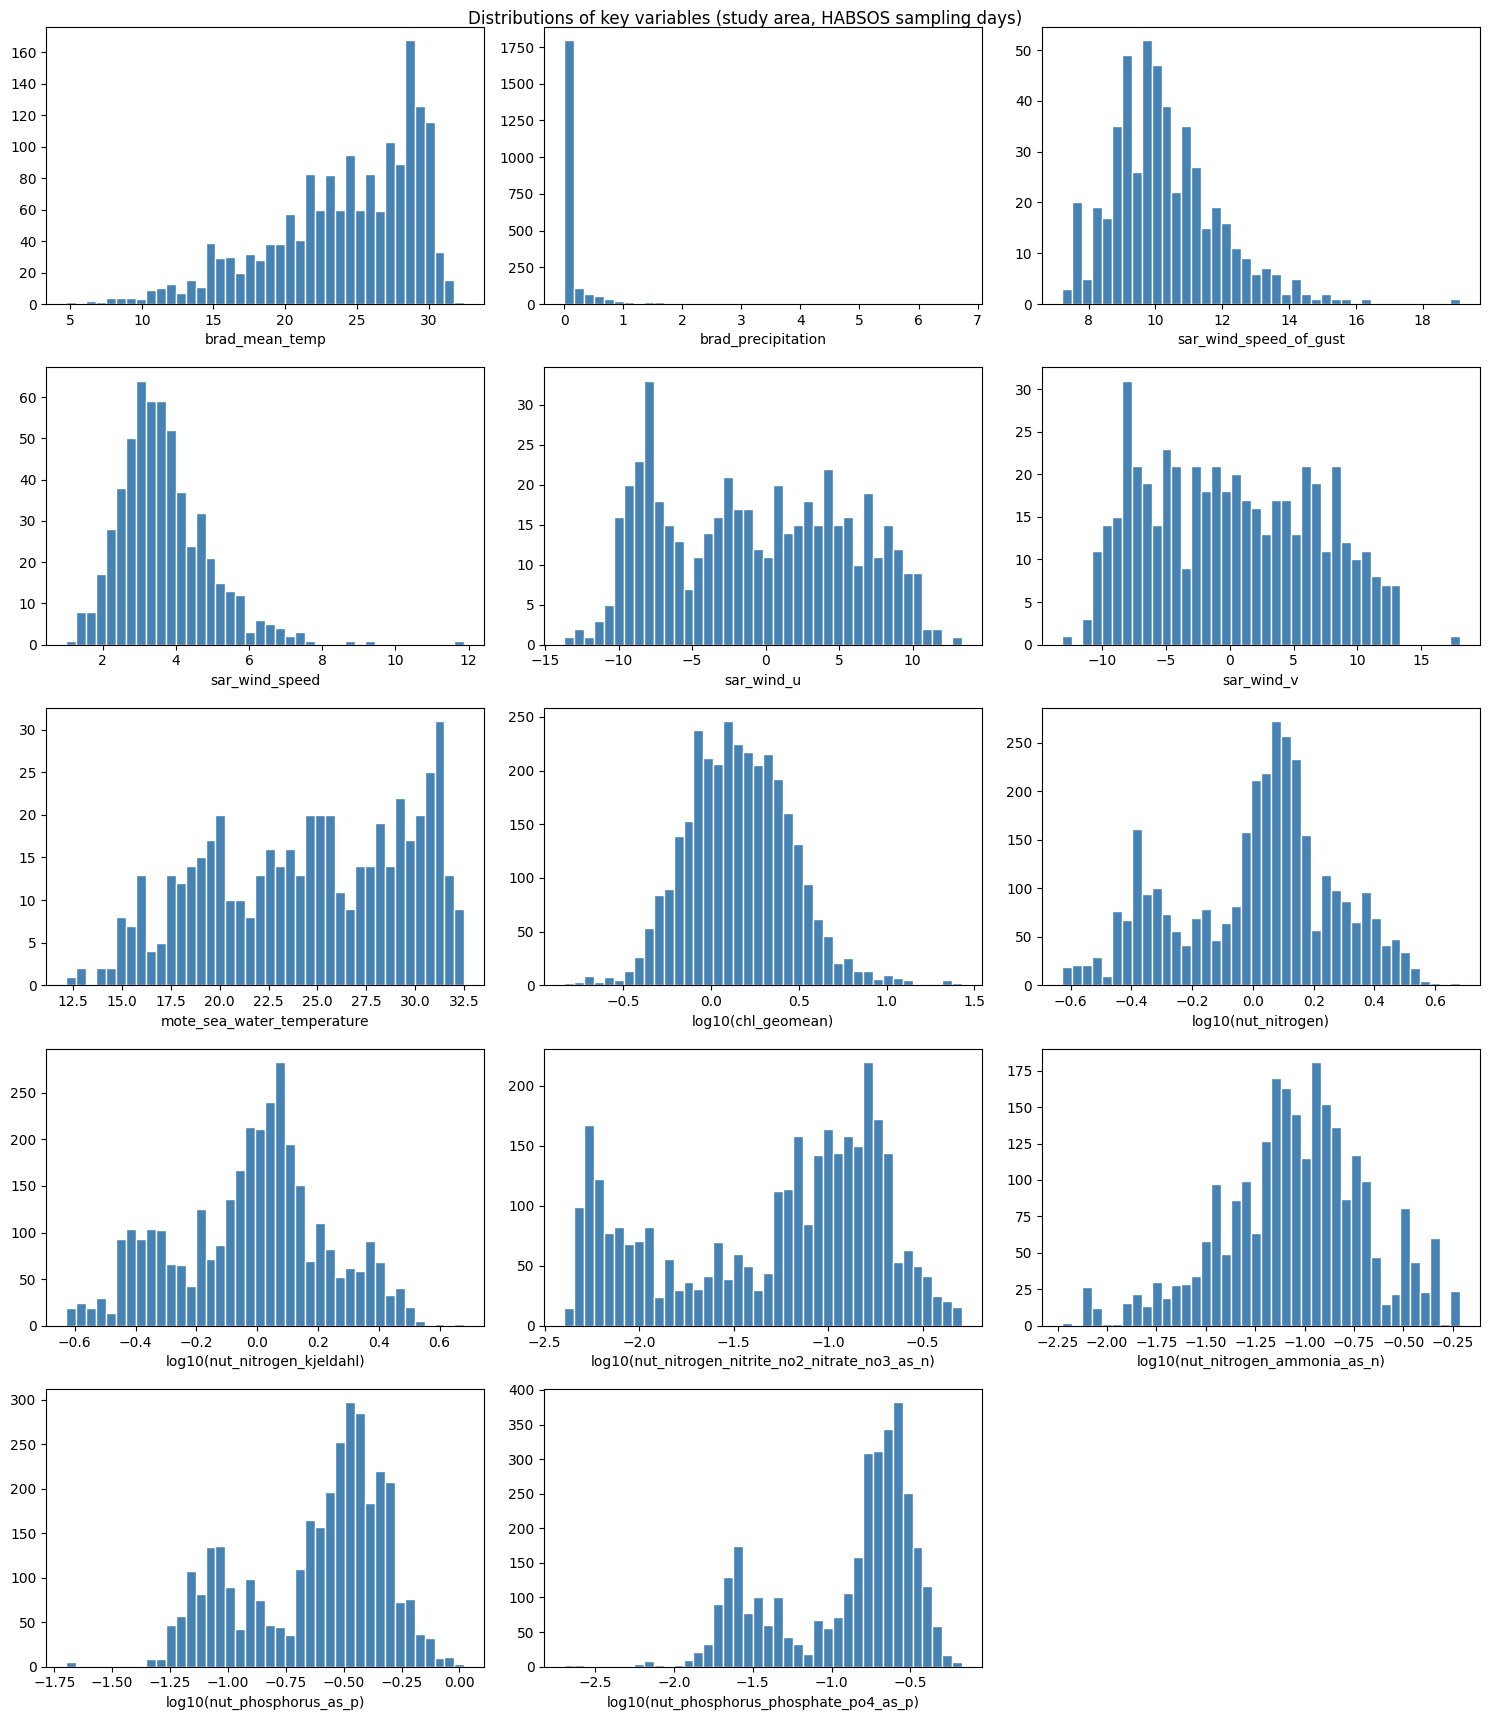

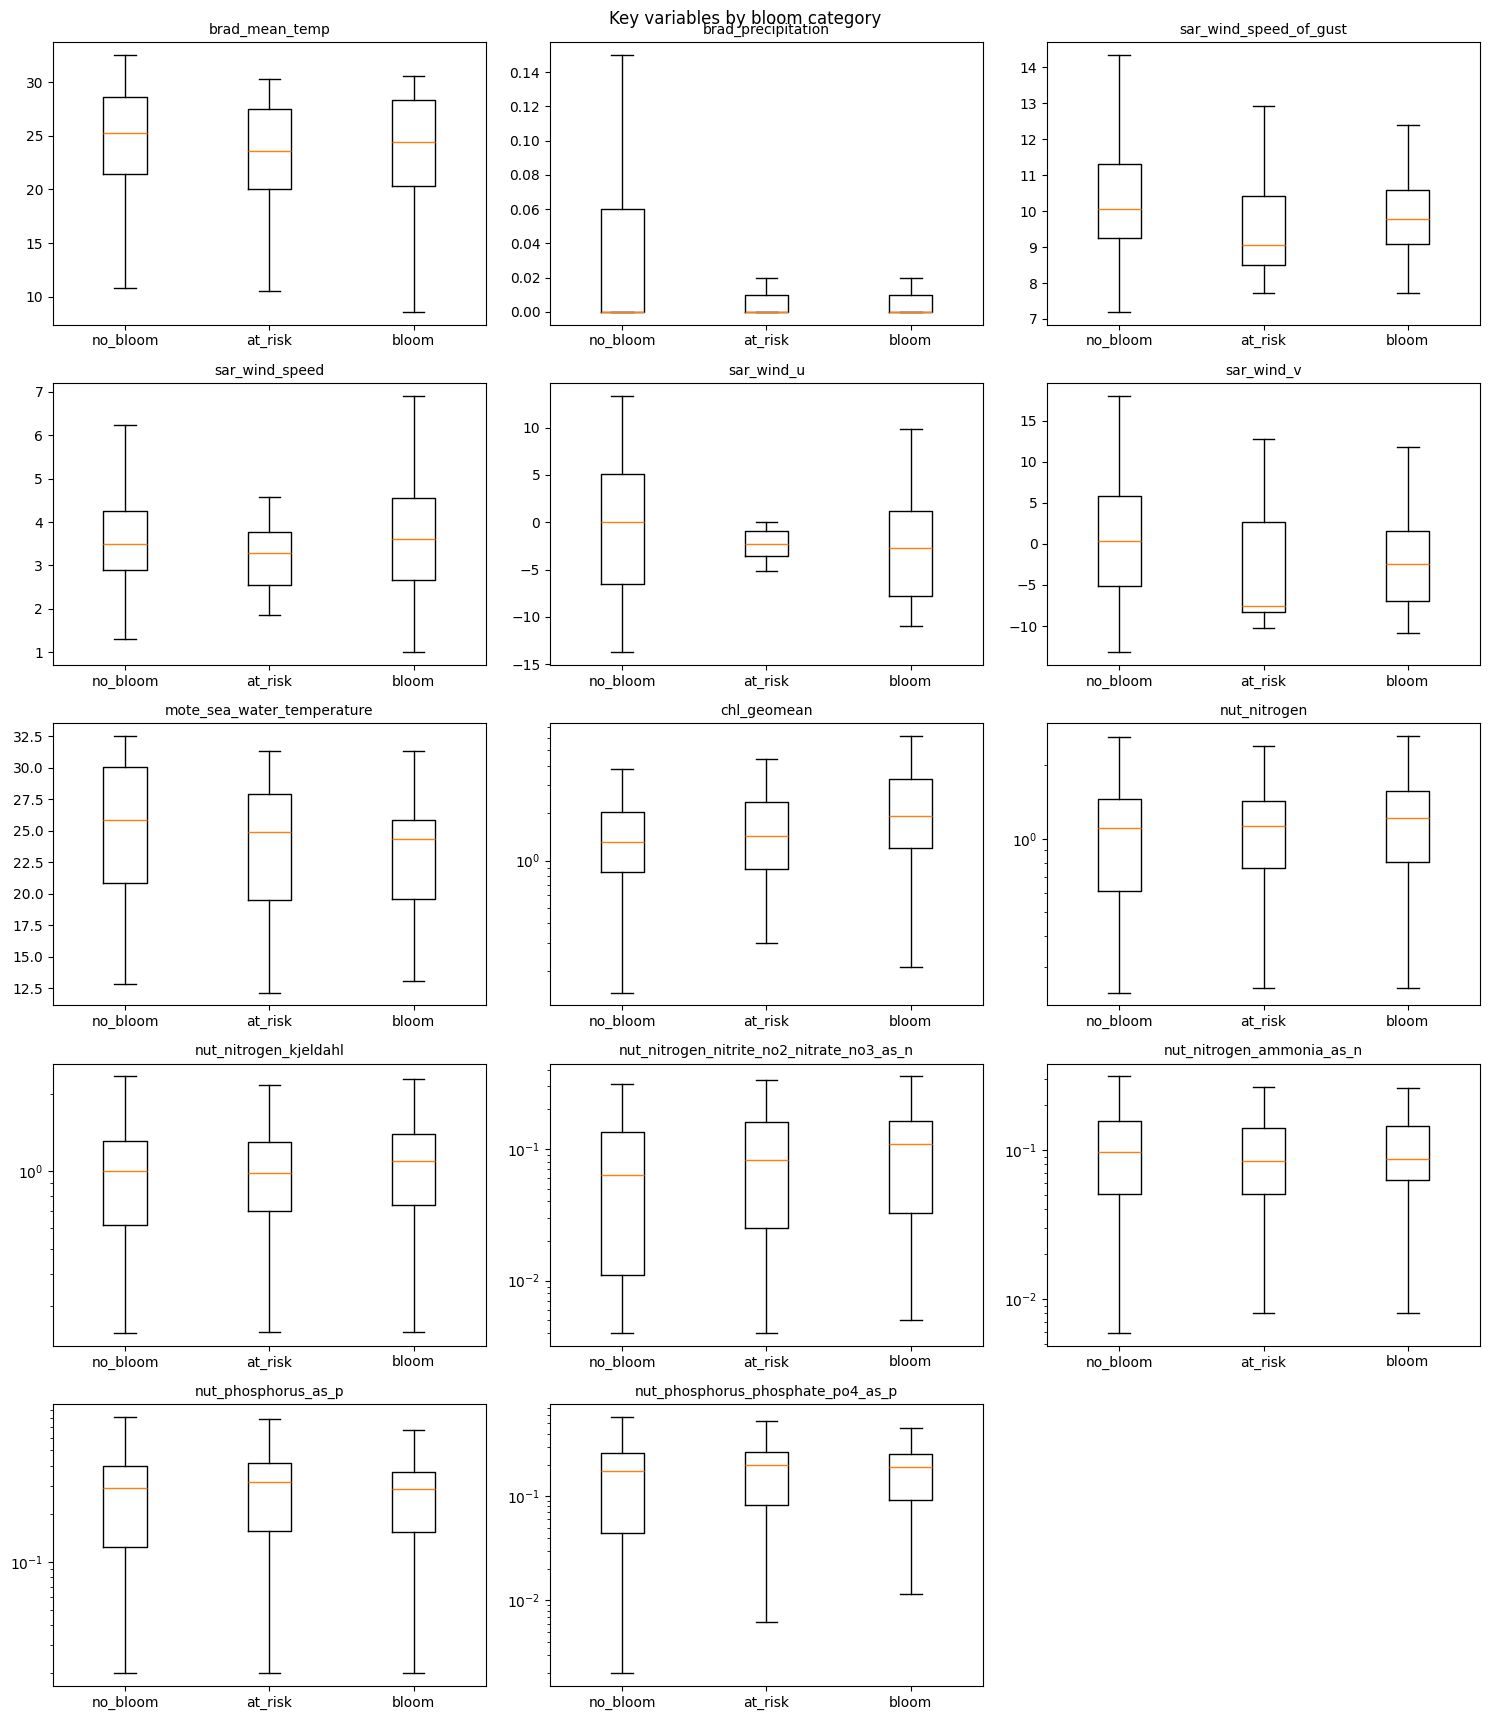

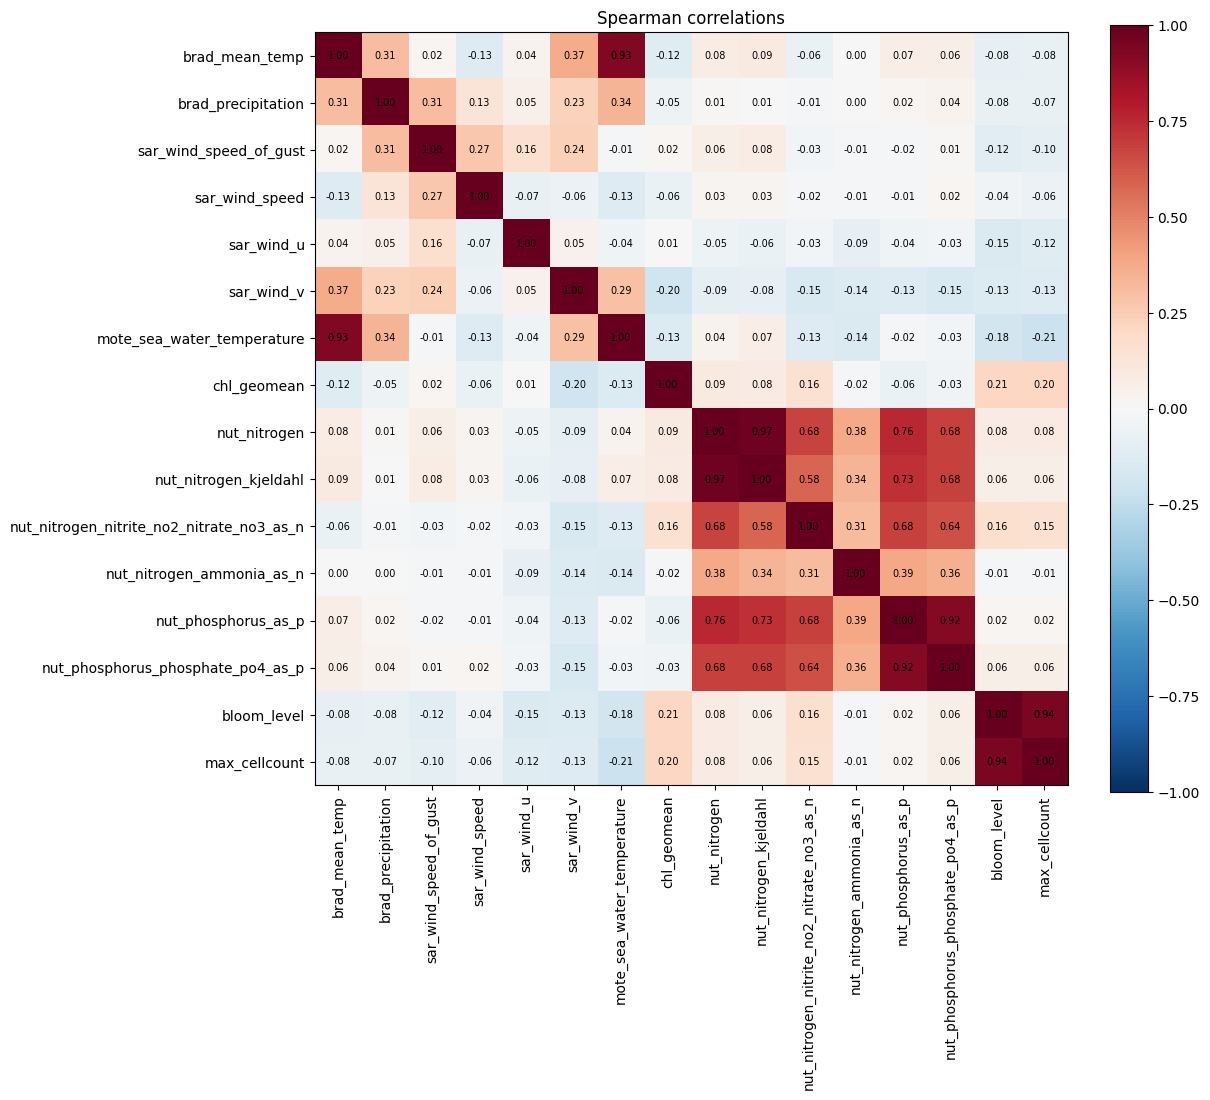

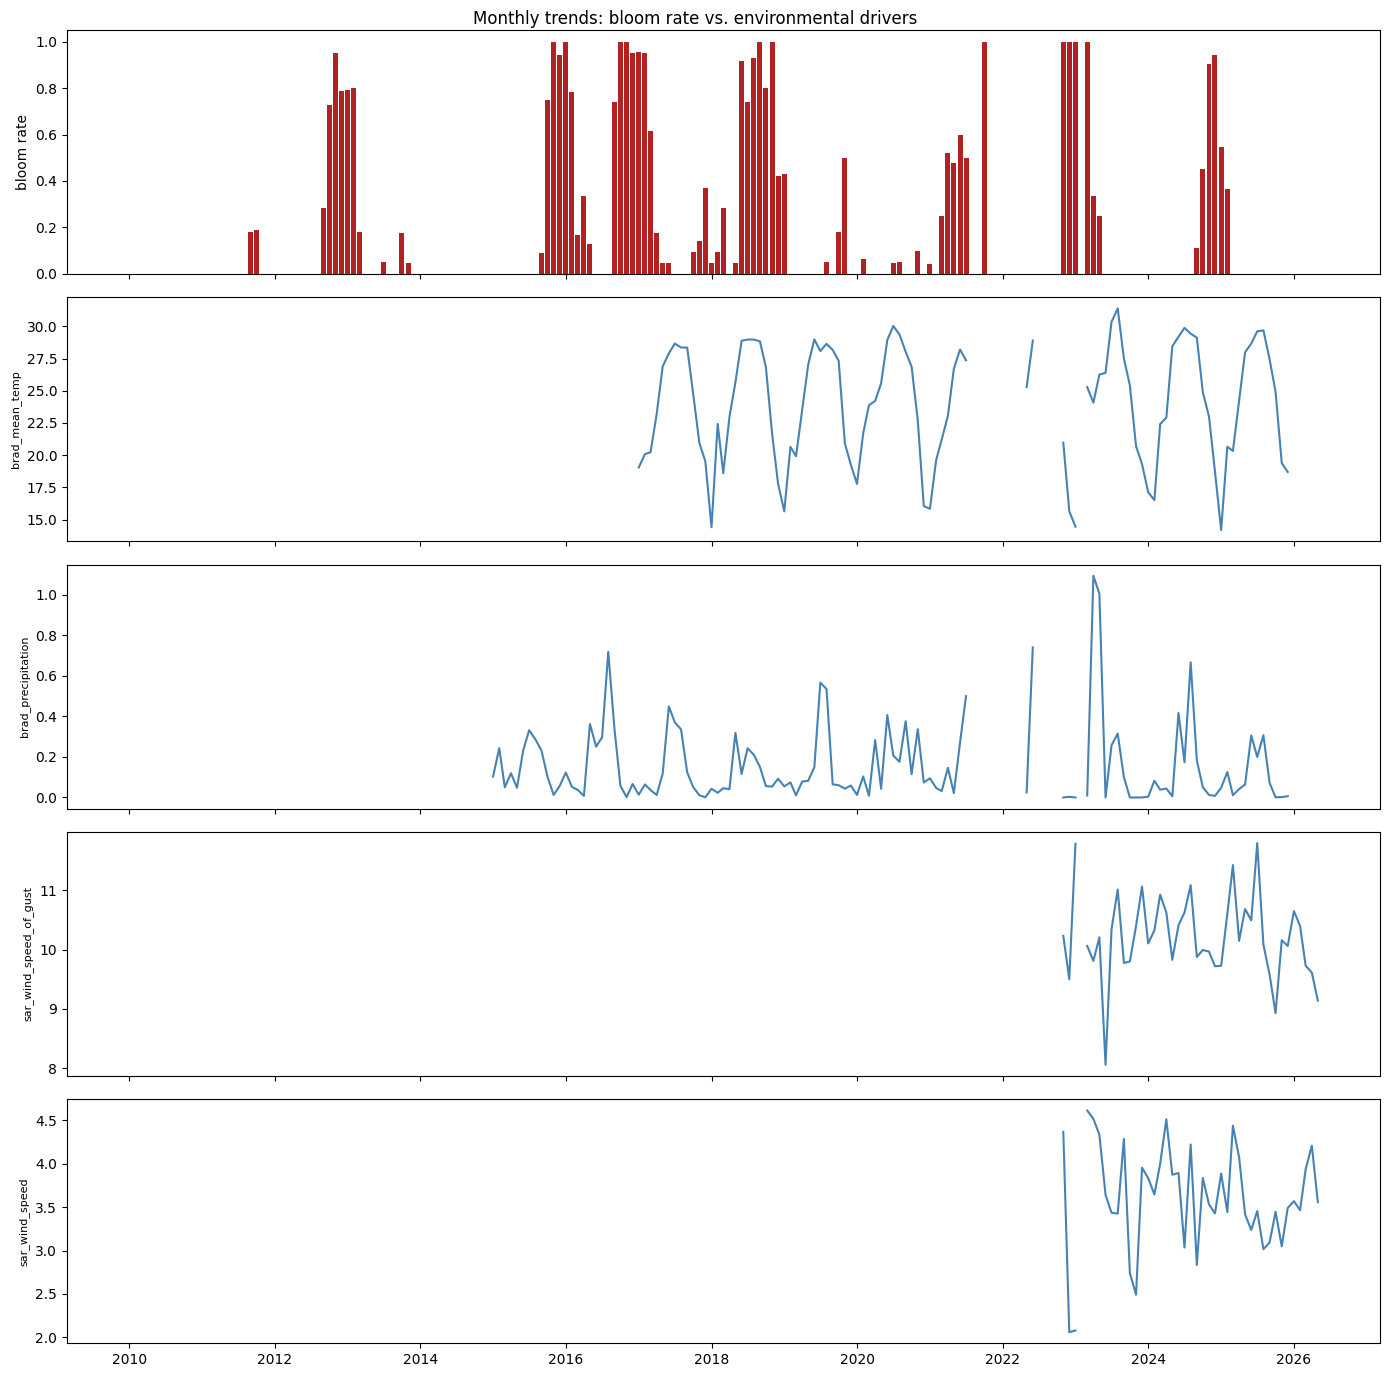

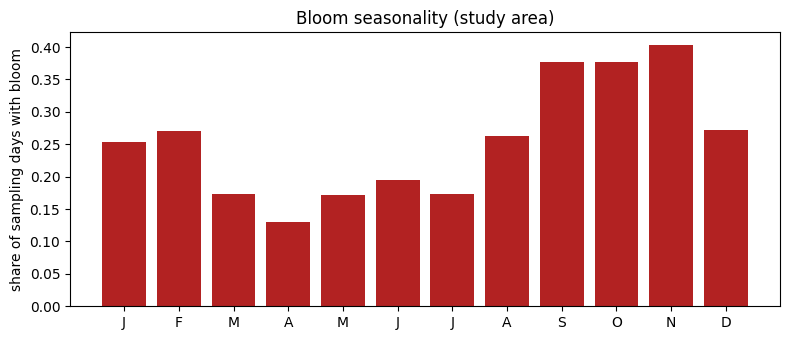


=== Spearman correlation with bloom_level at different lead times ===
                                           lag_0d  lag_7d  lag_14d  lag_30d
chl_geomean                                 0.207   0.193    0.173    0.156
mote_sea_water_temperature                 -0.182  -0.180   -0.168   -0.096
nut_nitrogen_nitrite_no2_nitrate_no3_as_n   0.162   0.168    0.191    0.178
sar_wind_u                                 -0.148  -0.187   -0.244   -0.284
sar_wind_v                                 -0.135  -0.129   -0.094   -0.047
sar_wind_speed_of_gust                     -0.115  -0.123   -0.062   -0.080
brad_mean_temp                             -0.082  -0.058   -0.019    0.017
nut_nitrogen                                0.081   0.096    0.109    0.090
brad_precipitation                         -0.076  -0.057   -0.011    0.003
nut_nitrogen_kjeldahl                       0.060   0.082    0.101    0.078
nut_phosphorus_phosphate_po4_as_p           0.060   0.073    0.086    0.082
sar_wind_speed   

In [ ]:
# TASK 8: Exploratory data analysis
# Distributions, correlations, and time trends for chlorophyll-a, nutrients, temperature, and wind
# against bloom occurrence. Also builds the daily feature table used by the models.

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 8a. Daily bloom target from HABSOS (study area only) ---
label_map = {'no_bloom': 0, 'at_risk': 1, 'bloom': 2}
df_hab = standardized_dfs['habsos'].copy()
df_hab['date'] = pd.to_datetime(df_hab['date'], errors='coerce').astype('datetime64[ns]')
df_hab = df_hab[in_bbox(df_hab)].dropna(subset=['date'])
df_hab['bloom_level'] = df_hab['bloom_label'].map(label_map)

hab_daily = df_hab.groupby('date').agg(
    bloom_level=('bloom_level', 'max'),          # worst condition observed that day
    max_cellcount=('CELLCOUNT', 'max'),
    n_samples=('bloom_level', 'size'))
hab_daily['bloom_flag'] = (hab_daily['bloom_level'] == 2).astype(int)

print("=== Study-area HABSOS daily class balance ===")
print(hab_daily['bloom_level'].map({v: k for k, v in label_map.items()}).value_counts())

# --- 8b. Nutrients: pivot long-format results to one column per key analyte ---
df_nut = standardized_dfs['nutrients'].copy()
df_nut['date'] = pd.to_datetime(df_nut['date'], errors='coerce').astype('datetime64[ns]')
analyte_col = next((c for c in df_nut.columns if any(k in c.lower() for k in ['analyte', 'characteristic', 'parameter'])), None)
value_col = (next((c for c in df_nut.columns if 'result_value' in c.lower().replace(' ', '_')), None)
             or next((c for c in df_nut.columns if 'result' in c.lower() and pd.api.types.is_numeric_dtype(df_nut[c])), None))

nut_daily = pd.DataFrame()
if analyte_col and value_col:
    df_nut[value_col] = pd.to_numeric(df_nut[value_col], errors='coerce')
    key = df_nut[df_nut[analyte_col].astype(str).str.lower()
                 .str.contains('nitrogen|phosph|nitrate|ammon|silica', na=False)]
    top = key[analyte_col].value_counts().head(6).index
    nut_daily = key[key[analyte_col].isin(top)].pivot_table(
        index='date', columns=analyte_col, values=value_col, aggfunc='mean').sort_index()
    nut_daily.columns = ['nut_' + re.sub(r'[^a-z0-9]+', '_', str(c).lower()).strip('_') for c in nut_daily.columns]
    print("\nNutrient analytes used:", list(nut_daily.columns))
else:
    print("\n⚠️ Couldn't auto-detect nutrient analyte/value columns:", list(df_nut.columns))

# --- 8c. Daily feature table (weather, chlorophyll, nutrients) on one calendar ---
starts = [df_weather.index.min(), chl_daily.index.min()]
ends = [df_weather.index.max(), chl_daily.index.max()]
cal = pd.date_range(min(starts), max(ends), freq='D')

feat_daily = df_weather.drop(columns=['has_brad', 'has_sar', 'has_mote']).reindex(cal)
# Only carry past values forward ('ffill'); 'nearest' could pull in values from future days.
# chl_max is left out: the brightest pixel depends on each product's grid resolution.
CHL_FEATURES = ['chl_geomean', 'chl_anom']
feat_daily = feat_daily.join(chl_daily[CHL_FEATURES].reindex(cal, method='ffill', tolerance=pd.Timedelta(days=3)))
if not nut_daily.empty:
    feat_daily = feat_daily.join(nut_daily.reindex(cal, method='ffill', tolerance=pd.Timedelta(days=30)))
feat_daily.index.name = 'date'

master = hab_daily.join(feat_daily, how='inner')
print(f"\nEDA master table: {master.shape}, {master.index.min().date()} to {master.index.max().date()}")

# Variables to plot
key_vars = [c for c in master.columns
            if any(k in c for k in ['chl_geomean', 'mean_temp', 'sea_water_temperature',
                                    'wind_speed', 'wind_u', 'wind_v', 'precip', 'nut_'])
            and not c.endswith('_max')]
log_vars = [c for c in key_vars if c.startswith(('chl', 'nut_'))]

print("\n=== Summary statistics ===")
print(master[key_vars + ['max_cellcount']].describe().T.round(3))

# --- 8d. Distributions ---
ncols = 3
nrows = int(np.ceil(len(key_vars) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, key_vars):
    s = master[col].dropna()
    if col in log_vars:
        s = np.log10(s[s > 0])
        ax.set_xlabel(f"log10({col})")
    else:
        ax.set_xlabel(col)
    ax.hist(s, bins=40, color='steelblue', edgecolor='white')
for ax in axes[len(key_vars):]:
    ax.axis('off')
fig.suptitle("Distributions of key variables (study area, HABSOS sampling days)")
plt.tight_layout(); plt.show()

# --- 8e. Key variables by bloom category ---
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, key_vars):
    data = [master.loc[master['bloom_level'] == lvl, col].dropna() for lvl in [0, 1, 2]]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks([1, 2, 3], ['no_bloom', 'at_risk', 'bloom'])
    ax.set_title(col, fontsize=10)
    if col in log_vars:
        ax.set_yscale('log')
for ax in axes[len(key_vars):]:
    ax.axis('off')
fig.suptitle("Key variables by bloom category")
plt.tight_layout(); plt.show()

# --- 8f. Spearman correlation heatmap (robust to skew/outliers) ---
corr_cols = key_vars + ['bloom_level', 'max_cellcount']
corr = master[corr_cols].corr(method='spearman')
size = 1 + 0.7 * len(corr_cols)
fig, ax = plt.subplots(figsize=(size, size))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=90)
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        if pd.notna(corr.iloc[i, j]):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha='center', va='center', fontsize=7)
plt.colorbar(im, fraction=0.046)
ax.set_title("Spearman correlations")
plt.tight_layout(); plt.show()

# --- 8g. Time trends (monthly) ---
monthly = master.resample('MS').mean(numeric_only=True)
trend_vars = [c for c in key_vars if not c.startswith('nut_')][:4]
fig, axes = plt.subplots(len(trend_vars) + 1, 1, figsize=(14, 2.8 * (len(trend_vars) + 1)), sharex=True)
axes[0].bar(monthly.index, monthly['bloom_flag'], width=25, color='firebrick')
axes[0].set_ylabel('bloom rate')
for ax, col in zip(axes[1:], trend_vars):
    ax.plot(monthly.index, monthly[col], color='steelblue')
    ax.set_ylabel(col, fontsize=8)
fig.suptitle("Monthly trends: bloom rate vs. environmental drivers")
plt.tight_layout(); plt.show()

# Seasonality (all study-area HABSOS days, not just the weather overlap)
seasonal = hab_daily.groupby(hab_daily.index.month)['bloom_flag'].mean()
plt.figure(figsize=(8, 3.5))
plt.bar(seasonal.index, seasonal.values, color='firebrick')
plt.xticks(range(1, 13), ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
plt.ylabel('share of sampling days with bloom')
plt.title('Bloom seasonality (study area)')
plt.tight_layout(); plt.show()

# --- 8h. Lagged correlations: do conditions N days earlier relate to bloom level? ---
lags = [0, 7, 14, 30]
lag_vars = [c for c in key_vars if c in feat_daily.columns]
rows = []
for lag in lags:
    shifted = feat_daily[lag_vars].shift(lag)     # value from `lag` days BEFORE the bloom observation
    joined = hab_daily[['bloom_level']].join(shifted, how='inner')
    rows.append(joined.corr(method='spearman')['bloom_level'].drop('bloom_level').rename(f'lag_{lag}d'))
lag_corr = pd.concat(rows, axis=1)

print("\n=== Spearman correlation with bloom_level at different lead times ===")
print(lag_corr.round(3).sort_values('lag_0d', key=abs, ascending=False))

master.to_csv("data/processed/eda_master_daily.csv")
feat_daily.to_csv("data/processed/features_daily.csv")
print("\nSaved EDA master table + daily feature table.")

## Task #6 Documentation: Merging Weather + Water Temp Datasets

* **Time alignment:** All three sources were collapsed to one row per calendar day (UTC date) and joined on a continuous daily index, so missing days show up as explicit NaN rows.
* **Bradenton:** Rebuilt from the raw file. COOP codes were handled ('M' → missing, 'T' trace precip → 0), and temperatures were converted from °F to °C.
* **Sarasota wind:** Wind speed and direction were converted to u/v vector components before daily averaging, because compass directions can't be averaged directly. The daily max wind speed was also kept.
* **Mote bottom temp:** Daily mean and daily max.
* **Gaps:** Only internal gaps of 2 days or less were linearly interpolated; longer gaps stay NaN.
* **Location:** All stations fall inside the Sarasota/Bradenton study area, so the join is by date only.
* **Output:** `data/processed/weather_watertemp_daily.csv`. The `has_brad`, `has_sar`, and `has_mote` flags mark coverage; all three overlap only from 2022-07-11 to 2025-03-26 (629 days).

## Task #7 Documentation: Chlorophyll Satellite Alignment

* **Sources:** The overview's product (NOAA multi-sensor DINEOF gap-filled 2 km, 2020–2026, `ChlorophyllaConcentrationSarasota.csv`) is the primary file. The older download (`..._Dataset2.csv`, 2010 to 2022-05) fills earlier dates. On overlapping dates the two are compared, the older file is rescaled to the primary product's level, and only the primary file is used.
* **Features:** The model uses `chl_geomean` and `chl_anom`, the log chlorophyll deviation from the pre-test monthly average. `chl_max` was dropped because it depends on each product's grid resolution.
* **Spatial subset:** Bounding box 26.9–27.6°N, 82.9–82.3°W. Non-positive and missing pixels were dropped.
* **Temporal alignment:** Each sample is matched to the nearest satellite image within ± half the product's cadence (the product is daily, so ±1 day).
* **Spatial alignment:** Each sample with coordinates is matched to the nearest pixel within about 5 km. The study-area daily geometric mean is also attached, because chlorophyll-a is log-normally distributed.
* **Outputs:** `chlorophyll_studyarea_daily.csv` and `sampling_events_chl_matched.csv` (match rates by dataset are printed in the cell).

## Task #8 EDA Findings (fill in after running)

* **Class balance in study area:**
* **Seasonality:**
* **Strongest correlates of bloom_level:**
* **Lead-time signal (7/14/30-day lags):**
* **Data gaps / caveats:** Sources cover different periods: Bradenton 2015–2025, Mote bottom temperature 2020-08 to 2025-03, Sarasota wind 2022-07 onward, satellite chlorophyll 2010–2026 (two files combined). MODEL 2 drops features that are mostly missing in either the training or the test period.

In [ ]:
# MODEL 1: Data quality checks on the daily feature table (columns, nulls, value ranges)
import pandas as pd
import numpy as np

df_features = pd.read_csv('data/processed/features_daily.csv', parse_dates=['date'])

def validate_features(df):
    print("Running feature validation and schema checks...")

    # Expected columns
    expected_cols = [
        'date', 'brad_mean_temp', 'brad_precipitation',
        'sar_wind_speed', 'mote_sea_water_temperature', 'chl_geomean'
    ]
    for col in expected_cols:
        assert col in df.columns, f"Missing expected column: {col}"
    print(" All expected feature columns present.")

    # No missing dates
    critical_cols = ['date']
    for col in critical_cols:
        if col in df.columns:
            assert df[col].isnull().sum() == 0, f"Critical column '{col}' contains null values."
    print(" Critical columns have zero null values.")

    # Values within physical bounds
    if 'brad_mean_temp' in df.columns:
        valid_temp = df['brad_mean_temp'].dropna()
        assert valid_temp.between(-5, 45).all(), "Bradenton temperature out of realistic bounds."

    if 'sar_wind_speed' in df.columns:
        valid_wind = df['sar_wind_speed'].dropna()
        assert (valid_wind >= 0).all(), "Wind speed cannot be negative."

    print(" Domain boundary assertions passed successfully!\n")

validate_features(df_features)

Running feature validation and schema checks...
 All expected feature columns present.
 Critical columns have zero null values.
 Domain boundary assertions passed successfully!



In [ ]:
# MODEL 1: Data quality checks on the calendar (target labels, duplicates, gaps)
def validate_integrity_and_calendar(df):
    print("Running target label and calendar continuity checks...")

    # Target labels (only if a 'bloom_status' column exists)
    if 'bloom_status' in df.columns:
        valid_labels = {'bloom', 'no_bloom', 'at_risk'}
        unique_labels = set(df['bloom_status'].dropna().unique())
        assert unique_labels.issubset(valid_labels), f"Found unexpected labels in target: {unique_labels - valid_labels}"
        print(f" Target labels verified: {unique_labels}")
    else:
        print(" [i] 'bloom_status' column not found; skipping target mapping check.")

    # Calendar continuity
    df_sorted = df.sort_values('date')

    # Duplicate dates
    duplicates = df_sorted['date'].duplicated().sum()
    assert duplicates == 0, f"Found {duplicates} duplicate date entries."
    print(" No duplicate dates found.")

    # Gaps in the daily sequence
    date_diffs = df_sorted['date'].diff().dt.days.dropna()
    gaps = date_diffs[date_diffs > 1]
    if not gaps.empty:
        print(f" [!] Warning: Found {len(gaps)} gaps greater than 1 day in the timeline.")
    else:
        print(" Calendar continuity verified (daily sequence is continuous).")

validate_integrity_and_calendar(df_features)

Running target label and calendar continuity checks...
 [i] 'bloom_status' column not found; skipping target mapping check.
 No duplicate dates found.
 Calendar continuity verified (daily sequence is continuous).


In [ ]:
# MODEL 2: Forecasting dataset, chronological test split, and shared helper functions
# For horizon h, the bloom level on day d is predicted from features available on day d - h.
import os, json
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

HORIZONS = [7, 14]                         # forecast lead times in days
CLASSES = ['no_bloom', 'at_risk', 'bloom']
OUT_DIR = "data/processed/models"
os.makedirs(OUT_DIR, exist_ok=True)

# --- 2a. Daily feature table (same as features_daily.csv) ---
F = feat_daily.copy()
cal = F.index

# --- 2b. Rolling 7- and 30-day means ---
base_cols = F.columns.tolist()
rolls = [F[base_cols].rolling(w, min_periods=max(1, w // 3)).mean().add_suffix(f'_mean{w}d') for w in [7, 30]]
F = pd.concat([F] + rolls, axis=1)

# --- 2c. Persistence features: the last observed bloom state (blooms tend to persist) ---
hab_cal = hab_daily.reindex(pd.date_range(hab_daily.index.min(), cal.max(), freq='D'))
last_obs_date = pd.Series(hab_cal.index.where(hab_cal['bloom_level'].notna()), index=hab_cal.index).ffill()
P = pd.DataFrame(index=hab_cal.index)
P['last_bloom_level'] = hab_cal['bloom_level'].ffill()
P['days_since_last_sample'] = (P.index.to_series() - last_obs_date).dt.days
P['max_bloom_level_30d'] = hab_cal['bloom_level'].rolling(30, min_periods=1).max()
P['n_bloom_days_90d'] = (hab_cal['bloom_level'] == 2).rolling(90, min_periods=1).sum()
P['log_last_cellcount'] = np.log10(hab_cal['max_cellcount'].ffill() + 1)

# Reporting lag: HABSOS results are posted days after sampling. Shifting the bloom-history
# features means day t only sees samples published by day t (0 = instant availability).
REPORT_LAG_DAYS = 0
if REPORT_LAG_DAYS:
    P = P.shift(REPORT_LAG_DAYS)                        # P is on a daily calendar, so rows = days
    P['days_since_last_sample'] += REPORT_LAG_DAYS
F = F.join(P.reindex(cal))

# --- 2d. Regional and recent-history HABSOS features ---
# Red tides often start offshore or to the south and drift into the study area, so bloom activity
# in neighboring waters can come first. Summarizes the past 14 days in three neighboring regions,
# plus finer recent history inside the study area (K. brevis present at all, recent maximum, trend).
REGIONS = {'study':    (26.90, 27.60, -82.90, -82.30),
           'south':    (26.00, 26.90, -82.90, -81.70),     # toward Charlotte Harbor
           'offshore': (26.50, 27.80, -83.60, -82.90),
           'north':    (27.60, 28.20, -83.00, -82.40)}     # toward Tampa Bay
hb = standardized_dfs['habsos'][['date', 'latitude', 'longitude', 'CELLCOUNT']].copy()
hb['date'] = pd.to_datetime(hb['date'], errors='coerce')
hb = hb.dropna(subset=['date'])
hb['log_count'] = np.log10(hb['CELLCOUNT'].clip(lower=0) + 1)
reg_cal = pd.date_range(cal.min() - pd.Timedelta(days=60), cal.max(), freq='D')
R = pd.DataFrame(index=reg_cal)
for region, (lat0, lat1, lon0, lon1) in REGIONS.items():
    s = hb[hb['latitude'].between(lat0, lat1) & hb['longitude'].between(lon0, lon1)]
    g = s.groupby('date')
    daily_max = g['log_count'].max().reindex(reg_cal)
    n_high = g['CELLCOUNT'].apply(lambda x: (x >= 1000).sum()).reindex(reg_cal).fillna(0)
    R[f'{region}_maxlog_14d'] = daily_max.rolling(14, min_periods=1).max()
    R[f'{region}_n_ge1000_14d'] = n_high.rolling(14).sum()
    if region == 'study':
        n_all = g.size().reindex(reg_cal).fillna(0)
        n_present = g['CELLCOUNT'].apply(lambda x: (x > 0).sum()).reindex(reg_cal).fillna(0)
        R['study_frac_present_14d'] = n_present.rolling(14).sum() / n_all.rolling(14).sum().replace(0, np.nan)
        R['study_maxlog_7d'] = daily_max.rolling(7, min_periods=1).max()
        R['study_trend_14d'] = R['study_maxlog_14d'] - daily_max.shift(14).rolling(16, min_periods=1).max()
if REPORT_LAG_DAYS:
    R = R.shift(REPORT_LAG_DAYS)
F = F.join(R.reindex(cal))
print(f"Added {R.shape[1]} regional / recent-history HABSOS features")

# --- 2d-2. Water temperature and salinity from HABSOS samples ---
# A much longer record than Mote's (2020 onward), but measured only when someone samples. Features:
# last value, its age in days, and a 30-day mean. Only values flagged good (QA = 1) and in range are used.
WQ_LAST_MAX_DAYS = 60          # don't carry a measurement forward for more than 60 days
WQ_RANGES = {'WATER_TEMP': (5, 38), 'SALINITY': (0, 45)}
WQ_REGIONS = {k: REGIONS[k] for k in ['study', 'south']}

def water_quality_features(samples, box, prefix, calendar):
    """Daily last value, age and 30-day mean of HABSOS water temperature and salinity in one box."""
    lat0, lat1, lon0, lon1 = box
    s = samples[samples['latitude'].between(lat0, lat1) & samples['longitude'].between(lon0, lon1)]
    out = pd.DataFrame(index=calendar)
    for col, short in [('WATER_TEMP', 'wtemp'), ('SALINITY', 'sal')]:
        if col not in s.columns:
            continue
        v = pd.to_numeric(s[col], errors='coerce')
        qa = pd.to_numeric(s.get(f'{col}_QA'), errors='coerce') if f'{col}_QA' in s.columns else 1
        lo, hi = WQ_RANGES[col]
        v = v.where((qa == 1) & v.between(lo, hi))
        daily = v.groupby(s['date']).mean().reindex(calendar)
        seen = pd.Series(calendar.where(daily.notna()), index=calendar).ffill()
        out[f'{prefix}_{short}_last'] = daily.ffill(limit=WQ_LAST_MAX_DAYS)
        out[f'{prefix}_{short}_age_days'] = (calendar.to_series() - seen).dt.days
        out[f'{prefix}_{short}_mean30d'] = daily.rolling(30, min_periods=1).mean()
    return out

hb_wq = standardized_dfs['habsos'].copy()
hb_wq['date'] = pd.to_datetime(hb_wq['date'], errors='coerce')
hb_wq = hb_wq.dropna(subset=['date'])
WQ = pd.concat([water_quality_features(hb_wq, box, name, reg_cal) for name, box in WQ_REGIONS.items()], axis=1)
if REPORT_LAG_DAYS:
    WQ = WQ.shift(REPORT_LAG_DAYS)
F = F.join(WQ.reindex(cal))
print(f"Added {WQ.shape[1]} HABSOS water temperature / salinity features")

# --- 2e. Model dataset for each horizon ---
label_dates = hab_daily.index[(hab_daily.index >= cal.min() + pd.Timedelta(days=30)) &
                              (hab_daily.index <= cal.max())]

def make_dataset(h):
    d = pd.DatetimeIndex(label_dates)
    X = F.reindex(d - pd.Timedelta(days=h))
    X.index = d
    X['doy_sin'] = np.sin(2 * np.pi * d.dayofyear / 365.25)   # seasonality of the target day
    X['doy_cos'] = np.cos(2 * np.pi * d.dayofyear / 365.25)
    y = hab_daily.loc[d, 'bloom_level'].astype(int)
    return X, y

# --- 2f. Test period: the last 20% of sampling days, held out until the final evaluation ---
TEST_FRAC = 0.20
TEST_START = pd.Timestamp(np.sort(label_dates)[int(len(label_dates) * (1 - TEST_FRAC))])
if 'CHL_CLIM_END' in globals() and CHL_CLIM_END > TEST_START:
    print(f"⚠️ CHL_CLIM_END ({CHL_CLIM_END.date()}) is after the test start ({TEST_START.date()}): "
          "set it to the test start in TASK 7 and rerun, or the anomaly uses test-period data.")
# --- 2g. Feature coverage filter ---
# Sources cover different periods (Sarasota wind starts 2022-07, Mote temperature 2020-08). A feature
# present in training but missing in testing (or the reverse) teaches patterns the model can't use.
MIN_TEST_COVERAGE = 0.5     # must be available on at least half of test days
MIN_TRAIN_COVERAGE = 0.2    # must be available often enough in training to learn from
_X, _ = make_dataset(min(HORIZONS))
_is_test = _X.index >= TEST_START
coverage = pd.DataFrame({'train': _X[~_is_test].notna().mean(),
                         'test': _X[_is_test].notna().mean()}).round(2)
DROPPED_FEATURES = coverage.index[(coverage['test'] < MIN_TEST_COVERAGE) |
                                  (coverage['train'] < MIN_TRAIN_COVERAGE)].tolist()
F = F.drop(columns=[c for c in DROPPED_FEATURES if c in F.columns])
print(f"Dropped {len(DROPPED_FEATURES)} features with too little coverage in train or test:")
print(coverage.loc[DROPPED_FEATURES].sort_values('test').to_string() if DROPPED_FEATURES else "  none")

json.dump({'test_start': str(TEST_START.date()), 'horizons': HORIZONS,
           'report_lag_days': REPORT_LAG_DAYS, 'dropped_features': DROPPED_FEATURES},
          open(f"{OUT_DIR}/split_info.json", "w"), indent=1)

def time_folds(dates, n_splits=4, gap_days=0):
    """TimeSeriesSplit (expanding window) + a purge gap so training labels never overlap the validation window."""
    dates = pd.DatetimeIndex(dates)
    for _, va_idx in TimeSeriesSplit(n_splits=n_splits).split(np.zeros((len(dates), 1))):
        tr_idx = np.where(dates < dates[va_idx[0]] - pd.Timedelta(days=gap_days))[0]
        yield tr_idx, va_idx

def full_proba(model, X):
    """Probabilities for all 3 classes, even if a training fold was missing one."""
    p = np.zeros((len(X), 3))
    p[:, model.classes_] = model.predict_proba(X)
    return p

def score(y_true, proba):
    pred = np.asarray(proba).argmax(1)
    out = {'macro_f1': f1_score(y_true, pred, labels=[0, 1, 2], average='macro', zero_division=0),
           'macro_precision': precision_score(y_true, pred, labels=[0, 1, 2], average='macro', zero_division=0),
           'macro_recall': recall_score(y_true, pred, labels=[0, 1, 2], average='macro', zero_division=0),
           'at_risk_recall': recall_score(y_true, pred, labels=[1], average='macro', zero_division=0),
           'bloom_recall': recall_score(y_true, pred, labels=[2], average='macro', zero_division=0)}
    try:
        out['roc_auc_ovr'] = roc_auc_score(y_true, proba, multi_class='ovr', average='macro', labels=[0, 1, 2])
    except ValueError:
        out['roc_auc_ovr'] = np.nan
    return out

print(f"Features: {F.shape[1]} | test period starts {TEST_START.date()}")
for h in HORIZONS:
    X, y = make_dataset(h)
    tr = X.index < TEST_START - pd.Timedelta(days=h)
    te = X.index >= TEST_START
    print(f"h={h:2d}d | train {tr.sum():,} rows, classes {np.bincount(y[tr], minlength=3)} "
          f"| test {te.sum():,} rows, classes {np.bincount(y[te], minlength=3)}")

Added 11 regional / recent-history HABSOS features
Added 12 HABSOS water temperature / salinity features
Dropped 36 features with too little coverage in train or test:
                                            train  test
mote_sea_water_temperature                   0.04  0.57
mote_sea_water_temperature_max               0.04  0.57
mote_sea_water_temperature_max_mean7d        0.04  0.57
mote_sea_water_temperature_mean7d            0.04  0.57
mote_sea_water_temperature_mean30d           0.04  0.58
mote_sea_water_temperature_max_mean30d       0.04  0.58
sar_wind_speed_of_gust                       0.00  0.72
sar_wind_speed_of_gust_max                   0.00  0.72
sar_wind_u                                   0.00  0.72
sar_wind_v                                   0.00  0.72
sar_wind_u_mean7d                            0.00  0.81
sar_wind_speed_of_gust_mean7d                0.00  0.81
sar_air_pressure_at_mean_sea_level           0.00  0.81
sar_wind_speed_of_gust_max_mean7d            0.0

In [ ]:
# MODEL 3: Baseline models (persistence, logistic regression, decision tree), time-ordered CV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

def make_baselines():
    return {
        'logistic_regression': make_pipeline(
            SimpleImputer(strategy='median', keep_empty_features=True), StandardScaler(),
            LogisticRegression(class_weight='balanced', max_iter=3000)),
        'decision_tree': make_pipeline(
            SimpleImputer(strategy='median', keep_empty_features=True),
            DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, class_weight='balanced', random_state=42)),
    }

rows = []
for h in HORIZONS:
    X, y = make_dataset(h)
    tr = X.index < TEST_START - pd.Timedelta(days=h)
    te = X.index >= TEST_START
    X_tr, y_tr = X[tr], y[tr]

    for i, (t, va) in enumerate(time_folds(X_tr.index, gap_days=h)):
        pers = X_tr['last_bloom_level'].iloc[va].fillna(0).astype(int).values
        rows.append({'horizon': h, 'model': 'persistence', 'fold': i, **score(y_tr.iloc[va], np.eye(3)[pers])})
        for name, model in make_baselines().items():
            model.fit(X_tr.iloc[t], y_tr.iloc[t])
            rows.append({'horizon': h, 'model': name, 'fold': i,
                         **score(y_tr.iloc[va], full_proba(model, X_tr.iloc[va]))})

    # Refit on the full training period; save test probabilities without scoring them yet
    for name, model in make_baselines().items():
        model.fit(X_tr, y_tr)
        pd.DataFrame(full_proba(model, X[te]), index=X.index[te], columns=[f'p_{c}' for c in CLASSES]) \
          .assign(y_true=y[te].values).to_csv(f"{OUT_DIR}/test_proba_{name}_h{h}.csv")

cv_baselines = pd.DataFrame(rows)
summary = cv_baselines.drop(columns='fold').groupby(['horizon', 'model']).mean().round(3)
summary.to_csv(f"{OUT_DIR}/cv_baseline_scores.csv")
print("=== Baseline CV scores (training period only) ===")
print(summary.to_string())

=== Baseline CV scores (training period only) ===
                             macro_f1  macro_precision  macro_recall  at_risk_recall  bloom_recall  roc_auc_ovr
horizon model                                                                                                  
7       decision_tree           0.493            0.517         0.539           0.449         0.560        0.710
        logistic_regression     0.473            0.484         0.513           0.381         0.585        0.676
        persistence             0.632            0.632         0.632           0.290         0.766        0.739
14      decision_tree           0.441            0.482         0.486           0.296         0.512        0.664
        logistic_regression     0.460            0.480         0.501           0.387         0.558        0.691
        persistence             0.582            0.581         0.585           0.231         0.717        0.704


In [ ]:
# MODEL 4: LightGBM hyperparameter tuning for each horizon (time-ordered CV on the training period)
from itertools import product
import lightgbm as lgb          # if this fails: !pip install lightgbm

base_params = dict(objective='multiclass', class_weight='balanced', min_child_samples=20,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)
grid = list(product([150, 400], [0.03, 0.1], [3, 5]))   # n_estimators, learning_rate, max_depth (kept shallow)

def lgbm_params(n, lr, d):
    return {**base_params, 'n_estimators': int(n), 'learning_rate': float(lr),
            'max_depth': int(d), 'num_leaves': min(2 ** int(d) - 1, 15)}

results = []
for h in HORIZONS:
    X, y = make_dataset(h)
    tr = X.index < TEST_START - pd.Timedelta(days=h)
    X_tr, y_tr = X[tr], y[tr]
    folds = list(time_folds(X_tr.index, gap_days=h))
    for n, lr, d in grid:
        fold_scores = [score(y_tr.iloc[va],
                             full_proba(lgb.LGBMClassifier(**lgbm_params(n, lr, d)).fit(X_tr.iloc[t], y_tr.iloc[t]),
                                        X_tr.iloc[va]))
                       for t, va in folds]
        results.append({'horizon': h, 'n_estimators': n, 'learning_rate': lr, 'max_depth': d,
                        **pd.DataFrame(fold_scores).mean().to_dict()})

res = pd.DataFrame(results).sort_values(['horizon', 'macro_f1'], ascending=[True, False])
res.to_csv(f"{OUT_DIR}/cv_grid_results.csv", index=False)

show = ['n_estimators', 'learning_rate', 'max_depth', 'macro_f1', 'at_risk_recall', 'bloom_recall', 'roc_auc_ovr']
for h in HORIZONS:
    print(f"\n=== h={h}d | top 3 LightGBM settings (CV) ===")
    print(res[res.horizon == h][show].head(3).round(3).to_string(index=False))
    print("Baselines for comparison:")
    print(summary.loc[h][['macro_f1', 'at_risk_recall', 'bloom_recall', 'roc_auc_ovr']].to_string())


=== h=7d | top 3 LightGBM settings (CV) ===
 n_estimators  learning_rate  max_depth  macro_f1  at_risk_recall  bloom_recall  roc_auc_ovr
          150           0.03          3     0.545           0.352         0.608        0.765
          150           0.03          5     0.536           0.216         0.603        0.774
          400           0.03          3     0.523           0.242         0.572        0.764
Baselines for comparison:
                     macro_f1  at_risk_recall  bloom_recall  roc_auc_ovr
model                                                                   
decision_tree           0.493           0.449         0.560        0.710
logistic_regression     0.473           0.381         0.585        0.676
persistence             0.632           0.290         0.766        0.739

=== h=14d | top 3 LightGBM settings (CV) ===
 n_estimators  learning_rate  max_depth  macro_f1  at_risk_recall  bloom_recall  roc_auc_ovr
          150           0.03          3     0.507    

In [ ]:
# MODEL 5: Final LightGBM model for each horizon: refit, save models and predicted probabilities
import joblib

for h in HORIZONS:
    best = res[res.horizon == h].iloc[0]
    params = lgbm_params(best.n_estimators, best.learning_rate, best.max_depth)

    X, y = make_dataset(h)
    tr = X.index < TEST_START - pd.Timedelta(days=h)
    te = X.index >= TEST_START
    X_tr, y_tr = X[tr], y[tr]

    X[te].to_csv(f"{OUT_DIR}/X_test_h{h}.csv")       # exact test rows, reused by MODEL 11 (SHAP)
    model = lgb.LGBMClassifier(**params).fit(X_tr, y_tr)
    joblib.dump(model, f"{OUT_DIR}/lgbm_h{h}.joblib")
    json.dump({'params': params, 'features': X.columns.tolist(), 'cv_macro_f1': float(best.macro_f1)},
              open(f"{OUT_DIR}/lgbm_h{h}_config.json", "w"))

    # Out-of-fold probabilities on the training period (for threshold tuning / calibration later)
    oof = np.full((len(X_tr), 3), np.nan)
    for t, va in time_folds(X_tr.index, gap_days=h):
        oof[va] = full_proba(lgb.LGBMClassifier(**params).fit(X_tr.iloc[t], y_tr.iloc[t]), X_tr.iloc[va])
    pd.DataFrame(oof, index=X_tr.index, columns=[f'p_{c}' for c in CLASSES]) \
      .assign(y_true=y_tr.values).to_csv(f"{OUT_DIR}/oof_proba_lgbm_h{h}.csv")

    # Test probabilities: saved now, scored only in the final evaluation
    pd.DataFrame(full_proba(model, X[te]), index=X.index[te], columns=[f'p_{c}' for c in CLASSES]) \
      .assign(y_true=y[te].values,
              persistence_pred=X.loc[te, 'last_bloom_level'].fillna(0).astype(int).values) \
      .to_csv(f"{OUT_DIR}/test_proba_lgbm_h{h}.csv")

    imp = pd.Series(model.booster_.feature_importance('gain'), index=X.columns).sort_values(ascending=False)
    print(f"\n=== h={h}d model saved | top 10 features by gain ===")
    print((imp / imp.sum()).head(10).round(3).to_string())

print(f"\nSaved to {OUT_DIR}/: models, configs, CV grid, out-of-fold and test probabilities")


=== h=7d model saved | top 10 features by gain ===
log_last_cellcount                                   0.207
study_maxlog_7d                                      0.130
study_frac_present_14d                               0.119
last_bloom_level                                     0.062
study_maxlog_14d                                     0.028
study_n_ge1000_14d                                   0.023
nut_nitrogen_nitrite_no2_nitrate_no3_as_n_mean30d    0.020
doy_sin                                              0.019
nut_nitrogen_ammonia_as_n_mean30d                    0.018
south_maxlog_14d                                     0.017

=== h=14d model saved | top 10 features by gain ===
study_maxlog_14d                                     0.178
study_maxlog_7d                                      0.096
log_last_cellcount                                   0.085
study_frac_present_14d                               0.072
doy_sin                                              0.040
north_maxl

In [ ]:
# MODEL 6: Decision-weight tuning
# With plain argmax, LightGBM over-predicts no_bloom. Per-class weights are learned on out-of-fold
# training probabilities (never the test set) and evaluated as 'lightgbm_tuned' in MODEL 7.
from itertools import product
import json
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

PCOLS = [f'p_{c}' for c in CLASSES]
WEIGHT_GRID = np.arange(0.5, 6.01, 0.25)
decision_weights = {}
for h in HORIZONS:
    oof = pd.read_csv(f"{OUT_DIR}/oof_proba_lgbm_h{h}.csv", index_col=0).dropna(subset=PCOLS)
    P, yt = oof[PCOLS].values, oof['y_true'].astype(int).values
    mf1 = lambda pred: f1_score(yt, pred, labels=[0, 1, 2], average='macro', zero_division=0)
    base_f1 = mf1(P.argmax(1))
    best_w, best_f1 = (1.0, 1.0), base_f1
    for w1, w2 in product(WEIGHT_GRID, repeat=2):
        f1 = mf1((P * [1.0, w1, w2]).argmax(1))
        if f1 > best_f1:
            best_w, best_f1 = (float(w1), float(w2)), f1
    decision_weights[str(h)] = [1.0, *best_w]
    print(f"h={h:2d}d: weights (no_bloom, at_risk, bloom) = {decision_weights[str(h)]} | "
          f"out-of-fold macro-F1 {base_f1:.3f} -> {best_f1:.3f}")

json.dump(decision_weights, open(f"{OUT_DIR}/decision_weights.json", "w"))
print("Note: the out-of-fold gain is optimistic (weights were picked on those same rows); "
      "the test set is the honest check.")


h= 7d: weights (no_bloom, at_risk, bloom) = [1.0, 1.0, 1.0] | out-of-fold macro-F1 0.602 -> 0.602
h=14d: weights (no_bloom, at_risk, bloom) = [1.0, 0.5, 0.5] | out-of-fold macro-F1 0.575 -> 0.579
Note: the out-of-fold gain is optimistic (weights were picked on those same rows); the test set is the honest check.


Test period starts 2021-02-05

h=7d test class counts: {'no_bloom': np.int64(523), 'at_risk': np.int64(40), 'bloom': np.int64(124)}
h=14d test class counts: {'no_bloom': np.int64(523), 'at_risk': np.int64(40), 'bloom': np.int64(124)}

=== TEST SET RESULTS ===
                             macro_f1  macro_precision  macro_recall  no_bloom_recall  at_risk_recall  bloom_recall  roc_auc_ovr
horizon model                                                                                                                   
7       persistence             0.590            0.594         0.586            0.931           0.125         0.702        0.732
        lightgbm                0.580            0.574         0.588            0.906           0.100         0.758        0.841
        lightgbm_tuned          0.580            0.574         0.588            0.906           0.100         0.758        0.841
        logistic_regression     0.568            0.563         0.592            0.862          

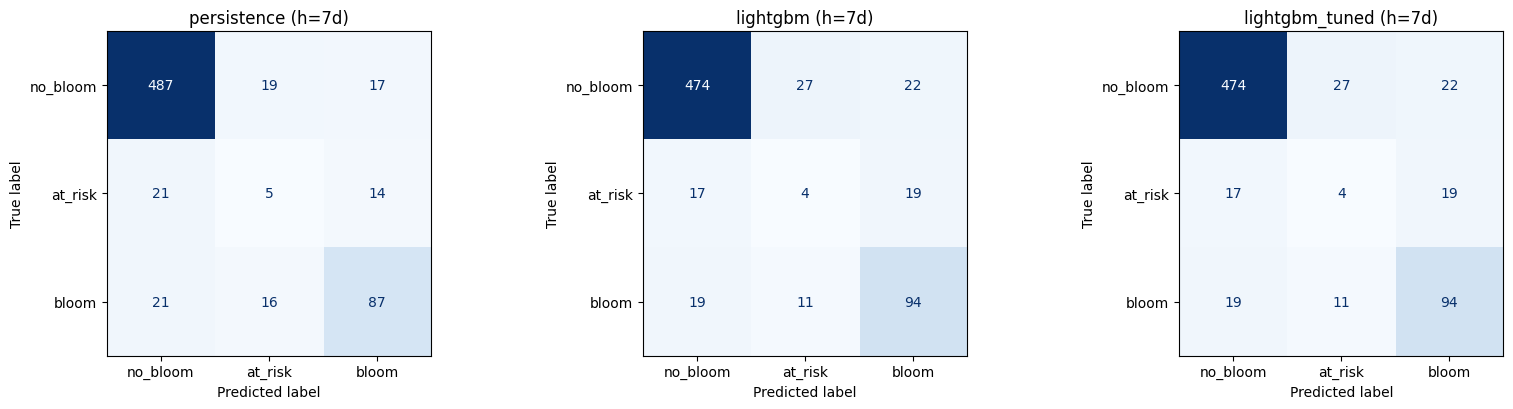


=== h=14d LightGBM classification report ===
              precision    recall  f1-score   support

    no_bloom       0.92      0.89      0.90       523
     at_risk       0.06      0.05      0.05        40
       bloom       0.61      0.70      0.65       124

    accuracy                           0.81       687
   macro avg       0.53      0.55      0.54       687
weighted avg       0.81      0.81      0.81       687



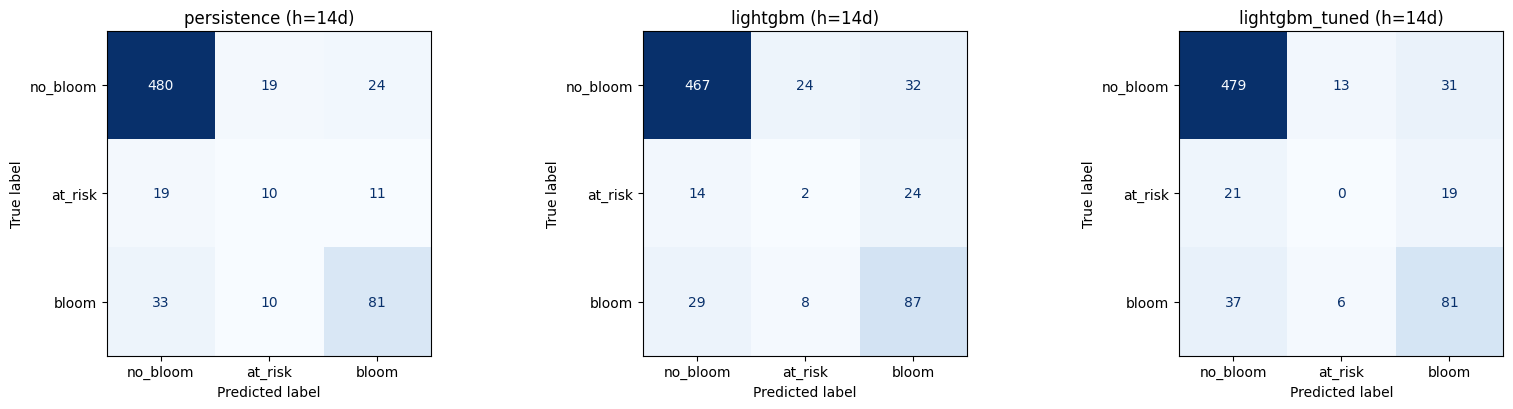


=== Checks ===
⚠️ h=7d: lightgbm does NOT beat persistence on macro-F1 (0.58 vs 0.59).
⚠️ h=7d: lightgbm at_risk recall is low (0.1).
⚠️ h=7d: lightgbm_tuned does NOT beat persistence on macro-F1 (0.58 vs 0.59).
⚠️ h=7d: lightgbm_tuned at_risk recall is low (0.1).
⚠️ h=14d: lightgbm does NOT beat persistence on macro-F1 (0.537 vs 0.613).
⚠️ h=14d: lightgbm at_risk recall is low (0.05).
⚠️ h=14d: lightgbm_tuned does NOT beat persistence on macro-F1 (0.513 vs 0.613).
⚠️ h=14d: lightgbm_tuned at_risk recall is low (0.0).


In [ ]:
# MODEL 7: Final evaluation on the held-out test period (run once, after the models are final)
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)

OUT_DIR = "data/processed/models"
CLASSES = ['no_bloom', 'at_risk', 'bloom']
PCOLS = [f'p_{c}' for c in CLASSES]
split = json.load(open(f"{OUT_DIR}/split_info.json"))
print(f"Test period starts {split['test_start']}\n")

def score(y_true, proba):
    pred = np.asarray(proba).argmax(1)
    out = {'macro_f1': f1_score(y_true, pred, labels=[0, 1, 2], average='macro', zero_division=0),
           'macro_precision': precision_score(y_true, pred, labels=[0, 1, 2], average='macro', zero_division=0),
           'macro_recall': recall_score(y_true, pred, labels=[0, 1, 2], average='macro', zero_division=0)}
    for k, c in enumerate(CLASSES):
        out[f'{c}_recall'] = recall_score(y_true, pred, labels=[k], average='macro', zero_division=0)
    try:
        out['roc_auc_ovr'] = roc_auc_score(y_true, proba, multi_class='ovr', average='macro', labels=[0, 1, 2])
    except ValueError:
        out['roc_auc_ovr'] = np.nan
    return out

rows, preds, probas = [], {}, {}
for h in split['horizons']:
    lgbm = pd.read_csv(f"{OUT_DIR}/test_proba_lgbm_h{h}.csv", index_col=0, parse_dates=True)
    y_true = lgbm['y_true'].values
    print(f"h={h}d test class counts:", dict(zip(CLASSES, np.bincount(y_true, minlength=3))))

    candidates = {'persistence': np.eye(3)[lgbm['persistence_pred'].values],
                  'lightgbm': lgbm[PCOLS].values}
    wpath = f"{OUT_DIR}/decision_weights.json"            # from MODEL 6
    if os.path.exists(wpath):
        pw = lgbm[PCOLS].values * np.array(json.load(open(wpath))[str(h)])
        candidates['lightgbm_tuned'] = pw / pw.sum(1, keepdims=True)
    for name in ['logistic_regression', 'decision_tree']:
        path = f"{OUT_DIR}/test_proba_{name}_h{h}.csv"
        if os.path.exists(path):
            candidates[name] = pd.read_csv(path, index_col=0)[PCOLS].values

    for name, proba in candidates.items():
        rows.append({'horizon': h, 'model': name, **score(y_true, proba)})
        preds[(h, name)] = (y_true, proba.argmax(1))
        probas[(h, name)] = proba

# --- 7a. Results table ---
results = pd.DataFrame(rows).set_index(['horizon', 'model']).round(3)
results.to_csv(f"{OUT_DIR}/test_results.csv")
print("\n=== TEST SET RESULTS ===")
print(results.to_string())
print("Note: persistence gives hard 0/1 predictions, so its ROC-AUC is not comparable to the probabilistic models.")

# --- 7b. Per-class detail and confusion matrices ---
for h in split['horizons']:
    y_true, y_pred = preds[(h, 'lightgbm')]
    print(f"\n=== h={h}d LightGBM classification report ===")
    print(classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=CLASSES, zero_division=0))

    panel = [m for m in ['persistence', 'lightgbm', 'lightgbm_tuned'] if (h, m) in preds]
    fig, axes = plt.subplots(1, len(panel), figsize=(5.5 * len(panel), 4.2))
    for ax, name in zip(axes, panel):
        yt, yp = preds[(h, name)]
        ConfusionMatrixDisplay.from_predictions(yt, yp, labels=[0, 1, 2], display_labels=CLASSES,
                                                ax=ax, colorbar=False, cmap='Blues')
        ax.set_title(f"{name} (h={h}d)")
    plt.tight_layout(); plt.show()

# --- 7c. Automatic checks against persistence ---
print("\n=== Checks ===")
for h in split['horizons']:
    p = results.loc[(h, 'persistence')]
    for name in [n for n in ['lightgbm', 'lightgbm_tuned'] if (h, n) in results.index]:
        m = results.loc[(h, name)]
        if m['macro_f1'] <= p['macro_f1']:
            print(f"⚠️ h={h}d: {name} does NOT beat persistence on macro-F1 ({m['macro_f1']} vs {p['macro_f1']}).")
        else:
            print(f"✅ h={h}d: {name} beats persistence on macro-F1 ({m['macro_f1']} vs {p['macro_f1']}); "
                  "check the bootstrap interval below before calling it real.")
        if m['at_risk_recall'] < 0.3:
            print(f"⚠️ h={h}d: {name} at_risk recall is low ({m['at_risk_recall']}).")

In [ ]:
# MODEL 8: Deeper evaluation (uses preds, probas, and split from MODEL 7)
# (1) Transition days: the class changed between issue and target date, so persistence is always
#     wrong; this is where a model can add value.
# (2) Month-block bootstrap: is a model's macro-F1 gain over persistence bigger than test-set noise?
# (3) Bloom vs no bloom: Brier skill score against monthly climatology from the training period.
rng = np.random.default_rng(42)
N_BOOT = 1000
mf1 = lambda yt, yp: f1_score(yt, yp, labels=[0, 1, 2], average='macro', zero_division=0)

for h in split['horizons']:
    lgbm = pd.read_csv(f"{OUT_DIR}/test_proba_lgbm_h{h}.csv", index_col=0, parse_dates=True)
    y_true = lgbm['y_true'].values
    pers = lgbm['persistence_pred'].values
    models_h = [m for (hh, m) in preds if hh == h and m != 'persistence']

    # (1) Transition days
    onset, ending = y_true > pers, y_true < pers
    print(f"\n=== h={h}d | transition days: {onset.sum()} worsening, {ending.sum()} improving "
          f"(of {len(y_true)} test days) ===")
    trans_rows = []
    for m in models_h:
        yp = preds[(h, m)][1]
        trans_rows.append({'model': m,
                           'worsening_caught': (yp[onset] == y_true[onset]).mean() if onset.any() else np.nan,
                           'improving_caught': (yp[ending] == y_true[ending]).mean() if ending.any() else np.nan})
    print(pd.DataFrame(trans_rows).set_index('model').round(3).to_string())

    # (2) Bootstrap of the macro-F1 difference vs persistence, resampling whole months
    months = lgbm.index.to_period('M')
    uniq = months.unique()
    idx_by_month = {mo: np.where(months == mo)[0] for mo in uniq}
    diffs = {m: [] for m in models_h}
    for _ in range(N_BOOT):
        idx = np.concatenate([idx_by_month[mo] for mo in rng.choice(uniq, len(uniq), replace=True)])
        base = mf1(y_true[idx], pers[idx])
        for m in models_h:
            diffs[m].append(mf1(y_true[idx], preds[(h, m)][1][idx]) - base)
    ci = pd.DataFrame({m: np.percentile(v, [2.5, 50, 97.5]) for m, v in diffs.items()},
                      index=['ci_low', 'median', 'ci_high']).T
    ci['clearly_better'] = ci['ci_low'] > 0
    print(f"\nMacro-F1 minus persistence, 95% month-block bootstrap interval (h={h}d):")
    print(ci.round(3).to_string())

    # (3) Bloom skill (Brier score: lower is better; BSS > 0 beats climatology)
    oof = pd.read_csv(f"{OUT_DIR}/oof_proba_lgbm_h{h}.csv", index_col=0, parse_dates=True)
    is_bloom_tr = oof['y_true'] == 2
    clim = (is_bloom_tr.groupby(oof.index.month).mean()
            .reindex(lgbm.index.month).fillna(is_bloom_tr.mean()).values)
    obs = (y_true == 2).astype(float)
    bs_clim = np.mean((clim - obs) ** 2)
    brier_rows = [{'model': 'climatology', 'brier': bs_clim, 'BSS_vs_climatology': 0.0}]
    for m in ['persistence'] + models_h:
        bs = np.mean((probas[(h, m)][:, 2] - obs) ** 2)
        brier_rows.append({'model': m, 'brier': bs, 'BSS_vs_climatology': 1 - bs / bs_clim})
    print(f"\nBinary bloom forecast skill (h={h}d):")
    print(pd.DataFrame(brier_rows).set_index('model').round(3).to_string())



=== h=7d | transition days: 58 worsening, 50 improving (of 687 test days) ===
                     worsening_caught  improving_caught
model                                                  
lightgbm                        0.259              0.10
lightgbm_tuned                  0.259              0.10
logistic_regression             0.379              0.14
decision_tree                   0.207              0.22

Macro-F1 minus persistence, 95% month-block bootstrap interval (h=7d):
                     ci_low  median  ci_high  clearly_better
lightgbm             -0.052  -0.008    0.046           False
lightgbm_tuned       -0.052  -0.008    0.046           False
logistic_regression  -0.087  -0.024    0.041           False
decision_tree        -0.001   0.045    0.093           False

Binary bloom forecast skill (h=7d):
                     brier  BSS_vs_climatology
model                                         
climatology          0.141               0.000
persistence          0.099    

## Ordinal early-warning model (at-risk detection)

The 3-class LightGBM almost never predicts `at_risk`: it's the smallest class, sandwiched between the other two, so its probability rarely comes out on top. This section replaces it with two yes/no models:

* **Q1:** will cell counts be ≥ 1,000 cells/L (at-risk or bloom)? This question has about three times as many positive days to learn from as `at_risk` alone.
* **Q2:** will they be ≥ 10,000 cells/L (bloom)?

A day is labeled bloom if Q2's probability passes its threshold, otherwise at-risk if Q1's does, otherwise no bloom. Thresholds are chosen on out-of-fold training predictions only, in two modes: **macro-F1** (best overall score) and **at-risk-first** (catch the most at-risk days while giving up at most 0.03 cross-validation macro-F1).

The trade-off table and chart treat Q1 as an **early-warning alert**: at each threshold, how many at-risk and bloom days get flagged, and how many alerts are false alarms. The curve is for reporting the trade-off; the operating point should be chosen from the cross-validation table (or by the Challenge Advisor), not from the test curve.

**Update:** MODEL 19 (at the end of the notebook) rebuilds this early-warning question with the onset model's improvements and compares the two.



=== h=7d | thresholds (Q1, Q2) chosen on CV: macro-F1 mode (0.55, 0.55), at-risk-first mode (0.45, 0.8)
Training-period CV (out-of-fold; thresholds were fit on these rows, so slightly optimistic):
                         macro_f1  at_risk_recall  at_risk_precision  bloom_recall  days_labeled_at_risk
persistence                 0.659           0.314              0.306         0.816                 301.0
ordinal (macro-F1)          0.615           0.280              0.275         0.696                 298.0
ordinal (at-risk-first)     0.589           0.481              0.225         0.565                 628.0

Early-warning alert on the test period (h=7d): alert when P(>= 1,000 cells/L) > threshold
             at_risk_days_caught  bloom_days_caught  alerts_correct  false_alarms_per_hit  alert_days
0.2                         0.78               0.94            0.55                  0.81         266
0.3                         0.75               0.93            0.69                  0.

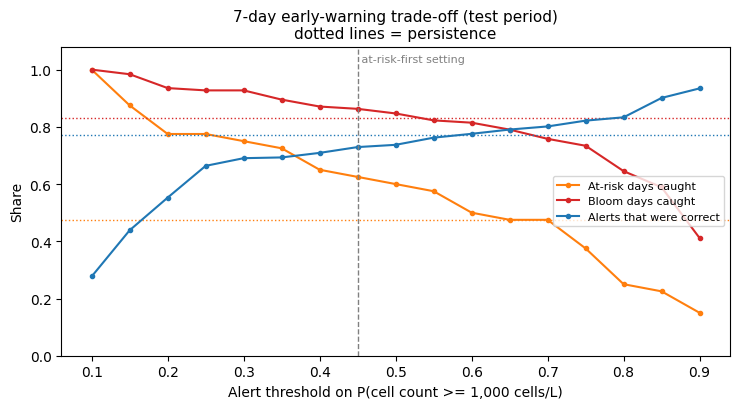


=== h=14d | thresholds (Q1, Q2) chosen on CV: macro-F1 mode (0.55, 0.45), at-risk-first mode (0.45, 0.8)
Training-period CV (out-of-fold; thresholds were fit on these rows, so slightly optimistic):
                         macro_f1  at_risk_recall  at_risk_precision  bloom_recall  days_labeled_at_risk
persistence                 0.617           0.276              0.266         0.755                 304.0
ordinal (macro-F1)          0.552           0.198              0.236         0.688                 246.0
ordinal (at-risk-first)     0.528           0.444              0.180         0.485                 722.0

Early-warning alert on the test period (h=14d): alert when P(>= 1,000 cells/L) > threshold
             at_risk_days_caught  bloom_days_caught  alerts_correct  false_alarms_per_hit  alert_days
0.2                         0.78               0.94            0.47                  1.14         314
0.3                         0.70               0.87            0.63                  

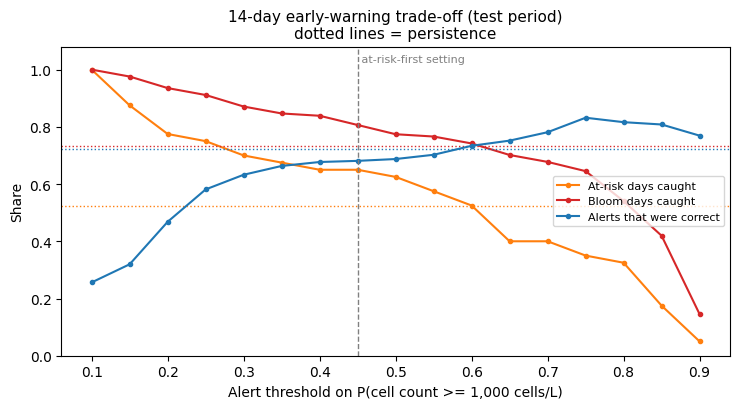


=== TEST SET: ordinal model vs persistence and the 3-class LightGBM ===
                                 macro_f1  at_risk_recall  at_risk_precision  bloom_recall  days_labeled_at_risk
horizon model                                                                                                   
7       persistence                 0.590           0.125              0.125         0.702                    40
        lightgbm 3-class            0.580           0.100              0.095         0.758                    42
        ordinal (macro-F1)          0.598           0.125              0.185         0.758                    27
        ordinal (at-risk-first)     0.599           0.425              0.170         0.524                   100
14      persistence                 0.613           0.250              0.256         0.653                    39
        lightgbm 3-class            0.537           0.050              0.059         0.702                    34
        ordinal (macro-

In [ ]:
# MODEL 9: Ordinal early-warning model
# Two yes/no models, P(>= 1,000 cells/L) and P(>= 10,000 cells/L), replace the 3-class model for
# at-risk detection. Thresholds are chosen on out-of-fold data; the test set is scored once per mode.
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from itertools import product
from sklearn.metrics import f1_score, recall_score, precision_score

THRESH_GRID = np.round(np.arange(0.10, 0.91, 0.05), 2)
MAX_F1_LOSS = 0.03        # at-risk-first mode may give up this much CV macro-F1 to catch more at-risk days

def ordinal_fit_predict(params, X_a, y_a, X_b):
    pb = {**params, 'objective': 'binary'}
    p1 = lgb.LGBMClassifier(**pb).fit(X_a, (y_a >= 1).astype(int)).predict_proba(X_b)[:, 1]
    p2 = lgb.LGBMClassifier(**pb).fit(X_a, (y_a >= 2).astype(int)).predict_proba(X_b)[:, 1]
    return p1, np.minimum(p2, p1)          # P(>= 10,000) can't exceed P(>= 1,000)

def to_class(p1, p2, t1, t2):
    return np.where(p2 > t2, 2, np.where(p1 > t1, 1, 0))

def macro_f1(y, p):
    return f1_score(y, p, labels=[0, 1, 2], average='macro', zero_division=0)

def summary(y, p):
    return {'macro_f1': macro_f1(y, p),
            'at_risk_recall': recall_score(y, p, labels=[1], average='macro', zero_division=0),
            'at_risk_precision': precision_score(y, p, labels=[1], average='macro', zero_division=0),
            'bloom_recall': recall_score(y, p, labels=[2], average='macro', zero_division=0),
            'days_labeled_at_risk': int((p == 1).sum())}

def alert_point(y, alert):
    hits = alert & (y >= 1)
    return {'at_risk_days_caught': alert[y == 1].mean(),
            'bloom_days_caught': alert[y == 2].mean(),
            'alerts_correct': hits.sum() / max(alert.sum(), 1),
            'false_alarms_per_hit': (alert.sum() - hits.sum()) / max(hits.sum(), 1),
            'alert_days': int(alert.sum())}

ord_results, ord_settings, tradeoffs = [], {}, {}
for h in HORIZONS:
    X, y = make_dataset(h)
    tr = X.index < TEST_START - pd.Timedelta(days=h)
    te = X.index >= TEST_START
    X_tr, y_tr = X[tr], y[tr].values
    best = res[res.horizon == h].iloc[0]
    params = lgbm_params(best.n_estimators, best.learning_rate, best.max_depth)

    # (1) Out-of-fold predictions on the training period, used to choose thresholds
    o1 = np.full(len(X_tr), np.nan)
    o2 = o1.copy()
    for t, va in time_folds(X_tr.index, gap_days=h):
        o1[va], o2[va] = ordinal_fit_predict(params, X_tr.iloc[t], y_tr[t], X_tr.iloc[va])
    m = ~np.isnan(o1)
    yo, q1, q2 = y_tr[m], o1[m], o2[m]
    grid = {(float(a), float(b)): macro_f1(yo, to_class(q1, q2, a, b)) for a, b in product(THRESH_GRID, THRESH_GRID)}
    t_f1 = max(grid, key=grid.get)
    t_ar = max([t for t, f in grid.items() if f >= grid[t_f1] - MAX_F1_LOSS],
               key=lambda t: recall_score(yo, to_class(q1, q2, *t), labels=[1], average='macro', zero_division=0))
    ord_settings[str(h)] = {'macro_f1_mode': [float(v) for v in t_f1],
                            'at_risk_first_mode': [float(v) for v in t_ar]}

    pers_cv = X_tr['last_bloom_level'].fillna(0).astype(int).values[m]
    cv = pd.DataFrame({'persistence': summary(yo, pers_cv),
                       'ordinal (macro-F1)': summary(yo, to_class(q1, q2, *t_f1)),
                       'ordinal (at-risk-first)': summary(yo, to_class(q1, q2, *t_ar))}).T
    print(f"\n=== h={h}d | thresholds (Q1, Q2) chosen on CV: macro-F1 mode {t_f1}, at-risk-first mode {t_ar}")
    print("Training-period CV (out-of-fold; thresholds were fit on these rows, so slightly optimistic):")
    print(cv.round(3).to_string())

    # (2) Final fit on the whole training period; score the test set once
    p1, p2 = ordinal_fit_predict(params, X_tr, y_tr, X[te])
    yt = y[te].values
    pers = X.loc[te, 'last_bloom_level'].fillna(0).astype(int).values
    pd.DataFrame({'p_ge_1000': p1, 'p_ge_10000': p2, 'y_true': yt, 'persistence_pred': pers},
                 index=X.index[te]).to_csv(f"{OUT_DIR}/test_proba_ordinal_h{h}.csv")
    for name, pred in [('persistence', pers),
                       ('lightgbm 3-class', preds[(h, 'lightgbm')][1]) if (h, 'lightgbm') in globals().get('preds', {}) else (None, None),
                       ('ordinal (macro-F1)', to_class(p1, p2, *t_f1)),
                       ('ordinal (at-risk-first)', to_class(p1, p2, *t_ar))]:
        if name:
            ord_results.append({'horizon': h, 'model': name, **summary(yt, pred)})

    # (3) Early-warning trade-off: alert when P(>= 1,000 cells/L) passes a threshold
    tro = pd.DataFrame([{'threshold': t, **alert_point(yt, p1 > t)} for t in THRESH_GRID])
    tradeoffs[h] = tro
    tro.to_csv(f"{OUT_DIR}/early_warning_tradeoff_h{h}.csv", index=False)
    pers_pt = alert_point(yt, pers >= 1)
    print(f"\nEarly-warning alert on the test period (h={h}d): alert when P(>= 1,000 cells/L) > threshold")
    show_t = tro['threshold'].isin(np.round(np.arange(0.2, 0.81, 0.1), 2))
    print(pd.concat([tro[show_t].set_index('threshold'),
                     pd.DataFrame([pers_pt], index=['persistence'])]).round(2).to_string())

    # (4) Chart for the slides
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for col, color, label in [('at_risk_days_caught', 'tab:orange', 'At-risk days caught'),
                              ('bloom_days_caught', 'tab:red', 'Bloom days caught'),
                              ('alerts_correct', 'tab:blue', 'Alerts that were correct')]:
        ax.plot(tro['threshold'], tro[col], color=color, marker='o', ms=3, label=label)
        ax.axhline(pers_pt[col], color=color, ls=':', lw=1)
    ax.axvline(t_ar[0], color='grey', ls='--', lw=1)
    ax.text(t_ar[0], 1.02, ' at-risk-first setting', color='grey', fontsize=8, va='bottom')
    ax.set_xlabel('Alert threshold on P(cell count >= 1,000 cells/L)')
    ax.set_ylabel('Share')
    ax.set_ylim(0, 1.08)
    ax.set_title(f'{h}-day early-warning trade-off (test period)\ndotted lines = persistence', fontsize=11)
    ax.legend(fontsize=8, loc='center right')
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/early_warning_tradeoff_h{h}.png", dpi=150)
    plt.show()

ord_table = pd.DataFrame(ord_results).set_index(['horizon', 'model']).round(3)
ord_table.to_csv(f"{OUT_DIR}/test_results_ordinal.csv")
json.dump(ord_settings, open(f"{OUT_DIR}/ordinal_thresholds.json", "w"), indent=1)
print("\n=== TEST SET: ordinal model vs persistence and the 3-class LightGBM ===")
print(ord_table.to_string())
print("\nReminder: the test period has been evaluated many times this project, so treat these as optimistic; "
      "the CV tables above are the fairer comparison.")


## 14-day bloom outlook and combined early-warning flag

**Target "bloom any day in the next 14 days."** This would improve the forecast's usefulness and its edge over persistence. It answers the planning question people actually ask ("will there be a bloom in the next two weeks?") and has noticeably more skill: on the test period, Brier skill against monthly climatology was 0.57 vs 0.27 for persistence, compared with 0.34 vs 0.20 for the current "bloom on day 14" target. Its ability to rank days is about the same as the day-14 target's (cross-validation AUC 0.824 vs 0.827), so the gain comes with no loss in ranking. This is the recommended 14-day product.

**Combined early-warning flag.** On its own, a flag from the bloom probability fails at bloom onsets: its highest probabilities fall on days already inside a bloom. The at-risk band (last sample 1,000–10,000 cells/L) is a real precursor, warning of 59% of onsets about 8 days ahead. Combining them is the improvement. "Band OR model ≥ 0.7" warns of more onsets (65% vs 59%, median lead 8 days for both), and more of its flags are correct (75% vs 52%). The cost is about 3 times as many flag days (1,509 vs 476). Some of its correct flags happen during blooms that are already underway, so the 75% is somewhat flattering.

Numbers are from the official Colab run. Onsets are judged across 2012–2026 (out-of-fold predictions for the training years, the final model for the test years), because the test period alone has only 2 onsets. With about 17 onsets, each one moves the percentages by about 6 points: treat them as directional.


In [ ]:
# MODEL 10: 14-day bloom outlook ("bloom any day in the next 14 days") and combined early-warning flag
# 10a compares "bloom any day in the next 14 days" with "bloom on day 14"; 10b-10c judge warning
# rules (at-risk band alone vs band OR outlook probability) on bloom onsets across the whole record.
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

OUTLOOK_DAYS = 14
FLAG_PROB = 0.7            # combined flag: at-risk band OR P(bloom in next 14 days) >= FLAG_PROB
ONSET_QUIET_DAYS = 30      # an onset = a bloom sample with no bloom sample in the previous 30 days

labels = hab_daily['bloom_level']
issue = pd.DatetimeIndex(label_dates)
best = res[res.horizon == OUTLOOK_DAYS].iloc[0]
params = {**lgbm_params(best.n_estimators, best.learning_rate, best.max_depth), 'objective': 'binary'}

def window_target(dates, level, days=OUTLOOK_DAYS):
    """1 if any sample in (t, t + days] reaches `level`; NaN if no sample in the window."""
    out = np.full(len(dates), np.nan)
    li, lv = labels.index.values, labels.values
    for k, t in enumerate(dates.values):
        in_window = (li > t) & (li <= t + np.timedelta64(days, 'D'))
        if in_window.any():
            out[k] = float(lv[in_window].max() >= level)
    return out

def outlook_features(dates, target_offset):
    X = F.reindex(dates).copy()
    X.index = dates
    target_day = dates + pd.Timedelta(days=target_offset)
    X['doy_sin'] = np.sin(2 * np.pi * target_day.dayofyear / 365.25)
    X['doy_cos'] = np.cos(2 * np.pi * target_day.dayofyear / 365.25)
    return X

# --- 10a. Window target vs the current point target ---
is_train = issue < TEST_START - pd.Timedelta(days=OUTLOOK_DAYS)
is_test = issue >= TEST_START
y_point = labels.reindex(issue + pd.Timedelta(days=OUTLOOK_DAYS)).values
y_point = np.where(np.isnan(y_point), np.nan, (y_point >= 2).astype(float))
y_window = window_target(issue, 2)
targets = {'bloom on day 14 (current)': (outlook_features(issue, OUTLOOK_DAYS), y_point),
           'bloom any day in next 14': (outlook_features(issue, OUTLOOK_DAYS // 2), y_window)}

rows, outlook_model = [], None
for name, (X, y) in targets.items():
    tr, te = is_train & ~np.isnan(y), is_test & ~np.isnan(y)
    X_tr, y_tr = X[tr], y[tr].astype(int)
    oof = np.full(len(X_tr), np.nan)
    for t, va in time_folds(X_tr.index, gap_days=OUTLOOK_DAYS):
        oof[va] = lgb.LGBMClassifier(**params).fit(X_tr.iloc[t], y_tr[t]).predict_proba(X_tr.iloc[va])[:, 1]
    m = ~np.isnan(oof)
    model = lgb.LGBMClassifier(**params).fit(X_tr, y_tr)
    p_test, y_test = model.predict_proba(X[te])[:, 1], y[te]
    clim = pd.Series(y_tr, index=X_tr.index).groupby(X_tr.index.month).mean()
    p_clim = clim.reindex(X[te].index.month).fillna(y_tr.mean()).values
    p_pers = (X.loc[te, 'last_bloom_level'].fillna(0) >= 2).values.astype(float)
    brier = lambda p: np.mean((p - y_test) ** 2)
    rows.append({'target': name, 'test_bloom_rate': y_test.mean(),
                 'cv_auc': roc_auc_score(y_tr[m], oof[m]), 'test_auc': roc_auc_score(y_test, p_test),
                 'BSS_model': 1 - brier(p_test) / brier(p_clim),
                 'BSS_persistence': 1 - brier(p_pers) / brier(p_clim)})
    if name.startswith('bloom any day'):
        outlook_model, outlook_X_tr, outlook_y_tr = model, X_tr, y_tr

target_table = pd.DataFrame(rows).set_index('target').round(3)
target_table.to_csv(f"{OUT_DIR}/outlook_target_comparison.csv")
print("=== 14-day target comparison (Brier skill vs monthly climatology; higher is better) ===")
print(target_table.to_string())

# --- 10b. Daily outlook probabilities across the whole record ---
# Training years use out-of-fold predictions; test years use the final outlook model.
pieces = []
for t, va in time_folds(outlook_X_tr.index, gap_days=OUTLOOK_DAYS):
    fold_model = lgb.LGBMClassifier(**params).fit(outlook_X_tr.iloc[t], outlook_y_tr[t])
    fold_days = pd.date_range(outlook_X_tr.index[va].min(), outlook_X_tr.index[va].max(), freq='D')
    pieces.append(pd.Series(fold_model.predict_proba(outlook_features(fold_days, OUTLOOK_DAYS // 2))[:, 1],
                            index=fold_days))
test_days = pd.date_range(TEST_START, F.index.max() - pd.Timedelta(days=OUTLOOK_DAYS), freq='D')
pieces.append(pd.Series(outlook_model.predict_proba(outlook_features(test_days, OUTLOOK_DAYS // 2))[:, 1],
                        index=test_days))
p_outlook = pd.concat(pieces)
p_outlook = p_outlook[~p_outlook.index.duplicated()]
days = p_outlook.index
last_level = outlook_features(days, 0)['last_bloom_level'].fillna(0)
bloom_ahead = pd.Series(window_target(days, 2), index=days)

# --- 10c. Bloom onsets and warning rules ---
onsets = []
for d in labels[(labels >= 2) & (labels.index >= days.min() + pd.Timedelta(days=ONSET_QUIET_DAYS)) &
                (labels.index <= days.max())].index:
    prior = labels[(labels.index < d) & (labels.index >= d - pd.Timedelta(days=ONSET_QUIET_DAYS))]
    if len(prior) >= 2 and prior.max() < 2:
        onsets.append(d)
print(f"\nBloom onsets judged: {len(onsets)} ({days.min().date()} to {days.max().date()})")

def judge(flag):
    before = [flag[(flag.index >= d - pd.Timedelta(days=OUTLOOK_DAYS)) & (flag.index < d)] for d in onsets]
    leads = [(d - f[f].index.min()).days for d, f in zip(onsets, before) if f.any()]
    known = bloom_ahead.notna()
    return {'flag_days': int(flag.sum()),
            'onsets_warned_1_14d_before': np.mean([f.any() for f in before]),
            'median_lead_days': np.median(leads) if leads else np.nan,
            'flags_followed_by_bloom_14d': bloom_ahead[flag & known].mean()}

band = pd.Series((last_level == 1).values, index=days)                # last sample 1,000-10,000 cells/L
combined = band | (p_outlook >= FLAG_PROB)
flag_table = pd.DataFrame({'at-risk band (last sample 1,000-10,000)': judge(band),
                           f'band OR outlook >= {FLAG_PROB}': judge(combined)}).T.round(2)
flag_table.to_csv(f"{OUT_DIR}/early_warning_flag_comparison.csv")
print("\n=== Warning rules judged on bloom onsets ===")
print(flag_table.to_string())
print("Note: some correct flags fall during blooms already underway, and each onset moves the "
      f"onset shares by about {100 / len(onsets):.0f} points.")


=== 14-day target comparison (Brier skill vs monthly climatology; higher is better) ===
                           test_bloom_rate  cv_auc  test_auc  BSS_model  BSS_persistence
target                                                                                  
bloom on day 14 (current)            0.181   0.831     0.929      0.335            0.203
bloom any day in next 14             0.322   0.818     0.969      0.655            0.265

Bloom onsets judged: 17 (2012-04-06 to 2026-08-22)

=== Warning rules judged on bloom onsets ===
                                         flag_days  onsets_warned_1_14d_before  median_lead_days  flags_followed_by_bloom_14d
at-risk band (last sample 1,000-10,000)      476.0                        0.59               8.0                         0.52
band OR outlook >= 0.7                      1515.0                        0.65               8.0                         0.75
Note: some correct flags fall during blooms already underway, and each onset mov

Explaining 687 test rows x 66 features


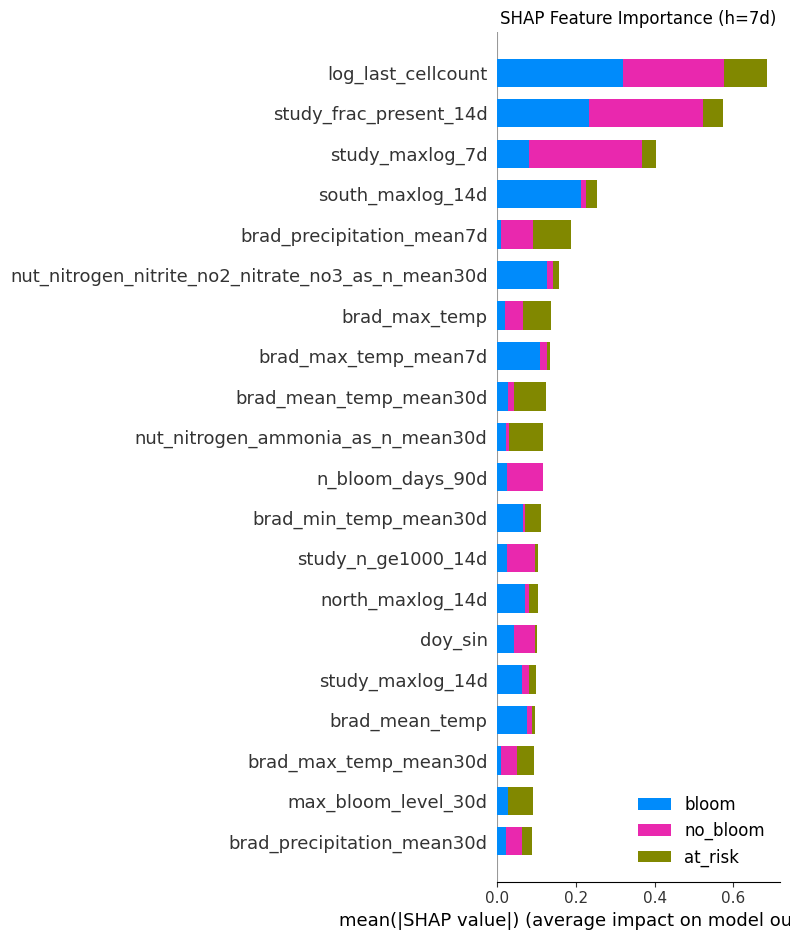

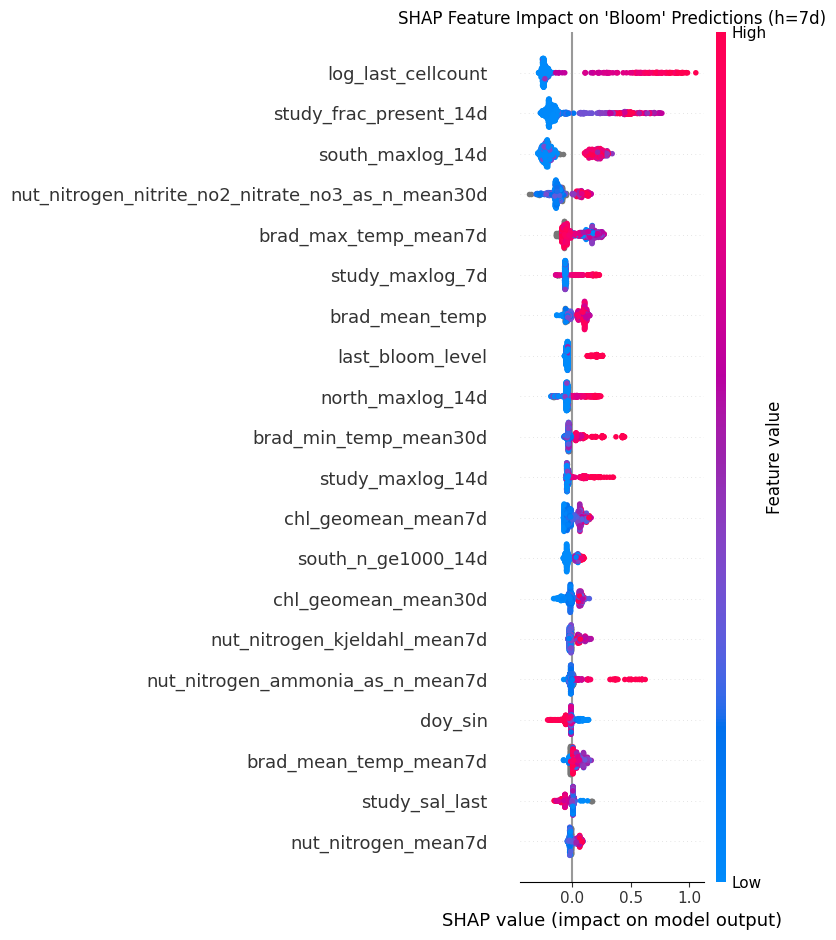

In [ ]:
# MODEL 11: SHAP explanation of the final 7-day LightGBM model
# Uses the exact test rows and feature order saved in MODEL 5.
import os
import json
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount('/content/drive/')
DATA_DIR = globals().get('DATA_DIR', "/content/drive/MyDrive/BiointerphaseD /")   # same folder as SETUP
os.chdir(DATA_DIR)

OUT_DIR = "data/processed/models"
CLASSES = ['no_bloom', 'at_risk', 'bloom']
h = 7

model = joblib.load(f"{OUT_DIR}/lgbm_h{h}.joblib")
cfg = json.load(open(f"{OUT_DIR}/lgbm_h{h}_config.json"))
X_te = pd.read_csv(f"{OUT_DIR}/X_test_h{h}.csv", index_col=0, parse_dates=True)[cfg['features']]
print(f"Explaining {len(X_te)} test rows x {X_te.shape[1]} features")

explainer = shap.TreeExplainer(model)
vals = explainer(X_te).values            # shape: (rows, features, classes)

# Global importance, stacked by class
shap.summary_plot([vals[:, :, k] for k in range(vals.shape[2])], X_te,
                  plot_type="bar", class_names=CLASSES, show=False)
plt.title(f"SHAP Feature Importance (h={h}d)")
plt.tight_layout()
plt.show()

# Direction of effects on the 'bloom' class
shap.summary_plot(vals[:, :, 2], X_te, show=False)
plt.title(f"SHAP Feature Impact on 'Bloom' Predictions (h={h}d)")
plt.tight_layout()
plt.show()


## Bloom onset model (Mia's priority)

Mia's guidance (Nov 3): the most useful output is the **probability that a bloom starts within the next 7 or 14 days**, flagging rising risk before a bloom is established. Bloom level stays a secondary output once a bloom has begun (MODELS 5–9).

How this cell frames it:

* **Who gets a forecast:** only days in a "quiet" state, meaning no bloom sample in the previous `ONSET_QUIET_DAYS` days (default 30). Days inside or just after a bloom are the persistence problem, already handled by the other models.
* **Target:** 1 if any sample in the next 7 (or 14) days is a bloom (> 10,000 cells/L).
* **Baseline:** the seasonal average onset rate for that calendar month. "Same as last week" always predicts no onset here, so it isn't a useful benchmark.
* **Calibration:** the models use balanced class weights, which rank onset days well but inflate probabilities. A calibration step (Platt scaling, learned from out-of-fold predictions) converts scores into realistic probabilities without changing the order of days.
* **Evaluation:** onsets are rare (the test period has about 2), so the main scores come from time-ordered cross-validation across the whole record; the test-period scores are shown for reference.

Try a shorter quiet period (for example 14 days) to see how the number of onset events and the scores change. This is open question 7 for Mia.


In [ ]:
# MODEL 12: First bloom onset model: chance a bloom starts within 7 or 14 days, given no recent bloom
# Needs: F, hab_daily, label_dates, TEST_START, time_folds, res, lgbm_params, OUT_DIR (MODELS 2-4).
import json
import joblib
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.linear_model import LogisticRegression

ONSET_QUIET_DAYS = 30            # "quiet" = no bloom sample in this many days before the issue date
ONSET_HORIZONS = [7, 14]
ALERT_GRID = [0.05, 0.1, 0.15, 0.2, 0.3]     # on calibrated probabilities

# --- 12a. Calibration helpers (Platt scaling) ---
# Balanced class weights help the model notice rare onsets but inflate its probabilities. Calibration
# turns scores into realistic probabilities without changing the order of days. Each fold is
# calibrated using only earlier folds.
def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def fit_calibration(p, y):
    """Returns (a, b) for p_calibrated = sigmoid(a * logit(p) + b). The slope is kept positive so the
    order of days never flips; if the data can't support a positive slope, only the level is shifted
    (a = 1, b chosen so the average prediction matches the observed onset rate)."""
    z, y = _logit(np.asarray(p)), np.asarray(y)
    lr = LogisticRegression(C=1e6).fit(z.reshape(-1, 1), y)
    a, b = float(lr.coef_[0, 0]), float(lr.intercept_[0])
    if a > 0:
        return a, b
    lo, hi = -20.0, 20.0
    for _ in range(60):                                   # bisection on the shift
        mid = (lo + hi) / 2
        if np.mean(1 / (1 + np.exp(-(z + mid)))) > y.mean():
            hi = mid
        else:
            lo = mid
    return 1.0, (lo + hi) / 2

def apply_calibration(p, a, b):
    return 1 / (1 + np.exp(-(a * _logit(np.asarray(p)) + b)))

def rolling_calibration(raw, y, fold_id):
    """Calibrate each fold with a mapping fitted on the earlier folds only (NaN for the first fold)."""
    out = np.full(len(raw), np.nan)
    for f in sorted(set(fold_id[fold_id >= 0])):
        past = (fold_id >= 0) & (fold_id < f)
        if past.sum() and len(set(y[past])) == 2:
            out[fold_id == f] = apply_calibration(raw[fold_id == f], *fit_calibration(raw[past], y[past]))
    return out

labels = hab_daily['bloom_level']
lab_days, lab_vals = labels.index.values, labels.values

def quiet_mask(dates, quiet=ONSET_QUIET_DAYS):
    """True where the issue date has >= 1 sample and no bloom sample in the previous `quiet` days."""
    ok = np.zeros(len(dates), dtype=bool)
    for k, t in enumerate(pd.DatetimeIndex(dates).values):
        prior = (lab_days <= t) & (lab_days > t - np.timedelta64(quiet, 'D'))
        ok[k] = prior.any() and lab_vals[prior].max() < 2
    return ok

def onset_target(dates, horizon):
    """1 if a bloom sample falls in (t, t + horizon]; NaN if nothing was sampled in that window."""
    out = np.full(len(dates), np.nan)
    for k, t in enumerate(pd.DatetimeIndex(dates).values):
        window = (lab_days > t) & (lab_days <= t + np.timedelta64(horizon, 'D'))
        if window.any():
            out[k] = float(lab_vals[window].max() >= 2)
    return out

def onset_features(dates, horizon):
    X = F.reindex(dates).copy()
    X.index = dates
    mid = dates + pd.Timedelta(days=horizon // 2)
    X['doy_sin'] = np.sin(2 * np.pi * mid.dayofyear / 365.25)
    X['doy_cos'] = np.cos(2 * np.pi * mid.dayofyear / 365.25)
    return X

def monthly_rate(y, idx, fallback):
    return pd.Series(y, index=idx).groupby(idx.month).mean().reindex(range(1, 13)).fillna(fallback)

issue_all = pd.DatetimeIndex(label_dates)
issue = issue_all[quiet_mask(issue_all)]
print(f"Quiet issue days (no bloom in the previous {ONSET_QUIET_DAYS} days): {len(issue):,} of {len(issue_all):,}")

onset_models, onset_rows, onset_tradeoffs = {}, [], []
for H in ONSET_HORIZONS:
    X, y = onset_features(issue, H), onset_target(issue, H)
    keep = ~np.isnan(y)
    X, y = X[keep], y[keep].astype(int)
    best = res[res.horizon == min(res.horizon.unique(), key=lambda h: abs(h - H))].iloc[0]
    # Same LightGBM settings as before (balanced weights); calibration fixes the inflated probabilities.
    params = {**lgbm_params(best.n_estimators, best.learning_rate, best.max_depth), 'objective': 'binary'}

    # (1) Whole-record cross-validation: each fold uses a model trained only on earlier days
    oof, clim, fold_id = np.full(len(X), np.nan), np.full(len(X), np.nan), np.full(len(X), -1)
    for f, (t, va) in enumerate(time_folds(X.index, n_splits=5, gap_days=H)):
        if y[t].sum() < 5:
            continue
        model = lgb.LGBMClassifier(**params).fit(X.iloc[t], y[t])
        oof[va] = model.predict_proba(X.iloc[va])[:, 1]
        clim[va] = monthly_rate(y[t], X.index[t], y[t].mean()).reindex(X.index[va].month).values
        fold_id[va] = f
    cal_oof = rolling_calibration(oof, y, fold_id)
    m = ~np.isnan(cal_oof)                                  # rows with both raw and calibrated predictions
    brier = lambda p: np.mean((p - y[m]) ** 2)
    # AUC and average precision use raw predictions: each fold has its own calibration, so pooled
    # ranking scores of calibrated values would mix folds.
    for label, p in [('whole-record CV, raw', oof), ('whole-record CV, calibrated', cal_oof)]:
        is_raw = label.endswith('raw')
        onset_rows.append({'horizon_days': H, 'evaluation': label, 'issue_days': int(m.sum()),
                           'onset_rate': y[m].mean(), 'mean_predicted': p[m].mean(),
                           'auc': roc_auc_score(y[m], p[m]) if is_raw else np.nan,
                           'avg_precision': average_precision_score(y[m], p[m]) if is_raw else np.nan,
                           'avg_precision_seasonal': average_precision_score(y[m], clim[m]),
                           'BSS_vs_seasonal': 1 - brier(p[m]) / brier(clim[m])})

    # (2) Test period, for reference (calibrated with out-of-fold predictions from before it)
    tr, te = X.index < TEST_START - pd.Timedelta(days=H), X.index >= TEST_START
    pre = ~np.isnan(oof) & tr
    if y[tr].sum() >= 5 and te.sum() and y[te].sum() and len(set(y[pre])) == 2:
        model = lgb.LGBMClassifier(**params).fit(X[tr], y[tr])
        p_raw = model.predict_proba(X[te])[:, 1]
        p_cal = apply_calibration(p_raw, *fit_calibration(oof[pre], y[pre]))
        c_te = monthly_rate(y[tr], X.index[tr], y[tr].mean()).reindex(X.index[te].month).values
        bt = lambda p: np.mean((p - y[te]) ** 2)
        for label, p in [('test period, raw', p_raw), ('test period, calibrated', p_cal)]:
            onset_rows.append({'horizon_days': H, 'evaluation': label, 'issue_days': int(te.sum()),
                               'onset_rate': y[te].mean(), 'mean_predicted': p.mean(),
                               'auc': roc_auc_score(y[te], p), 'avg_precision': average_precision_score(y[te], p),
                               'avg_precision_seasonal': average_precision_score(y[te], c_te),
                               'BSS_vs_seasonal': 1 - bt(p) / bt(c_te)})

    # (3) Alert trade-off on the calibrated predictions
    for thr in ALERT_GRID:
        alert = cal_oof[m] >= thr
        onset_tradeoffs.append({'horizon_days': H, 'alert_threshold': thr,
                                'onsets_caught': alert[y[m] == 1].mean(),
                                'alerts_correct': y[m][alert].mean() if alert.any() else np.nan,
                                'share_of_days_alerted': alert.mean()})

    # (4) Deployment model: all quiet days, calibrated on all out-of-fold predictions
    onset_models[H] = lgb.LGBMClassifier(**params).fit(X, y)
    a, b = fit_calibration(oof[~np.isnan(oof)], y[~np.isnan(oof)])
    joblib.dump(onset_models[H], f"{OUT_DIR}/onset_h{H}.joblib")
    json.dump({'features': X.columns.tolist(), 'quiet_days': ONSET_QUIET_DAYS,
               'calibration': {'a': a, 'b': b},
               'seasonal_rate': monthly_rate(y, X.index, y.mean()).round(4).tolist()},
              open(f"{OUT_DIR}/onset_h{H}_config.json", "w"))

onset_table = pd.DataFrame(onset_rows).set_index(['horizon_days', 'evaluation']).round(3)
onset_table.to_csv(f"{OUT_DIR}/onset_results.csv")
print("\n=== Bloom onset model (baseline = seasonal average onset rate; BSS > 0 beats it) ===")
print("'mean_predicted' vs 'onset_rate' shows calibration: after calibrating, the two should be close.")
print(onset_table.to_string())
tradeoff_table = pd.DataFrame(onset_tradeoffs).set_index(['horizon_days', 'alert_threshold']).round(2)
tradeoff_table.to_csv(f"{OUT_DIR}/onset_alert_tradeoff.csv")
print("\n=== Onset alert trade-off (whole-record CV, calibrated probabilities) ===")
print(tradeoff_table.to_string())
print("\nNote: many quiet days lead up to the same onset, so 'onsets_caught' counts issue days, not distinct "
      "bloom events. Saved onset_results.csv, onset_alert_tradeoff.csv and the deployment models.")


Quiet issue days (no bloom in the previous 30 days): 2,048 of 3,431

=== Bloom onset model (baseline = seasonal average onset rate; BSS > 0 beats it) ===
'mean_predicted' vs 'onset_rate' shows calibration: after calibrating, the two should be close.
                                          issue_days  onset_rate  mean_predicted    auc  avg_precision  avg_precision_seasonal  BSS_vs_seasonal
horizon_days evaluation                                                                                                                        
7            whole-record CV, raw                676       0.058           0.115  0.607          0.106                   0.078           -0.270
             whole-record CV, calibrated         676       0.058           0.072    NaN            NaN                   0.078            0.031
             test period, raw                    414       0.019           0.146  0.906          0.210                   0.113           -1.157
             test period, cali

## Wind and seasonality (Mia's question)

Mia asked whether the wind-direction signal at longer lead times holds after accounting for seasonality, or mostly tracks seasonal conditions. Wind and blooms share a season (easterly wind and peak bloom season both fall in September–December), so this cell compares each wind measure's correlation with bloom level before and after removing the calendar-month pattern from both. The 95% intervals come from resampling whole months.

It uses the Sarasota airport wind (2022 onward) and, if one is in the data folder, the CCMP gridded wind file (`SarasotaWindData.txt`, 2019 onward and east-west only, or the longer `SarasotaWind_CCMP_2009_2026.csv`).


In [ ]:
# MODEL 13: Does the wind signal hold after accounting for seasonality?
# Spearman correlation with bloom level, before and after removing the calendar-month pattern.
import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, rankdata

N_BOOT = 500
rng = np.random.default_rng(0)
labels = hab_daily['bloom_level']
folder = globals().get('DATA_DIR', '')

# --- 13a. Wind sources (u = eastward wind in m/s; negative = wind from the east) ---
wind = feat_daily[['sar_wind_u', 'sar_wind_v']].rename(columns={'sar_wind_u': 'airport_u', 'sar_wind_v': 'airport_v'})
for name in ['SarasotaWind_CCMP_2009_2026.csv', 'SarasotaWindData.txt', 'SarasotaWindData.csv']:
    path = os.path.join(folder, name)
    if os.path.exists(path) and os.path.getsize(path) > 10_000:
        g = pd.read_csv(path, skiprows=[1])
        g['date'] = pd.to_datetime(g['time']).dt.tz_localize(None).dt.normalize()
        g['lon'] = np.where(g['longitude'] > 180, g['longitude'] - 360, g['longitude'])
        near = g[g['latitude'].between(26.8, 27.7) & g['lon'].between(-82.95, -82.3)]
        for comp in ['uwnd', 'vwnd']:
            if comp in near:
                wind[f'ccmp_{comp[0]}'] = near.groupby('date')[comp].mean().reindex(wind.index)
        print(f"CCMP wind loaded from {name}")
        break

def month_residual(values, months):
    r = rankdata(values)
    D = pd.get_dummies(months).values.astype(float)
    return r - D @ np.linalg.lstsq(D, r, rcond=None)[0]

def season_adjusted_r(d):
    return np.corrcoef(month_residual(d['bloom'].values, d['month'].values),
                       month_residual(d['wind'].values, d['month'].values))[0, 1]

# --- 13b. Raw vs season-adjusted correlations ---
rows = []
for col in wind.columns:
    for label, window, lag in [('single day, 30 days before', 1, 30),
                               ('30-day mean, 7 days before', 30, 7),
                               ('30-day mean, 14 days before', 30, 14)]:
        s = wind[col] if window == 1 else wind[col].rolling(window, min_periods=window // 2).mean()
        d = pd.DataFrame({'bloom': labels, 'wind': s.shift(lag).reindex(labels.index)}).dropna()
        if len(d) < 100:
            continue
        d['month'] = d.index.month
        blocks = [g for _, g in d.groupby(d.index.to_period('M'))]
        boots = [season_adjusted_r(pd.concat([blocks[i] for i in rng.choice(len(blocks), len(blocks))]))
                 for _ in range(N_BOOT)]
        lo, hi = np.percentile(boots, [2.5, 97.5])
        rows.append({'wind': col, 'measure': label, 'days': len(d),
                     'years': f"{d.index.min().year}-{d.index.max().year}",
                     'raw_r': spearmanr(d['bloom'], d['wind'])[0], 'season_adjusted_r': season_adjusted_r(d),
                     'ci_low': lo, 'ci_high': hi, 'holds_after_season': (hi < 0) or (lo > 0)})

wind_table = pd.DataFrame(rows).round(3)
wind_table.to_csv(f"{OUT_DIR}/wind_seasonality.csv", index=False)
print("=== Wind vs bloom level, raw and after removing the calendar-month pattern ===")
print(wind_table.to_string(index=False))

# --- 13c. How seasonal are wind and blooms? ---
seasonal = pd.DataFrame({'bloom_share': (labels == 2).groupby(labels.index.month).mean()})
for col in [c for c in wind.columns if c.endswith('_u')]:
    seasonal[f'{col}_mean'] = wind[col].groupby(wind.index.month).mean()
print("\n=== Monthly pattern: bloom share of sampling days and mean east-west wind ===")
print(seasonal.round(2).to_string())
print("\nCaveat: few years of wind data and few bloom events, and no control for bloom persistence; "
      "the real test is adding the long CCMP record to the onset model (MODEL 12).")


CCMP wind loaded from SarasotaWind_CCMP_2009_2026.csv
=== Wind vs bloom level, raw and after removing the calendar-month pattern ===
     wind                     measure  days     years  raw_r  season_adjusted_r  ci_low  ci_high  holds_after_season
airport_u  single day, 30 days before   502 2022-2026 -0.284             -0.117  -0.178    0.004               False
airport_u  30-day mean, 7 days before   565 2022-2026 -0.463             -0.273  -0.415   -0.064                True
airport_u 30-day mean, 14 days before   565 2022-2026 -0.478             -0.275  -0.461   -0.066                True
airport_v  single day, 30 days before   502 2022-2026 -0.047              0.113  -0.003    0.196               False
airport_v  30-day mean, 7 days before   565 2022-2026 -0.316              0.057  -0.150    0.193               False
airport_v 30-day mean, 14 days before   565 2022-2026 -0.267              0.106  -0.106    0.272               False
   ccmp_u  single day, 30 days before  2902 2010

## Onset model trained on several Florida regions

The Sarasota study area has only about 17–19 bloom onsets since 2010, too few for a model to learn a rare transition. HABSOS covers all of Florida, so this cell adds three nearby west-coast regions with plenty of sampling (Tampa Bay, Charlotte Harbor, Fort Myers–Naples), roughly tripling the onset examples.

* Each region gets the same bloom-history and water temperature/salinity features, built from its own HABSOS samples. Weather, nutrient and chlorophyll features come from the Sarasota sources for every region, since those are the data available.
* The region is a model feature, so the model can learn regional differences.
* **Scoring is on Sarasota only**, with the same time-ordered folds for both versions: "Sarasota only" is trained on Sarasota rows, "all regions" on every region's rows from before each fold. That isolates the effect of the extra examples.

MODEL 15 builds on this with upstream features and a simpler model. Keep the multi-region version only if it improves the Sarasota scores; if other regions behave differently, the extra data can blur the Sarasota patterns.


In [ ]:
# MODEL 14: Onset model trained on several Florida regions, scored on Sarasota only
# Needs: F, standardized_dfs, cal, reg_cal, water_quality_features, TEST_START, time_folds, res,
# lgbm_params, OUT_DIR (MODELS 2-4) and ONSET_QUIET_DAYS, ONSET_HORIZONS, rolling_calibration (MODEL 12).
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

TRAIN_REGIONS = {'sarasota':          (26.90, 27.60, -82.90, -82.30),   # the study area, scored
                 'tampa_bay':         (27.60, 28.20, -83.00, -82.40),
                 'charlotte_harbor':  (26.60, 26.90, -82.50, -81.90),
                 'fort_myers_naples': (25.80, 26.60, -82.30, -81.60)}
SHARED_PREFIXES = ('brad_', 'nut_', 'chl_')        # environmental features shared by all regions

hb_all = standardized_dfs['habsos'].copy()
hb_all['date'] = pd.to_datetime(hb_all['date'], errors='coerce')
hb_all = hb_all.dropna(subset=['date'])
hb_all['level'] = np.select([hb_all['CELLCOUNT'] > 10000, hb_all['CELLCOUNT'] >= 1000], [2, 1], 0)
hb_all['log_count'] = np.log10(hb_all['CELLCOUNT'].clip(lower=0) + 1)
shared = F[[c for c in F.columns if c.startswith(SHARED_PREFIXES)]]

def region_history(box):
    """Daily bloom-history and water temperature/salinity features for one region, plus its daily max level."""
    lat0, lat1, lon0, lon1 = box
    s = hb_all[hb_all['latitude'].between(lat0, lat1) & hb_all['longitude'].between(lon0, lon1)]
    g = s.groupby('date')
    daily = pd.DataFrame({'level': g['level'].max(), 'maxlog': g['log_count'].max(),
                          'n': g.size(), 'n_present': g['CELLCOUNT'].apply(lambda x: (x > 0).sum()),
                          'n_ge1000': g['CELLCOUNT'].apply(lambda x: (x >= 1000).sum())}).reindex(reg_cal)
    seen = pd.Series(reg_cal.where(daily['level'].notna()), index=reg_cal).ffill()
    H = pd.DataFrame(index=reg_cal)
    H['last_bloom_level'] = daily['level'].ffill()
    H['days_since_last_sample'] = (reg_cal.to_series() - seen).dt.days
    H['max_bloom_level_30d'] = daily['level'].rolling(30, min_periods=1).max()
    H['n_bloom_days_90d'] = (daily['level'] == 2).rolling(90, min_periods=1).sum()
    H['log_last_cellcount'] = daily['maxlog'].ffill()
    H['maxlog_7d'] = daily['maxlog'].rolling(7, min_periods=1).max()
    H['maxlog_14d'] = daily['maxlog'].rolling(14, min_periods=1).max()
    H['n_ge1000_14d'] = daily['n_ge1000'].fillna(0).rolling(14).sum()
    H['frac_present_14d'] = (daily['n_present'].fillna(0).rolling(14).sum() /
                             daily['n'].fillna(0).rolling(14).sum().replace(0, np.nan))
    wq = water_quality_features(hb_all, box, 'region', reg_cal)
    H = H.join(wq)
    if REPORT_LAG_DAYS:
        H = H.shift(REPORT_LAG_DAYS)
    return H, daily['level']

def region_table(name, box):
    """Issue-day features and onset targets for one region (quiet days only)."""
    H, lv = region_history(box)
    days = lv.index[lv.notna() & (lv.index >= cal.min() + pd.Timedelta(days=30)) & (lv.index <= cal.max())]
    rows = []
    for t in days:
        prior = lv[(lv.index <= t) & (lv.index > t - pd.Timedelta(days=ONSET_QUIET_DAYS))].dropna()
        if prior.empty or prior.max() >= 2:
            continue                                      # not a quiet day
        row = {'date': t, 'region': name}
        for h in ONSET_HORIZONS:
            window = lv[(lv.index > t) & (lv.index <= t + pd.Timedelta(days=h))].dropna()
            row[f'y{h}'] = float(window.max() >= 2) if len(window) else np.nan
        rows.append(row)
    T = pd.DataFrame(rows).set_index('date')
    T = T.join(H.reindex(T.index)).join(shared.reindex(T.index))
    for k in TRAIN_REGIONS:
        T[f'is_{k}'] = float(k == name)
    return T

tables = {name: region_table(name, box) for name, box in TRAIN_REGIONS.items()}
for name, T in tables.items():
    print(f"{name:18s} quiet issue days {len(T):5,} | onset rate within 14 days: {T['y14'].mean():.3f}")
data = pd.concat(tables.values()).sort_index()

rows = []
for h in ONSET_HORIZONS:
    d = data.dropna(subset=[f'y{h}'])
    feats = [c for c in d.columns if not c.startswith('y') and c != 'region']
    mid = d.index + pd.Timedelta(days=h // 2)
    d = d.assign(doy_sin=np.sin(2 * np.pi * mid.dayofyear / 365.25), doy_cos=np.cos(2 * np.pi * mid.dayofyear / 365.25))
    feats += ['doy_sin', 'doy_cos']
    best = res[res.horizon == min(res.horizon.unique(), key=lambda x: abs(x - h))].iloc[0]
    params = {**lgbm_params(best.n_estimators, best.learning_rate, best.max_depth), 'objective': 'binary'}
    sar = d[d['region'] == 'sarasota']
    y_sar = sar[f'y{h}'].astype(int).values
    preds = {'Sarasota only': np.full(len(sar), np.nan), 'all regions': np.full(len(sar), np.nan)}
    clim, fold_id = np.full(len(sar), np.nan), np.full(len(sar), -1)
    for f, (_, va) in enumerate(time_folds(sar.index, n_splits=5, gap_days=h)):
        fold_id[va] = f
        cutoff = sar.index[va[0]] - pd.Timedelta(days=h)
        for label, pool in [('Sarasota only', sar), ('all regions', d)]:
            tr = pool[pool.index < cutoff]
            y_tr = tr[f'y{h}'].astype(int).values
            if y_tr.sum() < 5:
                continue
            model = lgb.LGBMClassifier(**params).fit(tr[feats], y_tr)
            preds[label][va] = model.predict_proba(sar.iloc[va][feats])[:, 1]
        tr_sar = sar[sar.index < cutoff]
        rate = tr_sar[f'y{h}'].groupby(tr_sar.index.month).mean().reindex(range(1, 13)).fillna(tr_sar[f'y{h}'].mean())
        clim[va] = rate.reindex(sar.index[va].month).values
    calibrated = {k: rolling_calibration(np.nan_to_num(v, nan=0.5), y_sar, np.where(np.isnan(v), -1, fold_id))
                  for k, v in preds.items()}
    m = (~np.isnan(calibrated['Sarasota only']) & ~np.isnan(calibrated['all regions']) & ~np.isnan(clim))
    bs_clim = np.mean((clim[m] - y_sar[m]) ** 2)
    for label, p in preds.items():
        pc = calibrated[label]
        rows.append({'horizon_days': h, 'trained_on': label, 'sarasota_days_scored': int(m.sum()),
                     'onsets_in_training_pool': int(((d if label == 'all regions' else sar)[f'y{h}'] == 1).sum()),
                     'auc': roc_auc_score(y_sar[m], p[m]), 'avg_precision': average_precision_score(y_sar[m], p[m]),
                     'avg_precision_seasonal': average_precision_score(y_sar[m], clim[m]),
                     'BSS_vs_seasonal_raw': 1 - np.mean((p[m] - y_sar[m]) ** 2) / bs_clim,
                     'BSS_vs_seasonal_calibrated': 1 - np.mean((pc[m] - y_sar[m]) ** 2) / bs_clim})

multi_table = pd.DataFrame(rows).set_index(['horizon_days', 'trained_on']).round(3)
multi_table.to_csv(f"{OUT_DIR}/onset_multiregion_comparison.csv")
print("\n=== Onset model scored on Sarasota (whole-record CV): Sarasota-only vs all-region training ===")
print(multi_table.to_string())
print("\nRanking scores (auc, avg_precision) use the raw predictions; Brier skill is shown raw and calibrated.")
print("Note: 'onsets_in_training_pool' counts quiet issue days followed by a bloom, not distinct bloom events.")


sarasota           quiet issue days 2,048 | onset rate within 14 days: 0.078
tampa_bay          quiet issue days 1,853 | onset rate within 14 days: 0.036
charlotte_harbor   quiet issue days   992 | onset rate within 14 days: 0.055
fort_myers_naples  quiet issue days 1,371 | onset rate within 14 days: 0.066

=== Onset model scored on Sarasota (whole-record CV): Sarasota-only vs all-region training ===
                            sarasota_days_scored  onsets_in_training_pool    auc  avg_precision  avg_precision_seasonal  BSS_vs_seasonal_raw  BSS_vs_seasonal_calibrated
horizon_days trained_on                                                                                                                                                 
7            Sarasota only                   676                       85  0.602          0.074                   0.078               -0.719                      -0.137
             all regions                     676                      188  0.622         

## Final onset model: simple features, upstream waters, logistic regression

Two changes beat the onset models above in testing, on both horizons:

* **Watching upstream waters longer.** Red tides usually form offshore and drift in, so low-level *K. brevis* detections in the surrounding waters (offshore and along the coast) over the past 14, 30 and 60 days, even below 1,000 cells/L, are added for each region, along with 30- and 60-day versions of the region's own history.
* **A simpler model.** With so few onsets, a logistic regression on about a dozen basic features plus the upstream ones beat the 51-feature LightGBM model, which was fitting noise.

It's trained on all four regions (MODEL 14), scored on Sarasota with the same time-ordered folds, calibrated like MODEL 12, and judged both by day (AUC, average precision, Brier skill against the seasonal average) and by **bloom event**: for each Sarasota onset in the scored years, was a warning issued 1–14 days before? A warning here means the day's risk is in the top 20% of days (`WARN_TOP_SHARE`).

The scored years contain only about 8 distinct onsets, so treat event counts as directional. This version was chosen after comparing several, so its scores are slightly flattered; the wind test should be the next and final change.


In [ ]:
# MODEL 15: Final onset model: simple + upstream features, logistic regression, all-region training
# Needs: tables, TRAIN_REGIONS, region_history, hb_all, reg_cal, shared (MODEL 14); calibration helpers,
# ONSET_HORIZONS, ONSET_QUIET_DAYS (MODEL 12); time_folds (MODEL 2).
import json
import joblib
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

WARN_TOP_SHARE = 0.20            # a "warning" = the day's risk is in the top 20% of days
SURROUND = {'lat_pad': 0.6, 'west_pad': 0.8, 'east_pad': 0.2}   # surroundings: offshore and along the coast

def upstream_features(box):
    """Longer windows of the region's own history, plus detections in the surrounding waters."""
    lat0, lat1, lon0, lon1 = box
    out = pd.DataFrame(index=reg_cal)
    own = hb_all[hb_all['latitude'].between(lat0, lat1) & hb_all['longitude'].between(lon0, lon1)]
    g = own.groupby('date')
    n = g.size().reindex(reg_cal).fillna(0)
    present = g['CELLCOUNT'].apply(lambda x: (x > 0).sum()).reindex(reg_cal).fillna(0)
    maxlog = g['log_count'].max().reindex(reg_cal)
    for w in [30, 60]:
        out[f'own_frac_present_{w}d'] = present.rolling(w).sum() / n.rolling(w).sum().replace(0, np.nan)
        out[f'own_maxlog_{w}d'] = maxlog.rolling(w, min_periods=1).max()
    near = hb_all[hb_all['latitude'].between(lat0 - SURROUND['lat_pad'], lat1 + SURROUND['lat_pad']) &
                  hb_all['longitude'].between(lon0 - SURROUND['west_pad'], lon1 + SURROUND['east_pad'])]
    near = near[~(near['latitude'].between(lat0, lat1) & near['longitude'].between(lon0, lon1))]
    g = near.groupby('date')
    n = g.size().reindex(reg_cal).fillna(0)
    present = g['CELLCOUNT'].apply(lambda x: (x > 0).sum()).reindex(reg_cal).fillna(0)
    high = g['CELLCOUNT'].apply(lambda x: (x >= 1000).sum()).reindex(reg_cal).fillna(0)
    maxlog = g['log_count'].max().reindex(reg_cal)
    for w in [14, 30, 60]:
        out[f'surr_n_present_{w}d'] = present.rolling(w).sum()
        out[f'surr_frac_present_{w}d'] = present.rolling(w).sum() / n.rolling(w).sum().replace(0, np.nan)
        out[f'surr_n_ge1000_{w}d'] = high.rolling(w).sum()
        out[f'surr_maxlog_{w}d'] = maxlog.rolling(w, min_periods=1).max()
    if REPORT_LAG_DAYS:
        out = out.shift(REPORT_LAG_DAYS)
    return out

UPSTREAM = {name: upstream_features(box) for name, box in TRAIN_REGIONS.items()}
upstream_cols = UPSTREAM['sarasota'].columns.tolist()
region_cols = [f'is_{k}' for k in TRAIN_REGIONS]
FINAL_FEATURES = (['last_bloom_level', 'log_last_cellcount', 'maxlog_14d', 'frac_present_14d', 'n_ge1000_14d',
                   'days_since_last_sample', 'region_wtemp_last', 'region_sal_last', 'doy_sin', 'doy_cos']
                  + upstream_cols + region_cols)

def add_doy(d, h):
    mid = d.index + pd.Timedelta(days=h // 2)
    return d.assign(doy_sin=np.sin(2 * np.pi * mid.dayofyear / 365.25),
                    doy_cos=np.cos(2 * np.pi * mid.dayofyear / 365.25))

def final_model():
    return make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True), StandardScaler(),
                         LogisticRegression(class_weight='balanced', C=0.5, max_iter=3000))

final_data = pd.concat([tables[n].join(UPSTREAM[n].reindex(tables[n].index)) for n in TRAIN_REGIONS]).sort_index()
labels = hab_daily['bloom_level']
final_rows = []
for h in ONSET_HORIZONS:
    d = add_doy(final_data.dropna(subset=[f'y{h}']), h)
    sar = d[d['region'] == 'sarasota']
    y = sar[f'y{h}'].astype(int).values
    p, clim, fold = np.full(len(sar), np.nan), np.full(len(sar), np.nan), np.full(len(sar), -1)
    for f, (_, va) in enumerate(time_folds(sar.index, n_splits=5, gap_days=h)):
        cutoff = sar.index[va[0]] - pd.Timedelta(days=h)
        tr = d[d.index < cutoff]
        y_tr = tr[f'y{h}'].astype(int).values
        if y_tr.sum() < 5:
            continue
        p[va] = final_model().fit(tr[FINAL_FEATURES], y_tr).predict_proba(sar.iloc[va][FINAL_FEATURES])[:, 1]
        fold[va] = f
        tr_s = sar[sar.index < cutoff]
        rate = tr_s[f'y{h}'].groupby(tr_s.index.month).mean().reindex(range(1, 13)).fillna(tr_s[f'y{h}'].mean())
        clim[va] = rate.reindex(sar.index[va].month).values
    p_cal = rolling_calibration(np.nan_to_num(p, nan=0.5), y, np.where(np.isnan(p), -1, fold))
    m = ~np.isnan(p_cal) & ~np.isnan(clim)
    brier = lambda q: np.mean((q[m] - y[m]) ** 2)

    # Event check: was each Sarasota onset in the scored years warned 1-14 days before?
    warn = pd.Series(p >= np.nanpercentile(p[m], 100 * (1 - WARN_TOP_SHARE)), index=sar.index)[m]
    warned = []
    for t in labels[labels >= 2].index:
        prior = labels[(labels.index < t) & (labels.index >= t - pd.Timedelta(days=ONSET_QUIET_DAYS))]
        if len(prior) >= 2 and prior.max() < 2 and warn.index.min() + pd.Timedelta(days=14) <= t <= warn.index.max():
            before = warn[(warn.index >= t - pd.Timedelta(days=14)) & (warn.index < t)]
            if len(before):
                warned.append(bool(before.any()))
    final_rows.append({'horizon_days': h, 'sarasota_days_scored': int(m.sum()),
                       'auc': roc_auc_score(y[m], p[m]), 'avg_precision': average_precision_score(y[m], p[m]),
                       'avg_precision_seasonal': average_precision_score(y[m], clim[m]),
                       'BSS_vs_seasonal_calibrated': 1 - brier(p_cal) / brier(clim),
                       'onsets_warned_1_14d_before': f"{sum(warned)} of {len(warned)}"})

    # Deployment model: all regions and years; calibrated on Sarasota out-of-fold predictions
    model = final_model().fit(d[FINAL_FEATURES], d[f'y{h}'].astype(int).values)
    ok = ~np.isnan(p)
    a, b = fit_calibration(p[ok], y[ok])
    joblib.dump(model, f"{OUT_DIR}/onset_final_h{h}.joblib")
    json.dump({'features': FINAL_FEATURES, 'quiet_days': ONSET_QUIET_DAYS, 'calibration': {'a': a, 'b': b},
               'seasonal_rate': sar[f'y{h}'].groupby(sar.index.month).mean().reindex(range(1, 13))
                                   .fillna(sar[f'y{h}'].mean()).round(4).tolist()},
              open(f"{OUT_DIR}/onset_final_h{h}_config.json", "w"))

final_table = pd.DataFrame(final_rows).set_index('horizon_days').round(3)
final_table.to_csv(f"{OUT_DIR}/onset_final_results.csv")
print("=== Final onset model, scored on Sarasota (whole-record CV) ===")
print(final_table.to_string())
print("\nCompare with MODEL 14 above. A warning = top", f"{WARN_TOP_SHARE:.0%}", "of days by risk; few onsets, "
      "so event counts are directional. Saved onset_final_results.csv and the deployment models.")

# Features for any Sarasota date, used by the risk summary (MODEL 18)
_sar_hist, _ = region_history(TRAIN_REGIONS['sarasota'])
def final_onset_features(dates, h):
    dates = pd.DatetimeIndex(dates)
    X = _sar_hist.reindex(dates).join(UPSTREAM['sarasota'].reindex(dates)).join(shared.reindex(dates))
    X.index = dates
    for k in TRAIN_REGIONS:
        X[f'is_{k}'] = float(k == 'sarasota')
    return add_doy(X, h)[FINAL_FEATURES]


=== Final onset model, scored on Sarasota (whole-record CV) ===
              sarasota_days_scored    auc  avg_precision  avg_precision_seasonal  BSS_vs_seasonal_calibrated onsets_warned_1_14d_before
horizon_days                                                                                                                           
7                              676  0.779          0.314                   0.078                       0.090                     6 of 8
14                             678  0.750          0.330                   0.145                       0.097                     5 of 8

Compare with MODEL 14 above. A warning = top 20% of days by risk; few onsets, so event counts are directional. Saved onset_final_results.csv and the deployment models.


## Final refinement checks: trimmed features and a two-model average

Two last, small ideas were tested with the same pre-set rule as wind (keep a change only if it improves AUC at **both** horizons in at least 80% of month-block resamples):

* **Trimmed upstream features:** drop the 14-day versions of the surrounding-water features, keeping the 30- and 60-day ones, since they overlap.
* **Two-model average:** average the probabilities of the logistic regression (MODEL 15) and a LightGBM model trained on the same four regions with all features, since the two make different kinds of mistakes.

In testing, neither passed. Trimming raised AUC but lowered average precision and wasn't consistent across resamples; the average was slightly worse than the logistic regression alone. **MODEL 15 stays the final onset model.**

**Recalibration to recent years (17b).** Onsets were much rarer in 2021–2025 than in the 2010s, so probabilities calibrated on all earlier years ran high recently. This step keeps the calibration's shape but shifts its level so the average probability over the last 3 years matches the recent onset rate (shrunk toward the long-run rate so a quiet stretch can't push it to zero). Each fold uses only earlier data. It improved calibrated Brier skill at both horizons in about 92% of resamples, so it passed the rule, and the risk summary now uses it. It doesn't change how days are ranked (AUC), only how realistic the percentages are. An operational agent should refresh it regularly as new samples arrive.


In [ ]:
# MODEL 17: Final refinement checks
# 17a: trimmed upstream features and a logistic + LightGBM average. 17b: recalibration to recent years.
# Needs: final_data, FINAL_FEATURES, add_doy, final_model (MODEL 15); time_folds, res, lgbm_params,
# calibration helpers, ONSET_HORIZONS (MODELS 2-12).
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

N_BOOT = 1000
WIN_SHARE = 0.80
rng = np.random.default_rng(7)
base_feats = [c for c in FINAL_FEATURES if c in final_data.columns or c in ('doy_sin', 'doy_cos')]
trimmed_feats = [c for c in base_feats if not (c.startswith('surr_') and c.endswith('_14d'))]
lgbm_feats = [c for c in final_data.columns if not c.startswith('y') and c != 'region'] + ['doy_sin', 'doy_cos']

# --- 17a. Trimmed upstream features and a two-model average ---
def cv_predictions(h, kind, feats):
    d = add_doy(final_data.dropna(subset=[f'y{h}']), h)
    sar = d[d['region'] == 'sarasota']
    y = sar[f'y{h}'].astype(int).values
    best = res[res.horizon == min(res.horizon.unique(), key=lambda x: abs(x - h))].iloc[0]
    params = {**lgbm_params(best.n_estimators, best.learning_rate, best.max_depth), 'objective': 'binary'}
    p, clim, fold = np.full(len(sar), np.nan), np.full(len(sar), np.nan), np.full(len(sar), -1)
    for f, (_, va) in enumerate(time_folds(sar.index, n_splits=5, gap_days=h)):
        cutoff = sar.index[va[0]] - pd.Timedelta(days=h)
        tr = d[d.index < cutoff]
        y_tr = tr[f'y{h}'].astype(int).values
        if y_tr.sum() < 5:
            continue
        model = final_model() if kind == 'logistic' else lgb.LGBMClassifier(**params)
        p[va] = model.fit(tr[feats], y_tr).predict_proba(sar.iloc[va][feats])[:, 1]
        fold[va] = f
        tr_s = sar[sar.index < cutoff]
        rate = tr_s[f'y{h}'].groupby(tr_s.index.month).mean().reindex(range(1, 13)).fillna(tr_s[f'y{h}'].mean())
        clim[va] = rate.reindex(sar.index[va].month).values
    return sar.index, y, p, fold, clim

rows, keep = [], {}
for h in ONSET_HORIZONS:
    idx, y, p_base, fold, clim = cv_predictions(h, 'logistic', base_feats)
    _, _, p_trim, _, _ = cv_predictions(h, 'logistic', trimmed_feats)
    _, _, p_lgbm, _, _ = cv_predictions(h, 'lightgbm', lgbm_feats)
    versions = {'final model (MODEL 15)': p_base, 'trimmed upstream': p_trim,
                'average with LightGBM': (p_base + p_lgbm) / 2}
    calibrated = {k: rolling_calibration(np.nan_to_num(v, nan=0.5), y, np.where(np.isnan(v), -1, fold))
                  for k, v in versions.items()}
    m = np.all([~np.isnan(c) for c in calibrated.values()], axis=0) & ~np.isnan(clim)
    months = pd.Series(idx.to_period('M'))[m].values
    pos = np.where(m)[0]
    blocks = [pos[months == mo] for mo in np.unique(months)]
    samples = [np.concatenate([blocks[i] for i in rng.choice(len(blocks), len(blocks))]) for _ in range(N_BOOT)]
    samples = [b for b in samples if len(set(y[b])) == 2]
    brier = lambda q: np.mean((q[m] - y[m]) ** 2)
    for k, v in versions.items():
        gain = np.array([roc_auc_score(y[b], v[b]) - roc_auc_score(y[b], p_base[b]) for b in samples])
        rows.append({'horizon_days': h, 'version': k, 'auc': roc_auc_score(y[m], v[m]),
                     'avg_precision': average_precision_score(y[m], v[m]),
                     'BSS_vs_seasonal_calibrated': 1 - brier(calibrated[k]) / brier(clim),
                     'auc_gain_ci_low': np.percentile(gain, 2.5), 'auc_gain_ci_high': np.percentile(gain, 97.5),
                     'share_of_resamples_improved': (gain > 0).mean()})
        keep.setdefault(k, []).append((gain > 0).mean() >= WIN_SHARE)

refine_table = pd.DataFrame(rows).set_index(['horizon_days', 'version']).round(3)
refine_table.to_csv(f"{OUT_DIR}/onset_refinement_checks.csv")
print("=== Final refinement checks, scored on Sarasota (whole-record CV) ===")
print(refine_table.to_string())
winners = [k for k, v in keep.items() if k != 'final model (MODEL 15)' and all(v)]
print("\nDecision:", f"{winners} passed the rule; consider adopting." if winners else
      "neither change improves AUC at both horizons in at least 80% of resamples. MODEL 15 stays the final model.")

# --- 17b. Recalibration to recent years ---
# Onsets were rarer in 2021-2025 than in the 2010s, so the full calibration runs high recently. This keeps
# the calibration's slope but shifts its level so the average probability over the last RECENT_YEARS
# matches the recent onset rate (pulled toward the long-run rate by PSEUDO_DAYS). Each fold uses only
# earlier data. Kept if Brier skill improves at both horizons in >= 80% of resamples.
import json
RECENT_YEARS = 3
PSEUDO_DAYS = 50

def shift_to_rate(p, a, b, target):
    """Intercept that makes the mean calibrated probability of p equal target (slope a kept)."""
    z = a * np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    lo, hi = -20.0, 20.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if np.mean(1 / (1 + np.exp(-(z + mid)))) > target:
            hi = mid
        else:
            lo = mid
    return (lo + hi) / 2

def recent_rate(y_window, y_all):
    return (y_window.sum() + PSEUDO_DAYS * y_all.mean()) / (len(y_window) + PSEUDO_DAYS)

recal_rows, recal_keep = [], []
for h in ONSET_HORIZONS:
    idx, y, p, fold, clim = cv_predictions(h, 'logistic', base_feats)
    p_all = rolling_calibration(np.nan_to_num(p, nan=0.5), y, np.where(np.isnan(p), -1, fold))
    p_recent = np.full(len(y), np.nan)
    for f in sorted(set(fold[fold >= 0])):
        past = (fold >= 0) & (fold < f)
        if not past.any() or len(set(y[past])) < 2:
            continue
        a, b = fit_calibration(p[past], y[past])
        window = past & (idx >= idx[fold == f].min() - pd.Timedelta(days=365 * RECENT_YEARS))
        if window.any():
            b = shift_to_rate(p[window], a, b, recent_rate(y[window], y[past]))
        p_recent[fold == f] = apply_calibration(p[fold == f], a, b)
    m = ~np.isnan(p_all) & ~np.isnan(p_recent) & ~np.isnan(clim)
    te = m & (idx >= TEST_START)
    brier = lambda q, mm: np.mean((q[mm] - y[mm]) ** 2)
    months = pd.Series(idx.to_period('M'))[m].values
    pos = np.where(m)[0]
    blocks = [pos[months == mo] for mo in np.unique(months)]
    resamples = [np.concatenate([blocks[i] for i in rng.choice(len(blocks), len(blocks))]) for _ in range(N_BOOT)]
    share_better = np.mean([np.mean((p_recent[b] - y[b]) ** 2) < np.mean((p_all[b] - y[b]) ** 2) for b in resamples])
    recal_keep.append(share_better >= WIN_SHARE)
    for label, q in [('calibrated on all earlier years', p_all), (f'level adjusted to last {RECENT_YEARS} years', p_recent)]:
        recal_rows.append({'horizon_days': h, 'version': label,
                           'BSS_vs_seasonal': 1 - brier(q, m) / brier(clim, m),
                           'test_onset_rate': y[te].mean(), 'test_mean_predicted': q[te].mean(),
                           'test_BSS_vs_seasonal': 1 - brier(q, te) / brier(clim, te),
                           'share_of_resamples_better': share_better if 'level' in label else np.nan})

    # Deployment: shift the final calibration to the last RECENT_YEARS of Sarasota data
    ok = ~np.isnan(p)
    a, b = fit_calibration(p[ok], y[ok])
    window = ok & (idx >= idx[ok].max() - pd.Timedelta(days=365 * RECENT_YEARS))
    rate = recent_rate(y[window], y[ok])
    recal_deploy = {'a': a, 'b': shift_to_rate(p[window], a, b, rate),
                    'window_start': str(idx[window].min().date()), 'window_end': str(idx[window].max().date()),
                    'recent_onset_rate': round(float(rate), 4)}
    path = f"{OUT_DIR}/onset_final_h{h}_config.json"
    cfg = json.load(open(path))
    cfg.pop('calibration_recent', None)
    if all(recal_keep) or len(recal_keep) < len(ONSET_HORIZONS):
        cfg['calibration_recent'] = recal_deploy          # provisional until both horizons are checked
    json.dump(cfg, open(path, 'w'))

recal_table = pd.DataFrame(recal_rows).set_index(['horizon_days', 'version']).round(3)
recal_table.to_csv(f"{OUT_DIR}/onset_recent_recalibration.csv")
print(f"\n=== Recalibration to the last {RECENT_YEARS} years (whole-record CV; test = Feb 2021 onward) ===")
print(recal_table.to_string())
RECAL_WINS = all(recal_keep)
if not RECAL_WINS:                                        # undo the provisional deployment
    for h in ONSET_HORIZONS:
        path = f"{OUT_DIR}/onset_final_h{h}_config.json"
        cfg = json.load(open(path)); cfg.pop('calibration_recent', None); json.dump(cfg, open(path, 'w'))
print("\nDecision:", f"KEEP: the level adjustment improves Brier skill at both horizons in at least {WIN_SHARE:.0%} "
      "of resamples; the risk summary (MODEL 18) uses it." if RECAL_WINS else
      "DON'T keep: the improvement isn't consistent at both horizons; the risk summary keeps the full calibration.")


=== Final refinement checks, scored on Sarasota (whole-record CV) ===
                                       auc  avg_precision  BSS_vs_seasonal_calibrated  auc_gain_ci_low  auc_gain_ci_high  share_of_resamples_improved
horizon_days version                                                                                                                                 
7            final model (MODEL 15)  0.779          0.314                       0.090            0.000             0.000                        0.000
             trimmed upstream        0.791          0.243                       0.067           -0.079             0.147                        0.557
             average with LightGBM   0.768          0.250                       0.086           -0.047             0.022                        0.256
14           final model (MODEL 15)  0.750          0.330                       0.097            0.000             0.000                        0.000
             trimmed upstream 

## Bloom-risk summary (core of the reporting agent)

Mia prioritized an agent that pulls the newest data, runs the forecast, and reports four things: **current risk level**, whether **risk is rising or falling**, the **main contributing variables**, and **data freshness or missing inputs**. This cell produces that report for the latest date in the feature table (or any date set in `AS_OF`), using the final onset model (MODEL 15) when there's no recent bloom and the 3-class model from MODEL 5 when a bloom is already underway.

Risk levels compare the onset probability with the seasonal average for that month: **Low** (below 1.5x the seasonal rate), **Elevated** (1.5x–3x), **High** (above 3x). The cut-offs are settings to tune with Mia.


In [ ]:
# MODEL 18: Bloom-risk summary for one date: risk level, trend, top drivers, data freshness
# Uses the final onset model (MODEL 15, recalibrated in MODEL 17) when there's no recent bloom,
# otherwise the 3-class model (MODEL 5).
import json
import joblib
import numpy as np
import pandas as pd

AS_OF = None                    # None = latest date in the feature table; or e.g. '2025-10-01'
TREND_DAYS = 7                  # compare with the forecast this many days earlier
LEVELS = [(3.0, 'High'), (1.5, 'Elevated'), (0.0, 'Low')]   # multiples of the seasonal onset rate

as_of = pd.Timestamp(AS_OF) if AS_OF else F.index.max()
labels = hab_daily['bloom_level']
seen = labels[labels.index <= as_of]
last_sample = seen.index.max()
recent_bloom = (seen[seen.index > as_of - pd.Timedelta(days=ONSET_QUIET_DAYS)] >= 2).any()
level_names = {0: 'no bloom', 1: 'at-risk (1,000-10,000 cells/L)', 2: 'bloom (> 10,000 cells/L)'}

print(f"=== Bloom-risk summary for {as_of.date()} (Sarasota study area) ===")
print(f"Last HABSOS sample: {last_sample.date()} ({(as_of - last_sample).days} days ago), "
      f"level: {level_names[int(seen.iloc[-1])]}")

# --- 18a. Risk level, trend and main drivers ---
if not recent_bloom:
    print(f"\nState: no bloom in the past {ONSET_QUIET_DAYS} days -> onset forecast")
    for H in ONSET_HORIZONS:
        cfg = json.load(open(f"{OUT_DIR}/onset_final_h{H}_config.json"))
        model = joblib.load(f"{OUT_DIR}/onset_final_h{H}.joblib")
        X_now = final_onset_features([as_of, as_of - pd.Timedelta(days=TREND_DAYS)], H)
        calib = cfg.get('calibration_recent', cfg['calibration'])    # recent-years level adjustment if kept
        p_now, p_before = apply_calibration(model.predict_proba(X_now)[:, 1], calib['a'], calib['b'])
        base = cfg['seasonal_rate'][as_of.month - 1]
        ratio = p_now / base if base > 0 else np.nan
        level = next(name for cut, name in LEVELS if ratio >= cut)
        trend = 'rising' if p_now > p_before + 0.02 else 'falling' if p_now < p_before - 0.02 else 'steady'
        print(f"  Next {H:2d} days: P(bloom starts) = {p_now:.0%} (seasonal average {base:.0%}) -> {level} risk; "
              f"{trend} vs {TREND_DAYS} days ago ({p_before:.0%})")
    # Main drivers: each feature's contribution (coefficient x standardized value); + raises risk
    H = max(ONSET_HORIZONS)
    model = joblib.load(f"{OUT_DIR}/onset_final_h{H}.joblib")
    X_now = final_onset_features([as_of], H)
    imputer, scaler, logreg = model.named_steps.values()
    contrib = pd.Series(logreg.coef_[0] * scaler.transform(imputer.transform(X_now))[0], index=X_now.columns)
    drivers = contrib.drop([c for c in X_now.columns if c.startswith('is_')]).sort_values(key=abs, ascending=False).head(5)
    print(f"\nMain drivers of the {H}-day onset forecast (+ raises risk, - lowers it):")
    for feat, val in drivers.items():
        value = X_now.iloc[0][feat]
        print(f"  {'+' if val > 0 else '-'} {feat} = {'missing (filled with a typical value)' if pd.isna(value) else f'{value:.3g}'}")
    X_check = X_now.drop(columns=[c for c in X_now.columns if c.startswith('is_')])
else:
    print(f"\nState: bloom observed in the past {ONSET_QUIET_DAYS} days -> bloom level forecast (secondary output)")
    cfg = json.load(open(f"{OUT_DIR}/lgbm_h7_config.json"))
    X_check = F.reindex([as_of]).copy()
    target_day = pd.DatetimeIndex([as_of + pd.Timedelta(days=7)])
    X_check['doy_sin'] = np.sin(2 * np.pi * target_day.dayofyear / 365.25)
    X_check['doy_cos'] = np.cos(2 * np.pi * target_day.dayofyear / 365.25)
    X_check = X_check[cfg['features']]
    p = joblib.load(f"{OUT_DIR}/lgbm_h7.joblib").predict_proba(X_check)[0]
    print("  In 7 days: " + ", ".join(f"{level_names[k]} {p[k]:.0%}" for k in range(3)))

# --- 18b. Data freshness and missing inputs ---
print("\nData freshness (latest date with data, days before the summary date):")
sources = {'HABSOS cell counts': labels.index,
           'Bradenton weather': feat_daily['brad_max_temp'].dropna().index,
           'Satellite chlorophyll': feat_daily['chl_geomean'].dropna().index}
if 'WIND_DAILY' in globals() and WIND_DAILY is not None:
    sources['Wind (CCMP)'] = WIND_DAILY.dropna(how='all').index
nut_cols = [c for c in feat_daily.columns if c.startswith('nut_')]
if nut_cols:
    sources['Nutrients'] = feat_daily[nut_cols].dropna(how='all').index
for name, idx in sources.items():
    idx = idx[idx <= as_of]
    print(f"  {name:22s} {idx.max().date() if len(idx) else 'none'}"
          f"{'' if not len(idx) else f'  ({(as_of - idx.max()).days} days old)'}")
missing = X_check.columns[X_check.iloc[0].isna()].tolist()
print(f"Missing model inputs on {as_of.date()}: {len(missing)} of {X_check.shape[1]}"
      + (f" -> {', '.join(missing[:8])}{' ...' if len(missing) > 8 else ''}" if missing else ""))


=== Bloom-risk summary for 2026-09-05 (Sarasota study area) ===
Last HABSOS sample: 2026-05-07 (121 days ago), level: no bloom

State: no bloom in the past 30 days -> onset forecast
  Next  7 days: P(bloom starts) = 3% (seasonal average 17%) -> Low risk; steady vs 7 days ago (2%)
  Next 14 days: P(bloom starts) = 5% (seasonal average 32%) -> Low risk; steady vs 7 days ago (5%)

Main drivers of the 14-day onset forecast (+ raises risk, - lowers it):
  - surr_n_present_60d = 0
  + doy_sin = -0.947
  - surr_n_present_30d = 0
  + surr_frac_present_30d = missing (filled with a typical value)
  + surr_n_ge1000_60d = 0

Data freshness (latest date with data, days before the summary date):
  HABSOS cell counts     2026-05-07  (121 days old)
  Bradenton weather      2025-12-31  (248 days old)
  Satellite chlorophyll  2026-09-05  (0 days old)
  Wind (CCMP)            2023-12-31  (979 days old)
  Nutrients              2026-01-28  (220 days old)
Missing model inputs on 2026-09-05: 14 of 26 -> max

## Early-warning model, rebuilt with the onset improvements

The early-warning model (MODEL 9) asks "will counts reach 1,000 cells/L (at-risk or bloom) in 7 or 14 days?" using a Sarasota-only LightGBM model with 14-day neighbor features. The onset model improved most from three changes, so this cell rebuilds the early-warning question the same way:

* **Upstream waters over 1–2 months** (the MODEL 15 features), not just 14 days.
* **A simple logistic regression** instead of LightGBM.
* **Training on four west Florida regions** (MODEL 14), scored on Sarasota only.

It's compared with MODEL 9 on the same Sarasota days with the same rule used throughout: keep the rebuilt model if it improves AUC at both horizons in at least 80% of month-block resamples. The alert comparison uses the same number of alerts as "same as last week," so the false-alarm cost is equal.


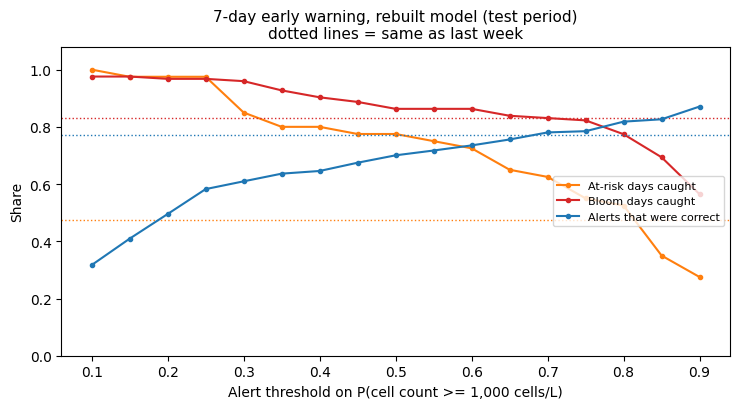

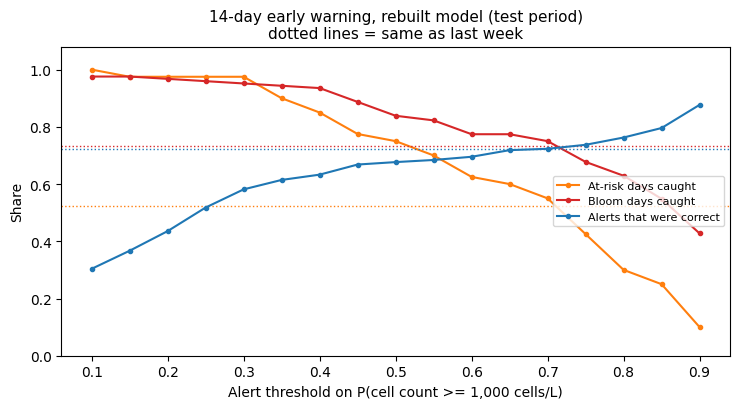

=== Early warning (counts reach 1,000 cells/L): MODEL 9 vs rebuilt, scored on Sarasota ===
Alert columns use the same number of alerts as 'same as last week'.
                                                                    auc  avg_precision  at_risk_days_caught  bloom_days_caught  alerts_correct  auc_gain_ci_low  auc_gain_ci_high  share_of_resamples_improved
horizon_days evaluation  version                                                                                                                                                                              
7            CV          MODEL 9 (Sarasota-only LightGBM)         0.854          0.807                0.492              0.825           0.709              NaN               NaN                          NaN
                         rebuilt (4 regions, upstream, logistic)  0.900          0.858                0.498              0.929           0.780            0.015             0.081                          1.0
             

In [ ]:
# MODEL 19: Early-warning model ("counts reach 1,000 cells/L"), rebuilt with the onset improvements
# MODEL 9's question, rebuilt like the onset model (upstream features, logistic regression, four regions)
# and compared with MODEL 9 on Sarasota.
# Needs: make_dataset, time_folds, res, lgbm_params, HORIZONS, TEST_START (MODELS 2-4); region_history,
# shared, TRAIN_REGIONS (MODEL 14); UPSTREAM, FINAL_FEATURES, final_model (MODEL 15).
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

N_BOOT = 1000
WIN_SHARE = 0.80
rng = np.random.default_rng(11)
EW_FEATURES = [c for c in FINAL_FEATURES if c.startswith(('last_', 'log_', 'maxlog', 'frac_', 'n_ge', 'days_',
                                                           'region_', 'own_', 'surr_', 'is_'))]
EW_FEATURES += ['doy_sin', 'doy_cos']

def region_point_table(name, box, h):
    """For each sampling day d in a region: features from day d - h, target = level on day d is >= at-risk."""
    H, levels = region_history(box)
    X = H.join(UPSTREAM[name]).join(shared.reindex(H.index))
    days = levels.index[levels.notna() & (levels.index >= cal.min() + pd.Timedelta(days=30)) & (levels.index <= cal.max())]
    T = X.reindex(days - pd.Timedelta(days=h))
    T.index = days
    for k in TRAIN_REGIONS:
        T[f'is_{k}'] = float(k == name)
    T['doy_sin'] = np.sin(2 * np.pi * days.dayofyear / 365.25)
    T['doy_cos'] = np.cos(2 * np.pi * days.dayofyear / 365.25)
    T['level'] = levels.reindex(days).values
    T['y'] = (T['level'] >= 1).astype(int)
    T['region'] = name
    return T

def alert_point(level, alert):
    hits = alert & (level >= 1)
    return {'at_risk_days_caught': alert[level == 1].mean(), 'bloom_days_caught': alert[level == 2].mean(),
            'alerts_correct': hits.sum() / max(alert.sum(), 1)}

ew_rows, ew_keep, ew_models = [], [], {}
for h in HORIZONS:
    data_h = pd.concat([region_point_table(n, b, h) for n, b in TRAIN_REGIONS.items()]).sort_index()
    X9, _ = make_dataset(h)
    sar = data_h[data_h['region'] == 'sarasota']
    days = sar.index.intersection(X9.index)
    sar, X9 = sar.loc[days], X9.loc[days]
    y, level = sar['y'].values, sar['level'].values
    pers_alert = (X9['last_bloom_level'].fillna(0) >= 1).values
    best = res[res.horizon == h].iloc[0]
    params = {**lgbm_params(best.n_estimators, best.learning_rate, best.max_depth), 'objective': 'binary'}

    # --- 19a. Whole-record cross-validation on Sarasota ---
    p9, p_new = np.full(len(y), np.nan), np.full(len(y), np.nan)
    for _, va in time_folds(days, n_splits=5, gap_days=h):
        cutoff = days[va[0]] - pd.Timedelta(days=h)
        tr9 = days < cutoff
        if y[tr9].sum() < 5:
            continue
        p9[va] = lgb.LGBMClassifier(**params).fit(X9[tr9], y[tr9]).predict_proba(X9.iloc[va])[:, 1]
        tr = data_h[data_h.index < cutoff]
        p_new[va] = final_model().fit(tr[EW_FEATURES], tr['y']).predict_proba(sar.iloc[va][EW_FEATURES])[:, 1]
    m = ~np.isnan(p9) & ~np.isnan(p_new)
    months = pd.Series(days.to_period('M'))[m].values
    pos = np.where(m)[0]
    blocks = [pos[months == mo] for mo in np.unique(months)]
    resamples = [np.concatenate([blocks[i] for i in rng.choice(len(blocks), len(blocks))]) for _ in range(N_BOOT)]
    gains = np.array([roc_auc_score(y[b], p_new[b]) - roc_auc_score(y[b], p9[b]) for b in resamples
                      if len(set(y[b])) == 2])
    ew_keep.append((gains > 0).mean() >= WIN_SHARE)
    n_alerts = pers_alert[m].sum()                  # same number of alerts as "same as last week"
    for label, p in [('MODEL 9 (Sarasota-only LightGBM)', p9), ('rebuilt (4 regions, upstream, logistic)', p_new)]:
        alert = p[m] >= np.sort(p[m])[-n_alerts]
        ew_rows.append({'horizon_days': h, 'evaluation': 'CV', 'version': label,
                        'auc': roc_auc_score(y[m], p[m]), 'avg_precision': average_precision_score(y[m], p[m]),
                        **alert_point(level[m], alert),
                        'auc_gain_ci_low': np.percentile(gains, 2.5) if 'rebuilt' in label else np.nan,
                        'auc_gain_ci_high': np.percentile(gains, 97.5) if 'rebuilt' in label else np.nan,
                        'share_of_resamples_improved': (gains > 0).mean() if 'rebuilt' in label else np.nan})
    ew_rows.append({'horizon_days': h, 'evaluation': 'CV', 'version': 'same as last week',
                    **alert_point(level[m], pers_alert[m])})

    # --- 19b. Test period (train before TEST_START - h) ---
    tr9, te = days < TEST_START - pd.Timedelta(days=h), days >= TEST_START
    p9_te = lgb.LGBMClassifier(**params).fit(X9[tr9], y[tr9]).predict_proba(X9[te])[:, 1]
    tr = data_h[data_h.index < TEST_START - pd.Timedelta(days=h)]
    new_model = final_model().fit(tr[EW_FEATURES], tr['y'])
    pn_te = new_model.predict_proba(sar[te][EW_FEATURES])[:, 1]
    n_alerts = pers_alert[te].sum()
    for label, p in [('MODEL 9 (Sarasota-only LightGBM)', p9_te), ('rebuilt (4 regions, upstream, logistic)', pn_te)]:
        alert = p >= np.sort(p)[-n_alerts]
        ew_rows.append({'horizon_days': h, 'evaluation': 'test period', 'version': label,
                        'auc': roc_auc_score(y[te], p), 'avg_precision': average_precision_score(y[te], p),
                        **alert_point(level[te], alert)})
    ew_rows.append({'horizon_days': h, 'evaluation': 'test period', 'version': 'same as last week',
                    **alert_point(level[te], pers_alert[te])})

    # --- 19c. Trade-off chart (test period): alert when P(>= 1,000 cells/L) passes a threshold ---
    grid = np.round(np.arange(0.1, 0.91, 0.05), 2)
    tro = pd.DataFrame([{'threshold': t, **alert_point(level[te], pn_te > t)} for t in grid])
    tro.to_csv(f"{OUT_DIR}/early_warning_rebuilt_tradeoff_h{h}.csv", index=False)
    pers_pt = alert_point(level[te], pers_alert[te])
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for col, color, name in [('at_risk_days_caught', 'tab:orange', 'At-risk days caught'),
                             ('bloom_days_caught', 'tab:red', 'Bloom days caught'),
                             ('alerts_correct', 'tab:blue', 'Alerts that were correct')]:
        ax.plot(tro['threshold'], tro[col], color=color, marker='o', ms=3, label=name)
        ax.axhline(pers_pt[col], color=color, ls=':', lw=1)
    ax.set_xlabel('Alert threshold on P(cell count >= 1,000 cells/L)')
    ax.set_ylabel('Share'); ax.set_ylim(0, 1.08)
    ax.set_title(f'{h}-day early warning, rebuilt model (test period)\ndotted lines = same as last week', fontsize=11)
    ax.legend(fontsize=8, loc='center right')
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/early_warning_rebuilt_tradeoff_h{h}.png", dpi=150)
    plt.show()

    # --- 19d. Deployment model (all regions, all years) ---
    ew_models[h] = final_model().fit(data_h[EW_FEATURES], data_h['y'])
    joblib.dump(ew_models[h], f"{OUT_DIR}/early_warning_rebuilt_h{h}.joblib")

ew_table = pd.DataFrame(ew_rows).set_index(['horizon_days', 'evaluation', 'version']).round(3)
ew_table.to_csv(f"{OUT_DIR}/early_warning_rebuilt_comparison.csv")
print("=== Early warning (counts reach 1,000 cells/L): MODEL 9 vs rebuilt, scored on Sarasota ===")
print("Alert columns use the same number of alerts as 'same as last week'.")
print(ew_table.to_string())
EW_REBUILT_WINS = all(ew_keep)
print("\nDecision:", f"KEEP the rebuilt model: it improves AUC at both horizons in at least {WIN_SHARE:.0%} of resamples."
      if EW_REBUILT_WINS else "Keep MODEL 9: the rebuilt model doesn't improve AUC consistently at both horizons.")
